# keff tuning observables — run by run (58 pp runs) and K0s check

Only what is needed to tune keff:

* **N+/N−** of tracks and the **charge-odd rDCA** offset (single-track QA, available for every production run),
* the proposed per-run keff from them, and a **GEM-current law** for runs without QA,
* K0s mass in pT bins and the π⁺/π⁻ yield ratio of the K0s daughters on the stored clusters (no new reco).

**Definitions.** `keff` is the absolute keff in the units of the keff-variant re-reco (nominal law 0.397·I+0.255 South, 0.4065·I+0.288 North). The *tuned* keff is the value at which the sine-removed rDCA q⁺−q⁻ offset vanishes; it was measured on 8 runs with real re-reco at 0.93/1.00/1.07 × nominal and the QA observables are calibrated against it. It is **not** relative to the CDB applied keff, which also contains a per-segment current scaling (up to +9 %).

**Parametrisation proposed.** run-by-run keff from N+/N− (or rDCA) for every run with QA; for any other run a linear law in the run-average GEM current, fitted to the tuned values.

**K0s configurations on the stored clusters — read this before interpreting them.** The stored clusters were reconstructed with the CDB keff, so the CDB space-charge correction (the dominant term) is already inside them and is **not** changed here. Only the *MLP map* is added, with its keff input varied (map ∝ keff):
0. CDB reco, no map (baseline)
1. + MLP map, keff input = CDB applied keff (**benchmark**)
2. + MLP map, keff input = tuned from N+/N−
3. + MLP map, keff input = tuned from rDCA
4. + MLP map, keff input = law(I_GEM)

So 0 ↔ 1 is the effect of the map; 1 ↔ 2/3/4 is the effect of rescaling **only the small map**. This is **not a test of the reco keff**: a real keff change rescales the whole CDB correction too, which is what the re-reco jobs do.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
T = Path('/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking')
KLIST = T/'spy/input/tpc_qa_plots_pp/keff_list_58runs.csv'; FEAT = T/'spy/input/tpc_qa_plots_pp/keff_run_features.csv'
KZERO = T/'ml/trackrefit/tenruns/keff_zero_pt.npy'; KS = T/'ml/output/keffscan'
plt.rcParams.update({'font.size': 15, 'axes.grid': True, 'grid.alpha': .3, 'figure.dpi': 80})
KEFF_CDB = {'79513': (1.58948, 1.59237), '79516': (1.40234, 1.40787), '79529': (1.60427, 1.5751), '79509': (1.85614, 1.86216), '81558': (4.41238, 4.45548), '81562': (2.97449, 2.95489), '81566': (2.66729, 2.58951), '80895': (3.35641, 3.34803)}  # CDB applied (segment-10) keff S, N
L = pd.read_csv(KLIST); F = pd.read_csv(FEAT, index_col=0); print(len(L), 'runs;', (L.flag.fillna('') == '').sum(), 'unflagged')

58 runs; 40 unflagged


# HOW TO TUNE keff — recipe (read this first; details below)

**Goal.** Get the keff of a run from track QA that exists for every production run, without a re-reco scan. Two observables: the charge-odd **rDCA offset** (q+ minus q−, phi sine removed) and the **charge balance** ln(N+/N−) of the tracks. The figure and formulas below come from the cell directly under this text.

| | O+O (run3oo, 37 runs, 3 real re-reco keff points per run) | pp (8 runs, real re-reco 0.93/1.00/1.07) |
|---|---|---|
| target | keff factor of the **K0s width optimum**, relative to the run's base keff | keff where the rDCA odd offset vanishes, relative to the nominal law |
| rDCA | response **+6.5 cm per unit keff factor**; f0 (rDCA zero) = 1.050 − 0.179·odd0_cdb, **r = −0.97**; K0s optimum = f0 − 0.08 | the target is defined by rDCA zero; the QA half-difference minus its trend vs GEM current predicts it with LOO 4.3 % |
| charge balance | response ≈ 0 (ln N+/N− moves by −0.015 per unit factor: not a lever); run-to-run it correlates weakly with f0 (r ≈ 0.4) | ln(N+/N−) minus its trend vs I: tuned/nominal − 1 = −1.2 % + 0.51·x, **r = 0.88, LOO 2.9 %** (better than rDCA) |

**Procedure in O+O (production-like): rDCA.** (1) measure odd0 on the CDB reco of the run, sides averaged, pT 0.3–1.5 GeV, |η|<1.2, nclu>12, phi sine removed (`obs_oo.py`); (2) keff factor = 0.970 − 0.179·odd0_cdb [cm] applied to the run's base keff (a typical odd0_cdb = −0.42 gives ×1.045); (3) inverse: a run whose keff is known to be best at factor f has odd0_cdb = (f − 0.970)/(−0.179).

**Charge balance.** In pp it is the better predictor (use the pp formula, after removing the I-trend). In O+O the same observable has no response to keff within ±15 % and only weak run-to-run information, so rDCA should be used there. Caveat: the pp calibration has 8 runs and the O+O formula is only a pooled shift (0.08) between rDCA zero and the K0s optimum; the ~25 highest-keff O+O runs are missing from the fit.

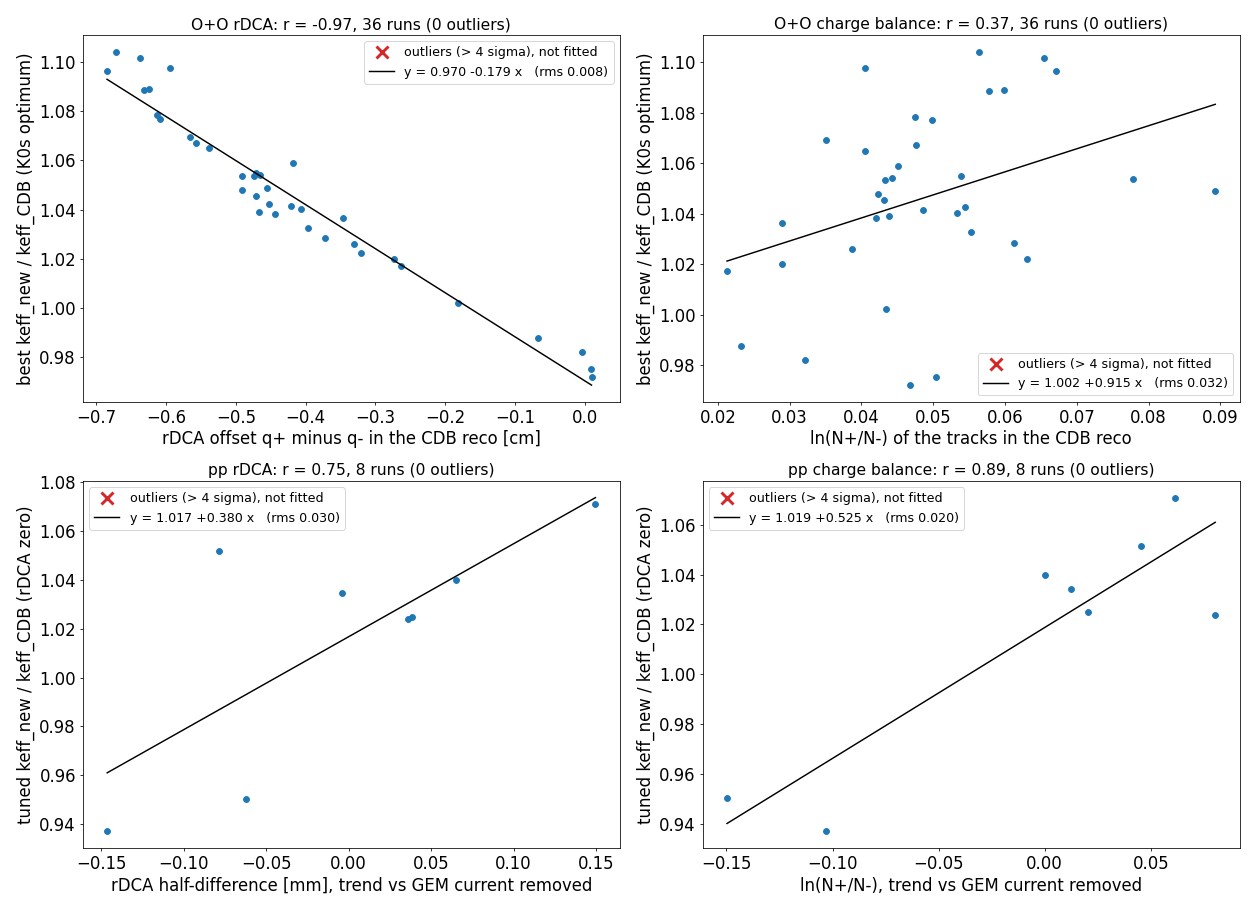

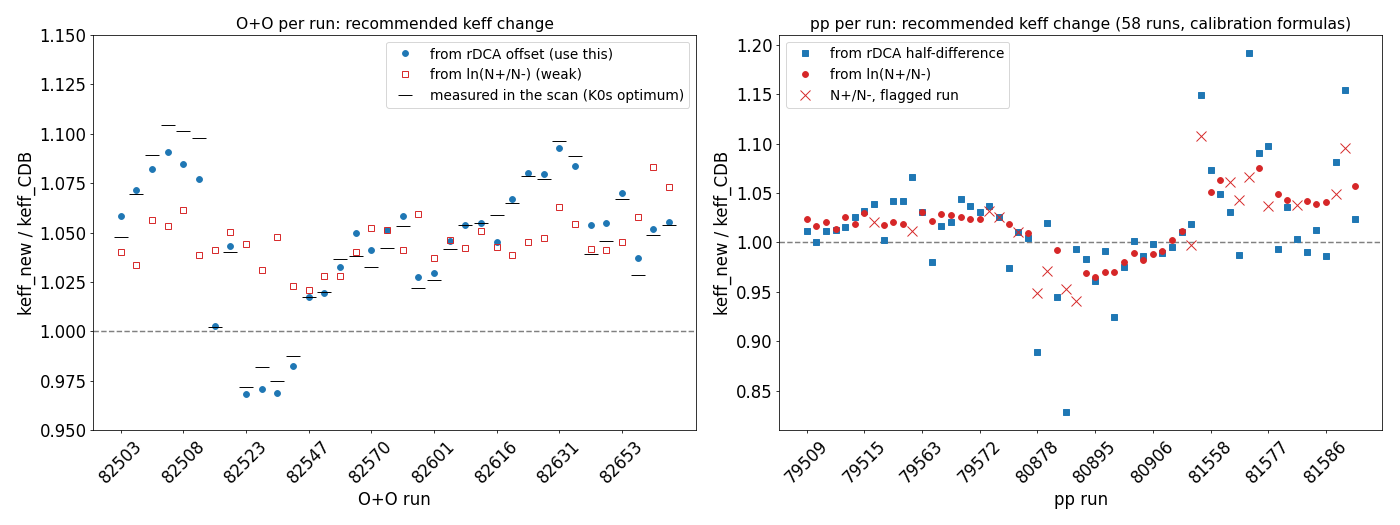

O+O rDCA : keff_new/keff_CDB = 0.970 -0.179 * rDCA_offset_CDB[cm];  inverse offset = (ratio - 0.970)/-0.179
O+O charge balance : keff_new/keff_CDB = 1.002 +0.91 * ln(N+/N-)  (weak)
pp  rDCA : keff_new/keff_CDB = 1.017 +0.380 * halfdiff_resid[mm]
pp  charge balance : keff_new/keff_CDB = 1.019 +0.525 * ln(N+/N-)_resid


In [ ]:
# How to tune keff, same four calibration plots for O+O and pp, then per-run recommendations.  Everything is keff_new / keff_CDB (CDB base keff).
KS2 = T/'ml/newgain/v0keffscan'; R = pd.read_csv(KS2/'fit_obs_perrun.csv'); SHIFT = 0.08; NSIG = 4.0
plt.rcParams.update({'font.size': 17, 'axes.titlesize': 16})
def rfit(x, y):                                  # linear fit with iterative sigma clipping; returns coef, keep mask, rms of kept
    x, y = np.asarray(x, float), np.asarray(y, float); k = np.isfinite(x) & np.isfinite(y)
    clip = k.sum() >= 15                                  # clipping only with enough points (not for the 8 pp runs)
    for _ in range(10):
        b = np.polyfit(x[k], y[k], 1); r = y - np.polyval(b, x); sg = 1.4826*np.median(np.abs(r[k] - np.median(r[k]))); kn = np.isfinite(r) & (np.abs(r) < NSIG*max(sg, 1e-9))
        if (kn == k).all() or not clip: break
        k = kn
    return b, k, np.std(r[k])
def calib(a, x, y, names, xl, yl, ttl):
    b, k, rms = rfit(x, y); a.plot(x[k], y[k], 'o', color='C0'); a.plot(x[~k], y[~k], 'x', color='C3', ms=12, mew=3, label='outliers (> %.0f sigma), not fitted' % NSIG)
    [a.annotate(str(n), (xx_, yy_), fontsize=11) for n, xx_, yy_, kk in zip(names, x, y, k) if not kk]
    xs = np.linspace(np.nanmin(x[k]), np.nanmax(x[k]), 5); a.plot(xs, np.polyval(b, xs), 'k-', label='y = %.3f %+.3f x   (rms %.3f)' % (b[1], b[0], rms)); a.set_xlabel(xl); a.set_ylabel(yl); a.legend(fontsize=13); a.set_title('%s: r = %.2f, %d runs (%d outliers)' % (ttl, np.corrcoef(x[k], y[k])[0, 1], k.sum(), (~k).sum())); return b, k, rms
# ---- O+O: per run (two sides averaged); y = best keff_new/keff_CDB = rDCA zero of the scan - 0.08 (K0s optimum)
Rm = R.groupby('run').mean(numeric_only=True); Rm = Rm[Rm.odd0_f0.between(.9, 1.3)]; yo = Rm.odd0_f0 - SHIFT
# ---- pp: per run, tuned keff (rDCA zero, real re-reco) / CDB base keff, two sides averaged; observables minus their trend vs GEM current
KO = np.load(KZERO, allow_pickle=True).item(); Lb = L.set_index('run'); yp = {}
for (r, s_), v in KO.items():
    r = int(r)
    if r in Lb.index and r in F.index: yp.setdefault(r, []).append(v['k_off']/Lb.loc[r, 'keff_base_' + 'SN'[s_]])
G = F.copy()
for c in ('south', 'north', 'lnr'): ok = G[c].notna(); G[c + '_rI'] = G[c] - np.polyval(np.polyfit(G.I[ok], G[c][ok], 2), G.I)
G['rd_rI'] = .5*(G.south_rI + G.north_rI); cal = G.loc[sorted(yp)].copy(); cal['y'] = [np.mean(yp[r]) for r in cal.index]
fig, ax = plt.subplots(2, 2, figsize=(18, 13))
bo, ko_, _ = calib(ax[0, 0], Rm.odd0_cdb.values, yo.values, Rm.index.astype(int), 'rDCA offset q+ minus q- in the CDB reco [cm]', 'best keff_new / keff_CDB (K0s optimum)', 'O+O rDCA')
bl, kl_, _ = calib(ax[0, 1], Rm.lnr_cdb.values, yo.values, Rm.index.astype(int), 'ln(N+/N-) of the tracks in the CDB reco', 'best keff_new / keff_CDB (K0s optimum)', 'O+O charge balance')
bpr, kpr, _ = calib(ax[1, 0], cal.rd_rI.values, cal.y.values, cal.index, 'rDCA half-difference [mm], trend vs GEM current removed', 'tuned keff_new / keff_CDB (rDCA zero)', 'pp rDCA')
bpl, kpl, _ = calib(ax[1, 1], cal.lnr_rI.values, cal.y.values, cal.index, 'ln(N+/N-), trend vs GEM current removed', 'tuned keff_new / keff_CDB (rDCA zero)', 'pp charge balance')
ax[0, 0].set_xlim(right=.05); fig.tight_layout(); plt.show()
# ---- per-run recommendation
Ro = Rm.copy(); Ro['new_rdca'] = np.polyval(bo, Ro.odd0_cdb); Ro['new_lnr'] = np.polyval(bl, Ro.lnr_cdb)
fl = L.flag.fillna('') != ''; x = np.arange(len(L)); xo = np.arange(len(Ro)); fig, ax = plt.subplots(1, 2, figsize=(20, 7.5))
a = ax[0]; a.axhline(1, color='gray', ls='--'); a.plot(xo, Ro.new_rdca, 'o', color='C0', label='from rDCA offset (use this)'); a.plot(xo, Ro.new_lnr, 's', mfc='none', color='C3', label='from ln(N+/N-) (weak)'); a.plot(xo, yo, 'k_', ms=14, label='measured in the scan (K0s optimum)')
a.set_xticks(xo[::4]); a.set_xticklabels(Ro.index[::4].astype(int), rotation=45); a.set_xlabel('O+O run'); a.set_ylabel('keff_new / keff_CDB'); a.set_ylim(.95, 1.15); a.legend(fontsize=14); a.set_title('O+O per run: recommended keff change')
a = ax[1]; a.axhline(1, color='gray', ls='--'); pn = np.polyval(bpl, L.run.map(G.lnr_rI).values); pr = np.polyval(bpr, L.run.map(G.rd_rI).values)
a.plot(x, pr, 's', color='C0', label='from rDCA half-difference'); a.plot(x[~fl], pn[~fl], 'o', color='C3', label='from ln(N+/N-)'); a.plot(x[fl], pn[fl], 'x', color='C3', ms=10, label='N+/N-, flagged run'); a.plot(x[~fl & False], x[~fl & False])
a.set_xticks(x[::6]); a.set_xticklabels(L.run[::6], rotation=45); a.set_xlabel('pp run'); a.set_ylabel('keff_new / keff_CDB'); a.legend(fontsize=14); a.set_title('pp per run: recommended keff change (58 runs, calibration formulas)')
fig.tight_layout(); plt.show()
print('O+O rDCA : keff_new/keff_CDB = %.3f %+.3f * rDCA_offset_CDB[cm];  inverse offset = (ratio - %.3f)/%.3f' % (bo[1], bo[0], bo[1], bo[0]))
print('O+O charge balance : keff_new/keff_CDB = %.3f %+.2f * ln(N+/N-)  (weak)' % (bl[1], bl[0]))
print('pp  rDCA : keff_new/keff_CDB = %.3f %+.3f * halfdiff_resid[mm]' % (bpr[1], bpr[0]))
print('pp  charge balance : keff_new/keff_CDB = %.3f %+.3f * ln(N+/N-)_resid' % (bpl[1], bpl[0]))

> **Note on the per-run plot above.** The black marks ("measured in the scan") are the rDCA zero crossing of the scan minus 0.08, a proxy for the K0s optimum derived from the 82630 K0s scan, not a measured K0s optimum. Their agreement with the blue points is therefore by construction. The measured K0s optima (67 O+O runs, 24 pp runs) and the real test of the proxy are in the section "K0s significance and correlations" below.

## pp on the stored clusters (8 runs, no real re-reco): offline keff test, whole correction rescaled

Offline keff test on the **stored CDB clusters**: each cluster is shifted by C (keff_CDB/3.627)(f - 1) sum_k B_k(r, phi, z, side), the Garfield density-group basis summed into the full space-charge distortion, f = keff_new/keff_CDB, C = 0.7 (calibrated on the real O+O rDCA scan). This rescales the **whole** correction like a real keff change does, unlike the earlier map-only scale of the MLP residual (which could not respond and is removed). Then the K0s width per side class versus f gives the K0s optimum, shown against the QA observables as for O+O. It is a model (Garfield basis, one global C), so it is less reliable than the real scan, which replaces it.

**Validation caveat (checked against the real O+O scan of 82630).** Real re-reco: K0s sigma (pT 0.5-1.2) = 7.00 / 5.91 / 5.55 MeV at x0.95 / 1.05 / 1.15 (still falling at +15 %). This offline model, for any C, gives a minimum near x1.05 and rises after it (7.0 / 6.7 / 6.9 at C = 0.7); a larger C only moves the optimum towards 1 and cannot reproduce the real steepness (ratio sigma(0.95)/sigma(1.05) real 1.18, offline 1.05-1.09). So the offline optima are **not validated** and should not be used to set keff; use the real pp scan.

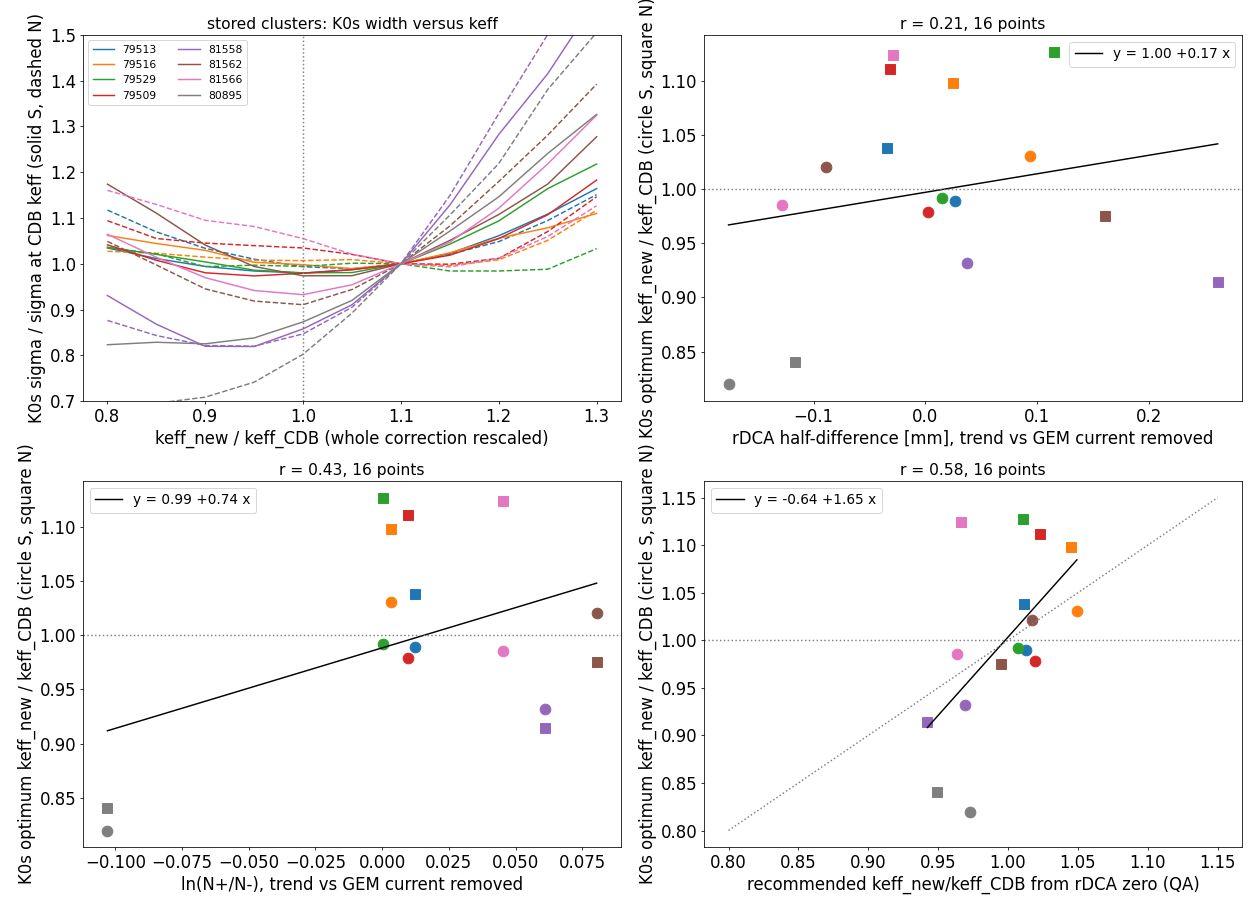

      run side    opt   sig1  sigmin     rd    lnr   rdca   npnm
0   79513    S  0.989  6.323   6.195  0.027  0.012  1.013  0.995
1   79513    N  1.039  5.708   5.647 -0.034  0.012  1.011  0.993
2   79516    S  1.031  6.088   6.023  0.093  0.003  1.049  1.003
3   79516    N  1.098  5.988   5.964  0.024  0.003  1.045  0.999
4   79529    S  0.992  6.351   6.224  0.015  0.000  1.007  0.987
5   79529    N  1.127  6.467   6.365  0.115  0.000  1.010  0.990
6   79509    S  0.979  6.727   6.548  0.002  0.010  1.019  1.008
7   79509    N  1.112  6.360   6.354 -0.032  0.010  1.023  1.012
8   81558    S  0.932  9.497   7.780  0.037  0.061  0.969  0.972
9   81558    N  0.914  8.680   7.117  0.262  0.061  0.942  0.945
10  81562    S  1.021  7.507   7.309 -0.089  0.080  1.017  1.078
11  81562    N  0.975  7.027   6.398  0.161  0.080  0.995  1.054
12  81566    S  0.985  7.168   6.684 -0.128  0.045  0.964  1.018
13  81566    N  1.125  6.777   6.730 -0.029  0.045  0.966  1.021
14  80895    S  0.820  9.

In [ ]:
# Stored-cluster pp  offline keff test on the stored CDB clusters (8 pp runs): whole SC distortion rescaled, not the MLP residual
# shift = C (keff_CDB/3.627)(f-1) sum_k B_k (Garfield density-group basis, C = 0.7 from the real O+O rDCA scan); f = keff_new/keff_CDB; K0s width per side class. Script: ml/cm_k0s/k0s_keff_offline_pp.py
plt.rcParams.update({'font.size': 17, 'axes.titlesize': 16}); G = F.copy()
for c in ('south', 'north', 'lnr'): ok = G[c].notna(); G[c + '_rI'] = G[c] - np.polyval(np.polyfit(G.I[ok], G[c][ok], 2), G.I)
def vert(f, s):
    k = np.isfinite(s); f, s = f[k], s[k]; i = int(np.argmin(s)); lo, hi = max(0, i-3), min(len(f), i+4); a, b, c = np.polyfit(f[lo:hi], s[lo:hi], 2); return -b/(2*a) if a > 0 else np.nan
rows = []; col = {r: plt.cm.tab10(i) for i, r in enumerate(KEFF_CDB)}; fig, ax = plt.subplots(2, 2, figsize=(18, 13)); Z = {}
for r in KEFF_CDB:
    z = np.load(KS/('k0s_offpp_%s.npz' % r)); Z[r] = z; l = L[L.run == int(r)].iloc[0]
    for sd, g in enumerate('SN'):
        sg = z['sig' + g]; rows.append(dict(run=r, side=g, opt=vert(z['FS'], sg), sig1=sg[6], sigmin=np.nanmin(sg), rd=G.loc[int(r), ('south', 'north')[sd] + '_rI'], lnr=G.loc[int(r), 'lnr_rI'], rdca=l['keff_%s_rDCA' % g]/KEFF_CDB[r][sd], npnm=l['keff_%s_NpNm' % g]/KEFF_CDB[r][sd]))
        ax[0, 0].plot(z['FS'], sg/sg[6], '-' if g == 'S' else '--', color=col[r], label=r if g == 'S' else None)
Q = pd.DataFrame(rows); a = ax[0, 0]; a.axvline(1, color='gray', ls=':'); a.set_xlabel('keff_new / keff_CDB (whole correction rescaled)'); a.set_ylabel('K0s sigma / sigma at CDB keff (solid S, dashed N)'); a.legend(fontsize=11, ncol=2); a.set_title('stored clusters: K0s width versus keff'); a.set_ylim(.7, 1.5)
for a, c, xl in ((ax[0, 1], 'rd', 'rDCA half-difference [mm], trend vs GEM current removed'), (ax[1, 0], 'lnr', 'ln(N+/N-), trend vs GEM current removed'), (ax[1, 1], 'rdca', 'recommended keff_new/keff_CDB from rDCA zero (QA)')):
    for _, t in Q.iterrows(): a.plot(t[c], t.opt, 'os'[t.side == 'N'], color=col[t.run], ms=11)
    k = Q.opt.between(.7, 1.3); b = np.polyfit(Q[c][k], Q.opt[k], 1); xs = np.linspace(Q[c].min(), Q[c].max(), 5); a.plot(xs, np.polyval(b, xs), 'k-', label='y = %.2f %+.2f x' % (b[1], b[0])); a.axhline(1, color='gray', ls=':'); a.legend(fontsize=14)
    a.set_xlabel(xl); a.set_ylabel('K0s optimum keff_new / keff_CDB (circle S, square N)'); a.set_title('r = %.2f, %d points' % (np.corrcoef(Q[c][k], Q.opt[k])[0, 1], k.sum()))
ax[1, 1].plot([.8, 1.15], [.8, 1.15], 'gray', ls=':'); fig.tight_layout(); plt.show()
print(Q.round(3).to_string())

In [2]:
cols = ['run', 'I_S', 'I_N', 'lnr', 'lnr_res', 'y_NpNm', 'y_rDCA', 'keff_base_S', 'keff_base_N', 'keff_S_NpNm', 'keff_N_NpNm', 'keff_S_rDCA', 'keff_N_rDCA', 'flag']
display(L[cols].round(3).style.format(precision=3).set_properties(**{'font-size': '10pt'}))

,run,I_S,I_N,lnr,lnr_res,y_NpNm,y_rDCA,keff_base_S,keff_base_N,keff_S_NpNm,keff_N_NpNm,keff_S_rDCA,keff_N_rDCA,flag
0,79509,4.103,3.958,0.086,0.010,-0.007,0.004,1.841,1.852,1.872,1.884,1.892,1.904,nan
1,79510,3.952,3.798,0.072,-0.005,-0.014,-0.007,1.778,1.785,1.798,1.806,1.811,1.819,nan
2,79511,3.769,3.614,0.082,0.004,-0.009,0.008,1.708,1.712,1.735,1.741,1.765,1.771,nan
3,79512,3.564,3.408,0.067,-0.011,-0.017,0.018,1.629,1.630,1.641,1.645,1.700,1.704,nan
4,79513,3.361,3.204,0.090,0.012,-0.005,0.013,1.550,1.550,1.581,1.582,1.610,1.610,nan
5,79514,3.197,3.049,0.077,0.000,-0.011,0.026,1.490,1.488,1.507,1.510,1.565,1.568,nan
6,79515,3.064,2.911,0.096,0.020,-0.001,0.027,1.438,1.433,1.470,1.470,1.512,1.512,nan
7,79516,2.934,2.785,0.078,0.003,-0.010,0.036,1.390,1.385,1.406,1.406,1.471,1.472,rules disagree
8,79527,3.803,3.548,0.075,-0.002,-0.013,-0.026,1.714,1.691,1.742,1.708,1.719,1.685,nan
9,79528,3.598,3.360,0.082,0.004,-0.009,0.016,1.637,1.616,1.668,1.638,1.710,1.680,nan


## keff vs GEM current and the size of the correction

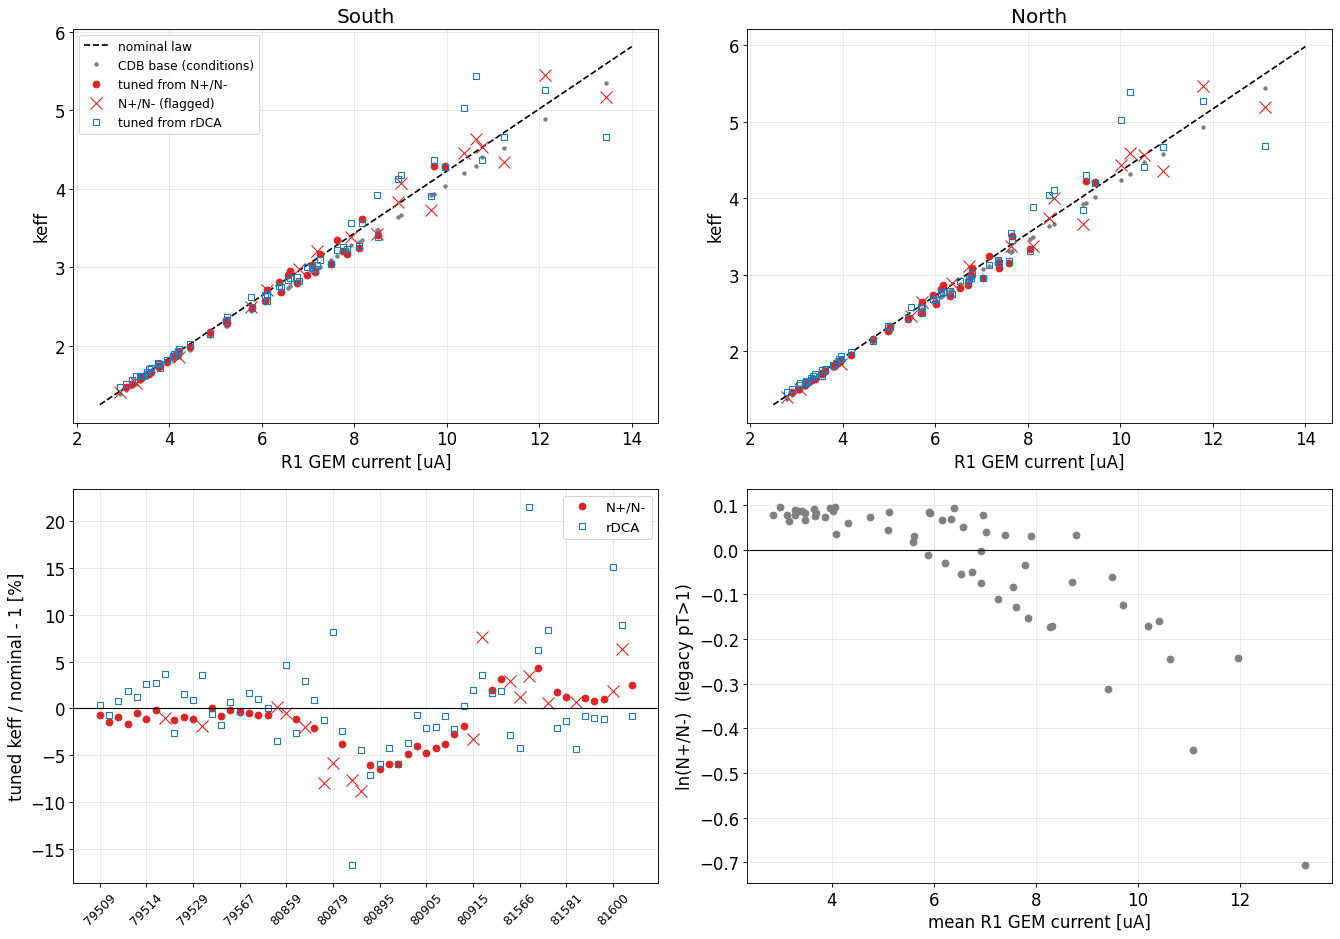

In [3]:
kn = lambda I, s: (0.397*I + 0.255) if s == 0 else (0.4065*I + 0.288)
flag = L.flag.fillna('') != ''; fig, ax = plt.subplots(2, 2, figsize=(17, 12)); Ig = np.linspace(2.5, 14, 50)
for s, (nm, c) in enumerate((('South', 'S'), ('North', 'N'))):
    a = ax[0, s]; a.plot(Ig, kn(Ig, s), 'k--', label='nominal law'); a.plot(L['I_'+c], L['keff_base_'+c], '.', color='gray', label='CDB base (conditions)')
    a.plot(L['I_'+c][~flag], L['keff_%s_NpNm' % c][~flag], 'o', color='C3', label='tuned from N+/N-'); a.plot(L['I_'+c][flag], L['keff_%s_NpNm' % c][flag], 'x', color='C3', ms=10, label='N+/N- (flagged)')
    a.plot(L['I_'+c], L['keff_%s_rDCA' % c], 's', mfc='none', color='C0', label='tuned from rDCA'); a.set_title(nm); a.set_xlabel('R1 GEM current [uA]'); a.set_ylabel('keff')
ax[0, 0].legend(fontsize=11); x = np.arange(len(L))
ax[1, 0].plot(x[~flag], 100*L.y_NpNm[~flag], 'o', color='C3', label='N+/N-'); ax[1, 0].plot(x[flag], 100*L.y_NpNm[flag], 'x', color='C3', ms=10); ax[1, 0].plot(x, 100*L.y_rDCA, 's', mfc='none', color='C0', label='rDCA'); ax[1, 0].axhline(0, color='k', lw=1)
ax[1, 0].set_xticks(x[::5]); ax[1, 0].set_xticklabels(L.run[::5], rotation=45, fontsize=11); ax[1, 0].set_ylabel('tuned keff / nominal - 1 [%]'); ax[1, 0].legend(fontsize=12)
ax[1, 1].plot(F.I, F.lnr, 'o', color='gray'); ax[1, 1].set_xlabel('mean R1 GEM current [uA]'); ax[1, 1].set_ylabel('ln(N+/N-)  (legacy pT>1)'); ax[1, 1].axhline(0, color='k', lw=1)
fig.tight_layout(); plt.show()

## Calibration of the QA observables against the real-reco tuned keff (8 runs)

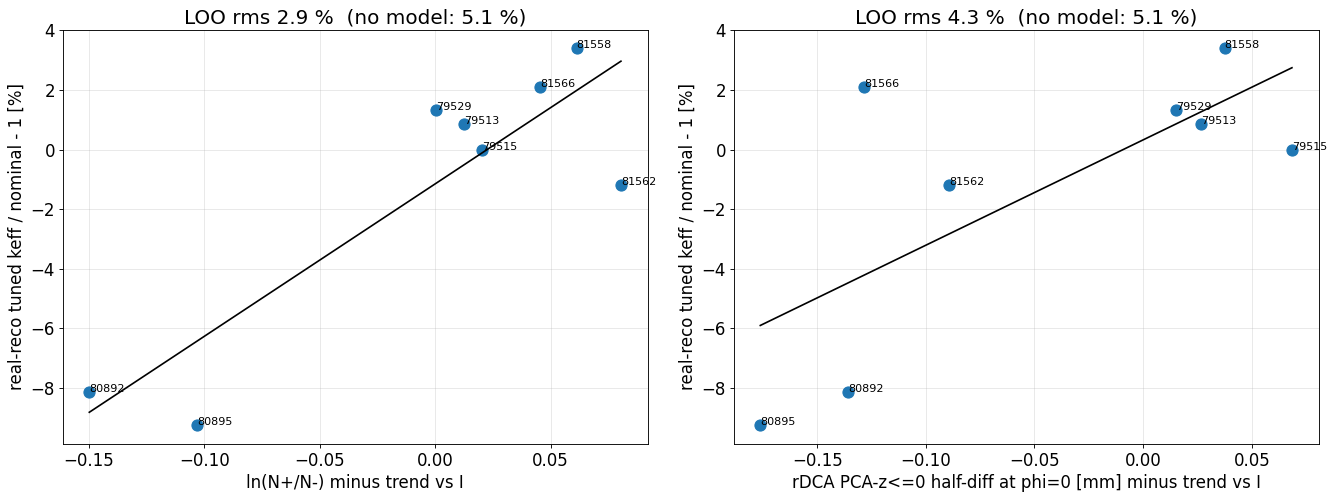

In [4]:
KO = np.load(KZERO, allow_pickle=True).item(); y = {}
for (r, s), v in KO.items(): y.setdefault(int(r), []).append(v['k_off']/v['kn'] - 1)
y = {r: np.mean(v) for r, v in y.items() if r in F.index}; cal = F.loc[sorted(y)].copy(); cal['y'] = [y[r] for r in cal.index]
for c in ('south', 'lnr'):
    ok = F[c].notna(); p = np.polyfit(F.I[ok], F[c][ok], 2); F[c+'_rI'] = np.nan; F.loc[ok, c+'_rI'] = F[c][ok] - np.polyval(p, F.I[ok])
cal = F.loc[sorted(y)].copy(); cal['y'] = [y[r] for r in cal.index]
def loo(col):
    X = np.c_[np.ones(len(cal)), cal[col].values]; t = cal.y.values; e = []
    for i in range(len(t)): m = np.arange(len(t)) != i; b = np.linalg.lstsq(X[m], t[m], rcond=None)[0]; e.append(t[i] - X[i]@b)
    return np.linalg.lstsq(X, t, rcond=None)[0], np.sqrt(np.mean(np.square(e)))
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5)); const = np.sqrt(np.mean([(cal.y.values[i] - np.delete(cal.y.values, i).mean())**2 for i in range(len(cal))]))
for a, col, ttl in zip(ax, ('lnr_rI', 'south_rI'), ('ln(N+/N-) minus trend vs I', 'rDCA PCA-z<=0 half-diff at phi=0 [mm] minus trend vs I')):
    b, l = loo(col); a.plot(cal[col], 100*cal.y, 'o', ms=10)
    for r in cal.index: a.annotate(str(r), (cal.loc[r, col], 100*cal.loc[r, 'y']), fontsize=10)
    xx = np.linspace(cal[col].min(), cal[col].max(), 20); a.plot(xx, 100*(b[0] + b[1]*xx), 'k-'); a.set_xlabel(ttl); a.set_ylabel('real-reco tuned keff / nominal - 1 [%]'); a.set_title('LOO rms %.1f %%  (no model: %.1f %%)' % (100*l, 100*const))
fig.tight_layout(); plt.show()

## GEM-current law for runs without QA

In [5]:
import json
LAW = json.load(open(T/'spy/input/tpc_qa_plots_pp/keff_law.json'))
print('keff = a + b*I_GEM (unflagged runs, fitted to the tuned values):')
for k, (a_, b_, rms) in LAW.items(): print('  %-10s keff = %.4f + %.4f * I   (rms about law %.3f)' % (k, a_, b_, rms))
print('nominal law used for the keff scan: S 0.255 + 0.397 I ; N 0.288 + 0.4065 I')
def keff_final(run=None, I_S=None, I_N=None):
    # run-by-run tuned keff (N+/N-) if the run has QA, else the law from the GEM current
    if run is not None and run in set(L.run):
        l = L[L.run == run].iloc[0]; return l.keff_S_NpNm, l.keff_N_NpNm, 'run-by-run'
    return LAW['S_NpNm'][0] + LAW['S_NpNm'][1]*I_S, LAW['N_NpNm'][0] + LAW['N_NpNm'][1]*I_N, 'law(I)'
print(keff_final(81558), keff_final(None, 5.0, 4.8))

keff = a + b*I_GEM (unflagged runs, fitted to the tuned values):
  S_NpNm     keff = 0.2475 + 0.3923 * I   (rms about law 0.087)
  S_rDCA     keff = 0.2938 + 0.3861 * I   (rms about law 0.081)
  N_NpNm     keff = 0.2786 + 0.4020 * I   (rms about law 0.085)
  N_rDCA     keff = 0.3243 + 0.3955 * I   (rms about law 0.079)
nominal law used for the keff scan: S 0.255 + 0.397 I ; N 0.288 + 0.4065 I
(4.290949636914113, 4.212092570343929, 'run-by-run') (2.208832166220802, 2.208067081297579, 'law(I)')


## K0s on the stored clusters: mass in pT bins and pi+/pi- yield ratio

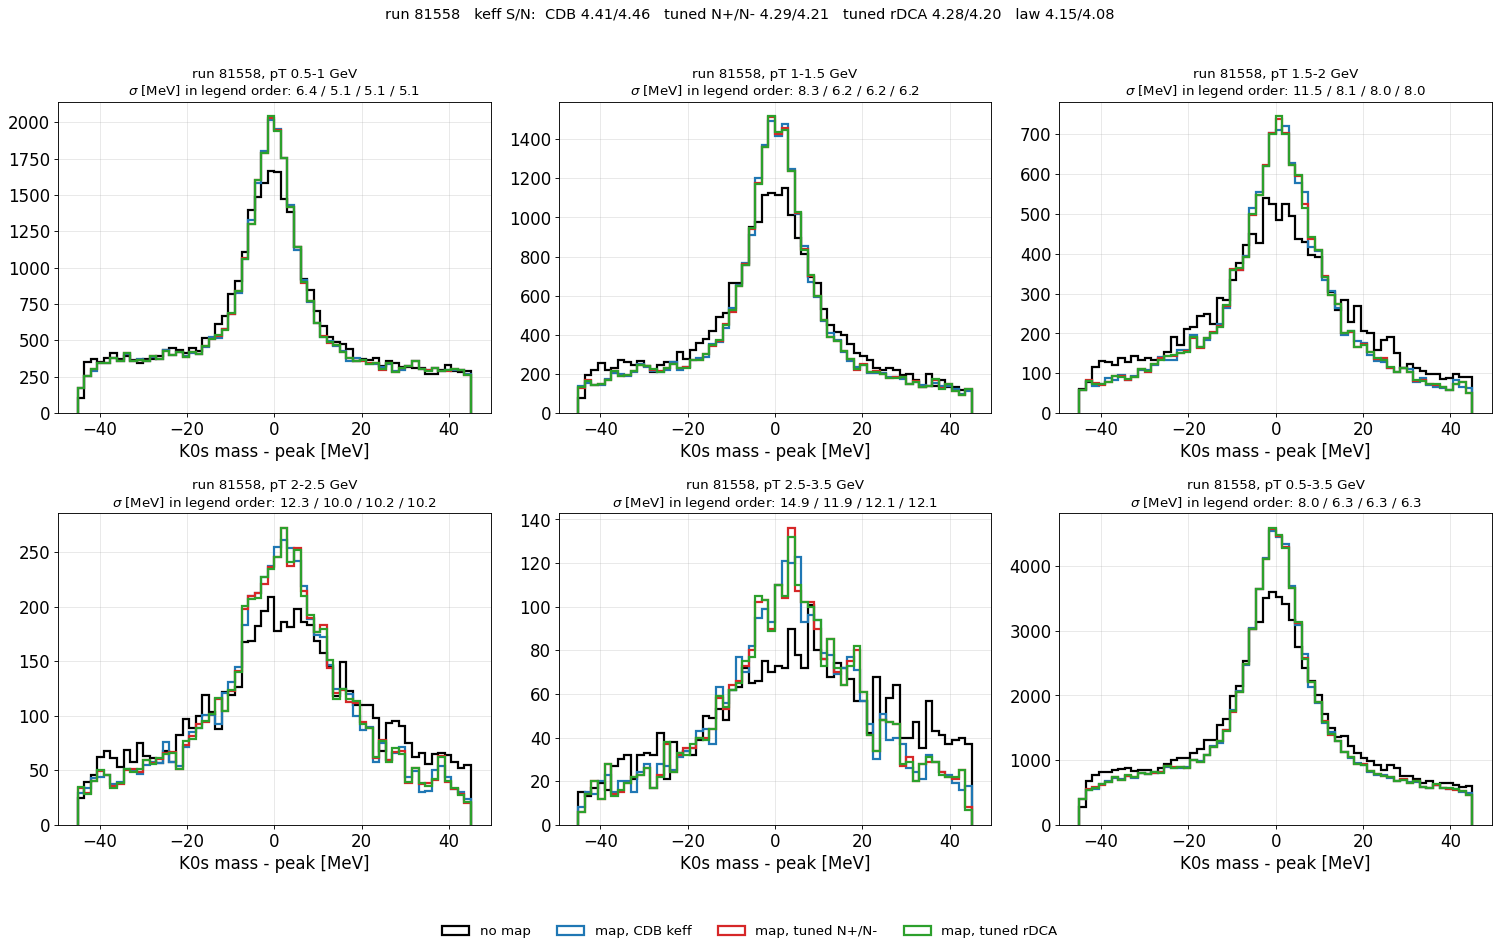

In [6]:
PDG = 497.611; PB = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5, 3.5]; RUNS_K = ['79513', '79529', '79509', '79516', '81566', '81562', '80895', '81558']
TAB = {r: np.load(KS/('tab_%s.npz' % r)) for r in RUNS_K}
LAB = ['CDB reco, no map', 'CDB reco + MLP map, map keff input = CDB applied (benchmark)', 'CDB reco + MLP map, map keff input = tuned (N+/N-)', 'CDB reco + MLP map, map keff input = tuned (rDCA)', 'CDB reco + MLP map, map keff input = law(I_GEM)']
COL = ['k', 'C0', 'C3', 'C2', 'C1']
from scipy.optimize import curve_fit
def gfit(x, lo=-45, hi=45):
    h, e = np.histogram(x, bins=np.arange(lo, hi + .5, 1.)); c = .5*(e[1:] + e[:-1]); f = lambda t, a, m, s, b0, b1: a*np.exp(-.5*((t - m)/s)**2) + b0 + b1*t
    try: p, _ = curve_fit(f, c, h, p0=[h.max(), 0, 8, h.min(), 0], maxfev=4000); return abs(p[2]), p
    except Exception: return np.nan, None
def pick(run, i, lo, hi): d = TAB[run]; m = (d['vpt'] >= lo) & (d['vpt'] < hi); return d['m'][i][m]
def peaks(run, cfgs=(0, 1, 2, 3)):
    fig, ax = plt.subplots(2, 3, figsize=(19, 12)); bins = [(0.5, 1.0), (1.0, 1.5), (1.5, 2.0), (2.0, 2.5), (2.5, 3.5), (0.5, 3.5)]; short = ['no map', 'map, CDB keff', 'map, tuned N+/N-', 'map, tuned rDCA', 'map, law(I)']; hh = {}
    for a, (lo, hi) in zip(ax.flat, bins):
        sg = []
        for i in cfgs:
            x = pick(run, i, lo, hi); s, _ = gfit(x); sg.append(s); _, _, hd = a.hist(x, bins=np.arange(-45, 45.5, 1.5), histtype='step', color=COL[i], lw=2); hh[i] = hd[0]
        a.set_title('run %s, pT %.2g-%.2g GeV\n$\\sigma$ [MeV] in legend order: %s' % (run, lo, hi, ' / '.join('%.1f' % v for v in sg)), fontsize=12); a.set_xlabel('K0s mass - peak [MeV]')
    k = TAB[run]['keff']; fig.suptitle('run %s   keff S/N:  CDB %.2f/%.2f   tuned N+/N- %.2f/%.2f   tuned rDCA %.2f/%.2f   law %.2f/%.2f' % ((run,) + tuple(k[1:].ravel())), fontsize=13)
    fig.legend([hh[i] for i in cfgs], [short[i] for i in cfgs], loc='lower center', ncol=4, fontsize=12, frameon=False); fig.tight_layout(rect=[0, 0.06, 1, 0.97]); plt.show()
peaks('81558')

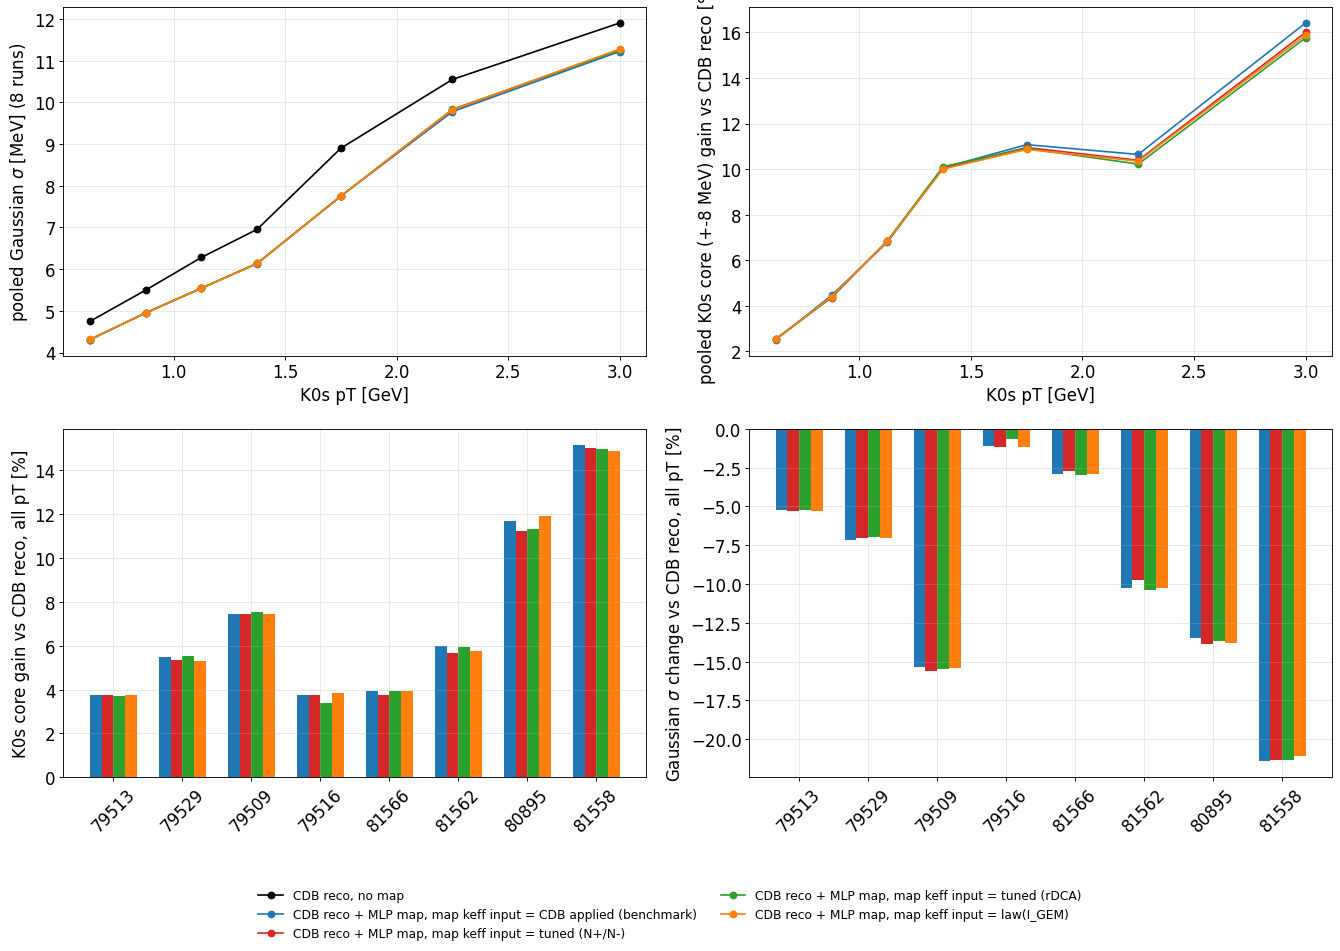

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(17, 12)); pc = .5*(np.array(PB[1:]) + np.array(PB[:-1]))
allm = {i: np.concatenate([TAB[r]['m'][i] for r in RUNS_K]) for i in range(5)}; allp = np.concatenate([TAB[r]['vpt'] for r in RUNS_K])
sg = {i: np.array([gfit(allm[i][(allp >= lo) & (allp < hi)])[0] for lo, hi in zip(PB[:-1], PB[1:])]) for i in range(5)}
cg = {i: np.array([100*((np.abs(allm[i][(allp >= lo) & (allp < hi)]) < 8).sum()/(np.abs(allm[0][(allp >= lo) & (allp < hi)]) < 8).sum() - 1) for lo, hi in zip(PB[:-1], PB[1:])]) for i in range(5)}
for i in range(5): ax[0, 0].plot(pc, sg[i], 'o-', color=COL[i], label=LAB[i]); ax[0, 1].plot(pc, cg[i], 'o-', color=COL[i]) if i else None
ax[0, 0].set_ylabel('pooled Gaussian $\\sigma$ [MeV] (8 runs)'); h_, l_ = ax[0, 0].get_legend_handles_labels(); ax[0, 1].set_ylabel('pooled K0s core (+-8 MeV) gain vs CDB reco [%]'); ax[0, 0].set_xlabel('K0s pT [GeV]'); ax[0, 1].set_xlabel('K0s pT [GeV]')
xr = np.arange(len(RUNS_K)); w = .17
for i in range(1, 5):
    g = [100*((np.abs(TAB[r]['m'][i]) < 8).sum()/(np.abs(TAB[r]['m'][0]) < 8).sum() - 1) for r in RUNS_K]; ax[1, 0].bar(xr + (i - 2.5)*w, g, w, color=COL[i])
    s_ = [100*(gfit(TAB[r]['m'][i])[0]/gfit(TAB[r]['m'][0])[0] - 1) for r in RUNS_K]; ax[1, 1].bar(xr + (i - 2.5)*w, s_, w, color=COL[i])
for a, yl in ((ax[1, 0], 'K0s core gain vs CDB reco, all pT [%]'), (ax[1, 1], 'Gaussian $\\sigma$ change vs CDB reco, all pT [%]')): a.set_xticks(xr); a.set_xticklabels(RUNS_K, rotation=45); a.set_ylabel(yl)
fig.legend(h_, l_, loc='lower center', ncol=2, fontsize=11, frameon=False); fig.tight_layout(rect=[0, 0.1, 1, 1]); plt.show()

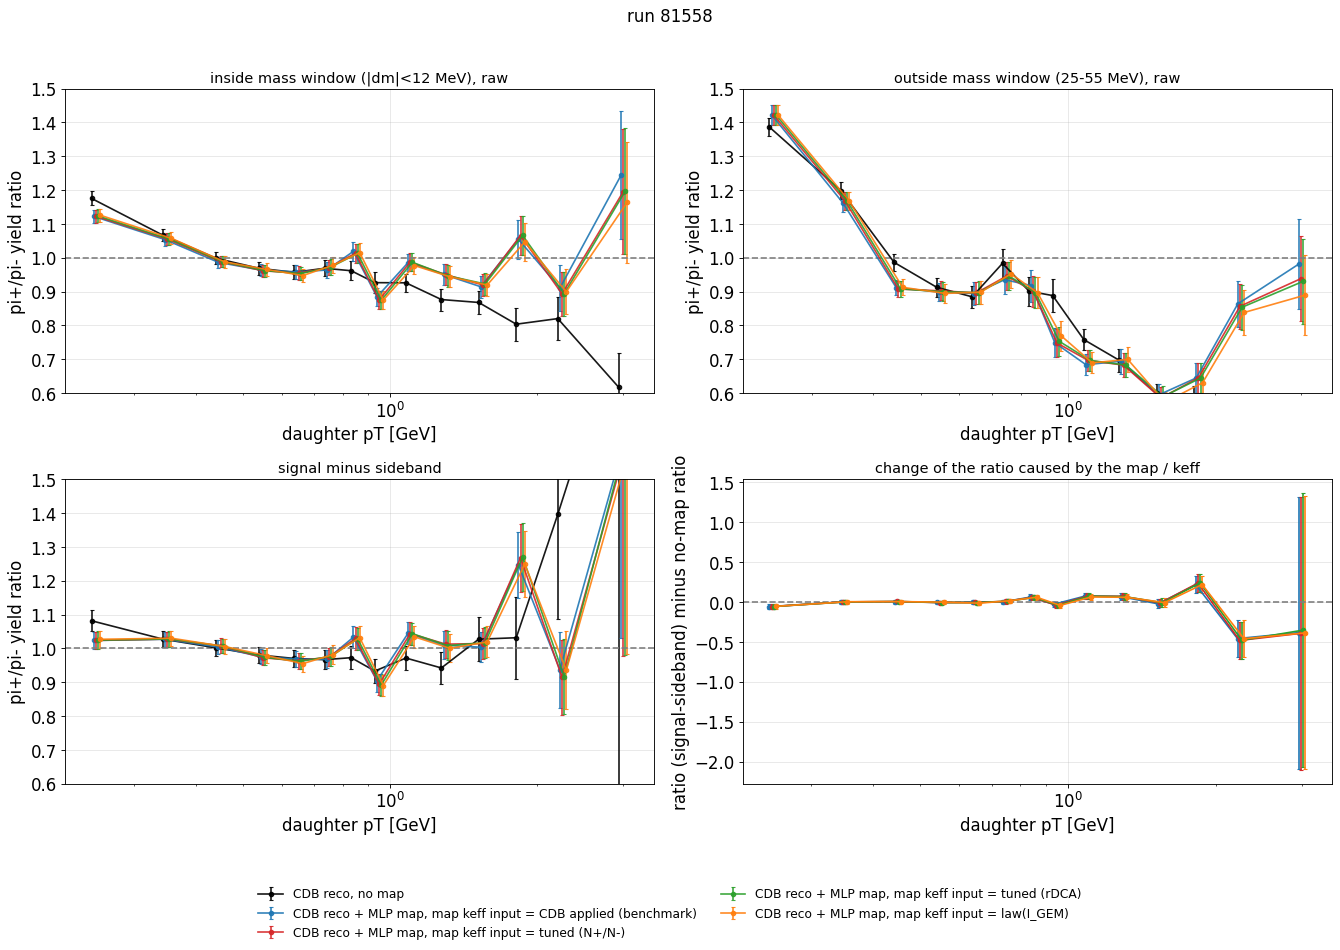

In [8]:
# pi+/pi- yield ratio vs daughter pT (pT+ of the pi+ daughter, pT- of the pi- daughter), K0s candidates split by mass window
#   in  : |dm| < 12 MeV  (signal + background under the peak)      out : 25 < |dm| < 55 MeV (sidebands, background only)
#   sub : in - 0.4*out  (signal minus sideband; sideband width scale 24/60)
PTB = np.array([.2, .3, .4, .5, .6, .7, .8, .9, 1.0, 1.2, 1.4, 1.7, 2.0, 2.5, 3.5]); ptc = .5*(PTB[1:] + PTB[:-1])
def cnt(run, i, kind):
    d = TAB[run]; m = np.abs(d['m'][i]); mask = (m < 12) if kind == 'in' else ((m > 25) & (m < 55)); return [np.histogram(d[ch][i][mask], PTB)[0].astype(float) for ch in ('ppos', 'pneg')]
def yratio(run, i, kind):
    if kind == 'sub':
        ip, im = cnt(run, i, 'in'); op, om = cnt(run, i, 'out'); P_, N_ = ip - .4*op, im - .4*om; eP, eN = ip + .16*op, im + .16*om
    else: P_, N_ = cnt(run, i, kind); eP, eN = P_, N_
    r = P_/np.clip(N_, 1, None); e = np.abs(r)*np.sqrt(eP/np.clip(P_, 1, None)**2 + eN/np.clip(N_, 1, None)**2); return r, e
def pi_fig(run):
    fig, ax = plt.subplots(2, 2, figsize=(17, 12)); T_ = {'in': 'inside mass window (|dm|<12 MeV), raw', 'out': 'outside mass window (25-55 MeV), raw', 'sub': 'signal minus sideband'}
    for a, kind in zip(ax.flat[:3], ('in', 'out', 'sub')):
        for j, i in enumerate(range(5)): y_, e_ = yratio(run, i, kind); a.errorbar(ptc*(1 + .01*(j - 2)), y_, e_, fmt='o-', ms=4, color=COL[i], label=LAB[i], capsize=2, alpha=.9)
        a.axhline(1, color='gray', ls='--'); a.set_xlabel('daughter pT [GeV]'); a.set_ylabel('pi+/pi- yield ratio'); a.set_title(T_[kind], fontsize=13); a.set_xscale('log'); a.set_ylim(.6, 1.5)
    a = ax.flat[3]; y0, e0 = yratio(run, 0, 'sub')
    for j, i in enumerate(range(1, 5)): y_, e_ = yratio(run, i, 'sub'); a.errorbar(ptc*(1 + .01*(j - 1.5)), y_ - y0, np.hypot(e_, e0)*.7, fmt='o-', ms=4, color=COL[i], capsize=2)
    a.axhline(0, color='gray', ls='--'); a.set_xlabel('daughter pT [GeV]'); a.set_ylabel('ratio (signal-sideband) minus no-map ratio'); a.set_xscale('log'); a.set_title('change of the ratio caused by the map / keff', fontsize=13)
    h_, l_ = ax[0, 0].get_legend_handles_labels(); fig.legend(h_, l_, loc='lower center', ncol=2, fontsize=11, frameon=False); fig.suptitle('run %s' % run, fontsize=15); fig.tight_layout(rect=[0, 0.1, 1, 0.97]); plt.show()
pi_fig('81558')

## K0s optimum scale of the MLP map vs the keff rule (8 runs, per side)

The optimum scale s of the map (s = 1: keff input = CDB keff) from the K0s core scan; compared with how far the proposed keff is from the CDB applied keff.

,run,side,s_opt,r_NpNm,r_rDCA
0,79513,S,1.141,-0.005,0.013
1,79513,N,0.837,-0.007,0.011
2,79516,S,0.867,0.003,0.049
3,79516,N,0.917,-0.001,0.045
4,79529,S,1.213,-0.013,0.007
5,79529,N,0.961,-0.010,0.010
6,79509,S,1.011,0.008,0.019
7,79509,N,0.965,0.012,0.023
8,81558,S,1.103,-0.028,-0.031
9,81558,N,0.996,-0.055,-0.058


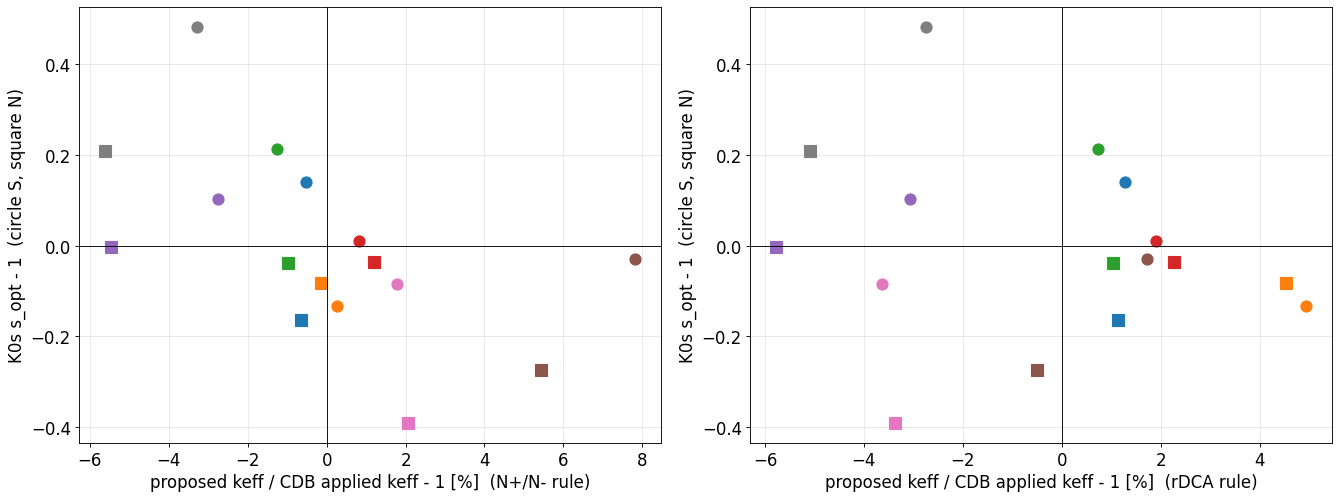

In [9]:
def popt(s, y):
    i = int(np.argmax(y)); lo, hi = max(0, i-4), min(len(s), i+5)
    if hi - lo < 5: return np.nan
    a, b, c = np.polyfit(s[lo:hi], y[lo:hi], 2); return -b/(2*a) if a < 0 else np.nan
rows = []
for r in KEFF_CDB:
    z = np.load(KS/('ks_sc_best50_%s.npz' % r)); s = z['s']
    for sd, g in enumerate(('S', 'N')):
        so = popt(s, z['core_'+g]); l = L[L.run == int(r)].iloc[0]
        rows.append(dict(run=r, side=g, s_opt=so, r_NpNm=l['keff_%s_NpNm' % g]/KEFF_CDB[r][sd] - 1, r_rDCA=l['keff_%s_rDCA' % g]/KEFF_CDB[r][sd] - 1))
R = pd.DataFrame(rows); display(R.round(3))
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
for a, c, ttl in zip(ax, ('r_NpNm', 'r_rDCA'), ('N+/N- rule', 'rDCA rule')):
    for _, t in R.iterrows(): a.plot(100*t[c], t.s_opt - 1, 'os'[t.side == 'N'], color=plt.cm.tab10(list(KEFF_CDB).index(t.run)), ms=10)
    a.axhline(0, color='k', lw=.8); a.axvline(0, color='k', lw=.8); a.set_xlabel('proposed keff / CDB applied keff - 1 [%%]  (%s)' % ttl); a.set_ylabel('K0s s_opt - 1  (circle S, square N)')
fig.tight_layout(); plt.show()

## What to take from this

* The N+/N− residual predicts the real-reco tuned keff better than the rDCA offset (LOO 2.9 % vs 4.3 %); only 8 runs calibrate it, and flagged runs (high current, ln N+/N− outside the calibrated range, rules disagreeing) are extrapolation.
* Parametrisation: run-by-run tuned keff for every run with QA; for any other run keff = a + b·I_GEM (cell above), which stays within about 2–3 % of the nominal law.
* K0s on the stored clusters: only the *map's* keff input changes (the CDB correction inside the clusters stays at CDB keff), so the four map configurations being almost identical says nothing about the reco keff. The map itself helps (benchmark vs no map). Judging the tuned keff needs real re-reco (running now, configuration `v0t_sc50k`).

# O+O (run3oo) keff scan: K0s width versus keff

Real re-reco with the SC-slot MLP map and the base keff of every run multiplied by 0.95 / 1.05 / 1.15 (configs `v0t_scm_kA/kB/kC`, 40-50 segments x 1000 events per point). Base keff is the CDB payload for 82624-82632 and the GEM-current fallback for all other O+O runs. Only runs with all three points are used (the slowest runs were killed by the 6 h job limit, so the highest-keff runs are missing).

**Why this differs from the pp calibration above.** The pp 'tuned keff' is the value where the rDCA q+ - q- offset vanishes. For O+O the K0s width optimum is not at the rDCA zero (82630: rDCA zero at +16 % over CDB keff, K0s width minimum at about +5 %), so here the target is the **K0s Gaussian width** itself. Single-run optima are noisy (sigma error 0.5-1 MeV per point), so the runs are pooled: sigma of each run is divided by its own mean over the three points, then averaged with inverse-variance weights.

36 O+O runs with all three keff points; base keff 0.64-4.27


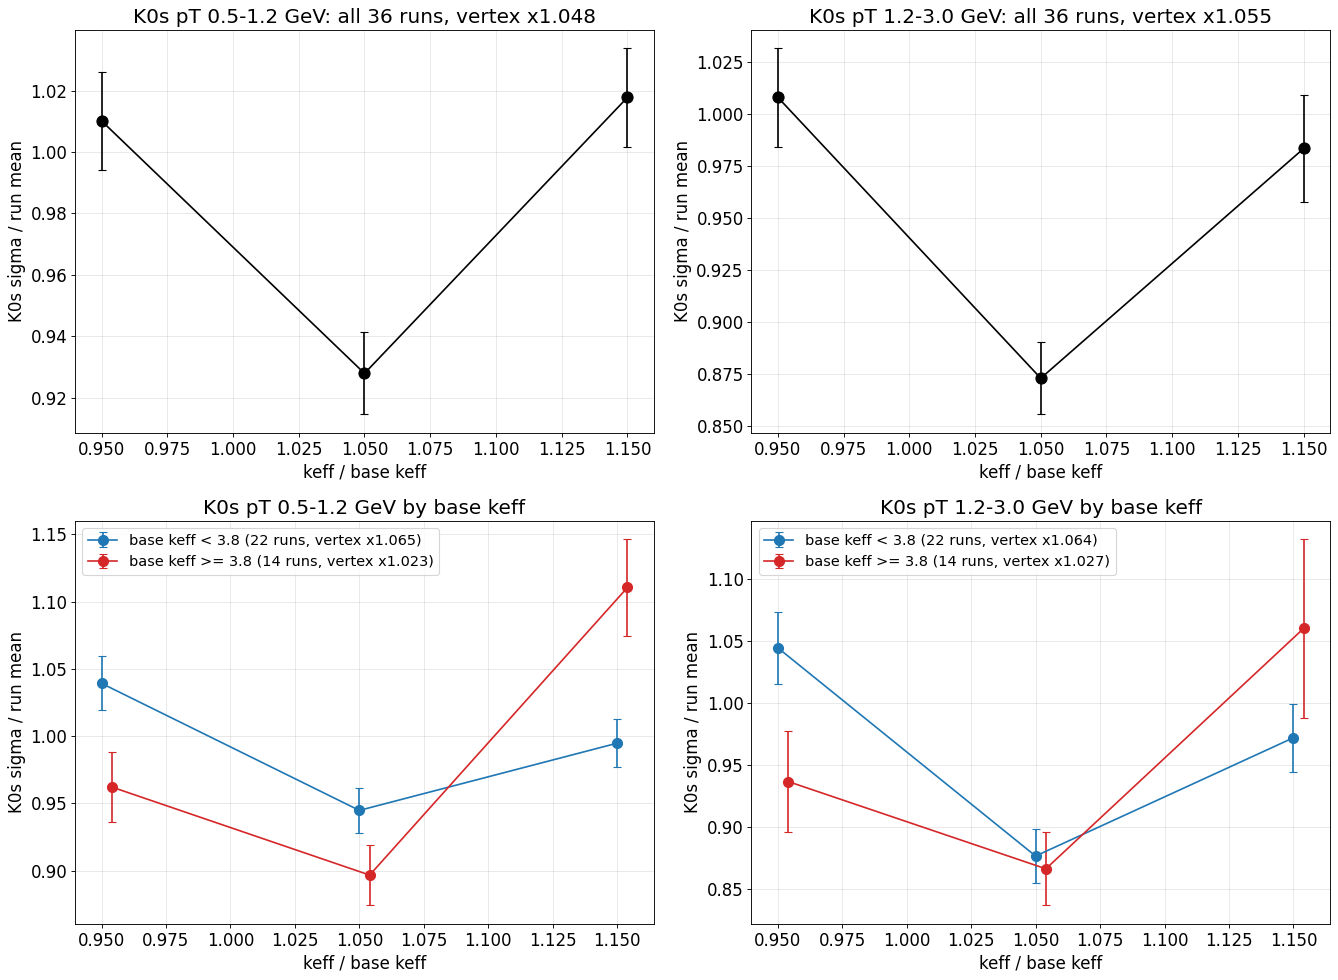

In [ ]:
KS2 = T/'ml/newgain/v0keffscan'; OO = pd.read_csv(KS2/'kscan_sigma_summary.csv'); OO['kb'] = .5*(OO.baseS + OO.baseN); f3 = np.array([.95, 1.05, 1.15])
def sigcols(df, key): return df[['sig_%s_%s' % (key, t) for t in 'ABC']].values, df[['err_%s_%s' % (key, t) for t in 'ABC']].values
def pooled(df, key):
    S, E = sigcols(df, key); ok = np.isfinite(S).all(1) & np.isfinite(E).all(1) & (E > 0).all(1) & (S > 0).all(1); S, E = S[ok], E[ok]; mu = S.mean(1, keepdims=True)
    w = (mu/E)**2; m = ((S/mu)*w).sum(0)/w.sum(0); e = 1/np.sqrt(w.sum(0)); a, b, _ = np.polyfit(f3, m, 2); return m, e, (-b/(2*a) if a > 0 else np.nan), int(ok.sum())
print(len(OO), 'O+O runs with all three keff points; base keff %.2f-%.2f' % (OO.kb.min(), OO.kb.max()))
fig, ax = plt.subplots(2, 2, figsize=(17, 12.5)); gl = ((0, 3.8, 'base keff < 3.8'), (3.8, 99, 'base keff >= 3.8'))
for j, (key, ttl) in enumerate((('lo', 'K0s pT 0.5-1.2 GeV'), ('hi', 'K0s pT 1.2-3.0 GeV'))):
    m, e, v, n = pooled(OO, key); a = ax[0, j]; a.errorbar(f3, m, e, fmt='o-', ms=10, capsize=4, color='k'); a.set_title('%s: all %d runs, vertex x%.3f' % (ttl, n, v))
    a.set_xlabel('keff / base keff'); a.set_ylabel('K0s sigma / run mean')
    a = ax[1, j]
    for (lo, hi, nm), c in zip(gl, ('C0', 'C3')):
        d = OO[(OO.kb >= lo) & (OO.kb < hi)]; m, e, v, n = pooled(d, key); a.errorbar(f3 + (.004 if c == 'C3' else 0), m, e, fmt='o-', ms=9, capsize=4, color=c, label='%s (%d runs, vertex x%.3f)' % (nm, n, v))
    a.legend(fontsize=13); a.set_xlabel('keff / base keff'); a.set_ylabel('K0s sigma / run mean'); a.set_title(ttl + ' by base keff')
fig.tight_layout(); plt.show()

,run,nseg,baseS,baseN,lo x0.95,lo x1.05,lo x1.15,vertex_lo,hi x0.95,hi x1.05,hi x1.15,vertex_hi
0,82503,23,3.977000,3.857000,5.699000,4.886000,7.994000,1.021000,7.539000,5.765000,11.791000,1.023000
1,82504,40,3.525000,3.427000,8.039000,6.686000,7.702000,1.057000,10.598000,6.634000,8.833000,1.064000
2,82505,40,3.323000,3.216000,6.738000,5.535000,5.849000,1.079000,8.016000,7.698000,8.765000,1.023000
3,82507,40,3.155000,3.072000,7.170000,6.705000,6.509000,1.173000,11.272000,9.682000,11.315000,1.049000
4,82508,40,3.031000,2.960000,6.628000,5.938000,6.234000,1.070000,9.448000,8.790000,9.644000,1.044000
5,82509,40,2.718000,2.654000,6.452000,5.358000,5.240000,1.112000,15.451000,10.245000,10.883000,1.089000
6,82519,37,4.082000,4.019000,6.074000,7.256000,8.421000,nan,11.120000,10.773000,14.268000,1.009000
7,82520,37,3.842000,3.771000,7.285000,5.835000,8.281000,1.037000,9.342000,8.805000,9.704000,1.037000
8,82523,40,0.661000,0.673000,4.716000,5.201000,5.207000,nan,8.478000,8.740000,9.375000,0.930000
9,82525,40,0.652000,0.667000,5.777000,5.041000,5.033000,1.101000,5.068000,7.105000,8.255000,nan


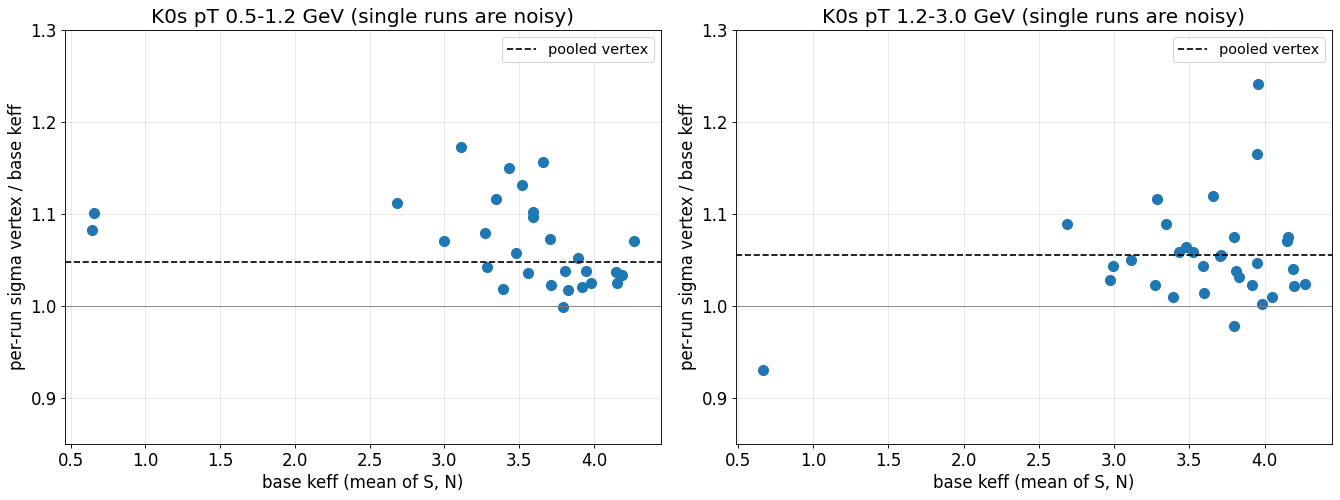

In [ ]:
T2 = OO[['run', 'nseg', 'baseS', 'baseN']].copy()
for key in ('lo', 'hi'):
    S, E = sigcols(OO, key)
    for i, t in enumerate('ABC'): T2['%s %s' % (key, 'x%.2f' % f3[i])] = S[:, i]
    v = []
    for s in S:
        a, b, _ = np.polyfit(f3, s, 2); x = -b/(2*a) if a > 0 else np.nan; v.append(x if 0.85 < x < 1.3 else np.nan)
    T2['vertex_' + key] = v
display(T2.round(3).style.set_properties(**{'font-size': '10pt'}))
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
for a, key, ttl in zip(ax, ('lo', 'hi'), ('K0s pT 0.5-1.2 GeV', 'K0s pT 1.2-3.0 GeV')):
    a.plot(OO.kb, T2['vertex_' + key], 'o', ms=9); a.axhline(pooled(OO, key)[2], color='k', ls='--', label='pooled vertex'); a.axhline(1, color='gray', lw=.8); a.set_xlabel('base keff (mean of S, N)'); a.set_ylabel('per-run sigma vertex / base keff'); a.set_title(ttl + ' (single runs are noisy)'); a.legend(fontsize=13); a.set_ylim(.85, 1.3)
fig.tight_layout(); plt.show()

## What to take from the O+O width scan

* Pooled over the runs the K0s width is smallest at **about +5 % over the base keff**, in both pT ranges; the +/-10 % points are clearly worse (see the first row of the figure). This agrees with the single-run real re-reco of 82630.
* The pp-style rule (keff at the rDCA zero) would put O+O 82630 at +16 %, a too large correction for the K0s width. A keff rule for O+O therefore has to be calibrated to the width optimum, not to the rDCA zero.
* Per-run optima scatter a lot (error of one point 0.5-1 MeV), so the rule can only be validated on pooled groups. Three points are coarse: the vertex sits near the middle point and the quoted position is good to a few per cent, not better.
* Missing: the highest-keff O+O runs (82624, 82625, 82699, killed by the 6 h limit), so the range above base keff about 4.3 is not covered.

## O+O: charge balance of the K0s daughters versus keff (proxy, not the track-level N+/N-)

pi+/pi- yield ratio of the K0s daughters, as the plain pT-spectrum ratio, signal window (|dm| < 12 MeV) minus 0.4 x sideband (25-55 MeV), same segments for the three keff points of each run. **This is not the single-track N+/N- of the production QA**: it only sees tracks that form K0s candidates (and the sailor cut), and it is measured with the SC-slot map applied. It is used here only because the real track-level N+/N- for the O+O runs does not exist yet; the scan of real tracks has to replace it.

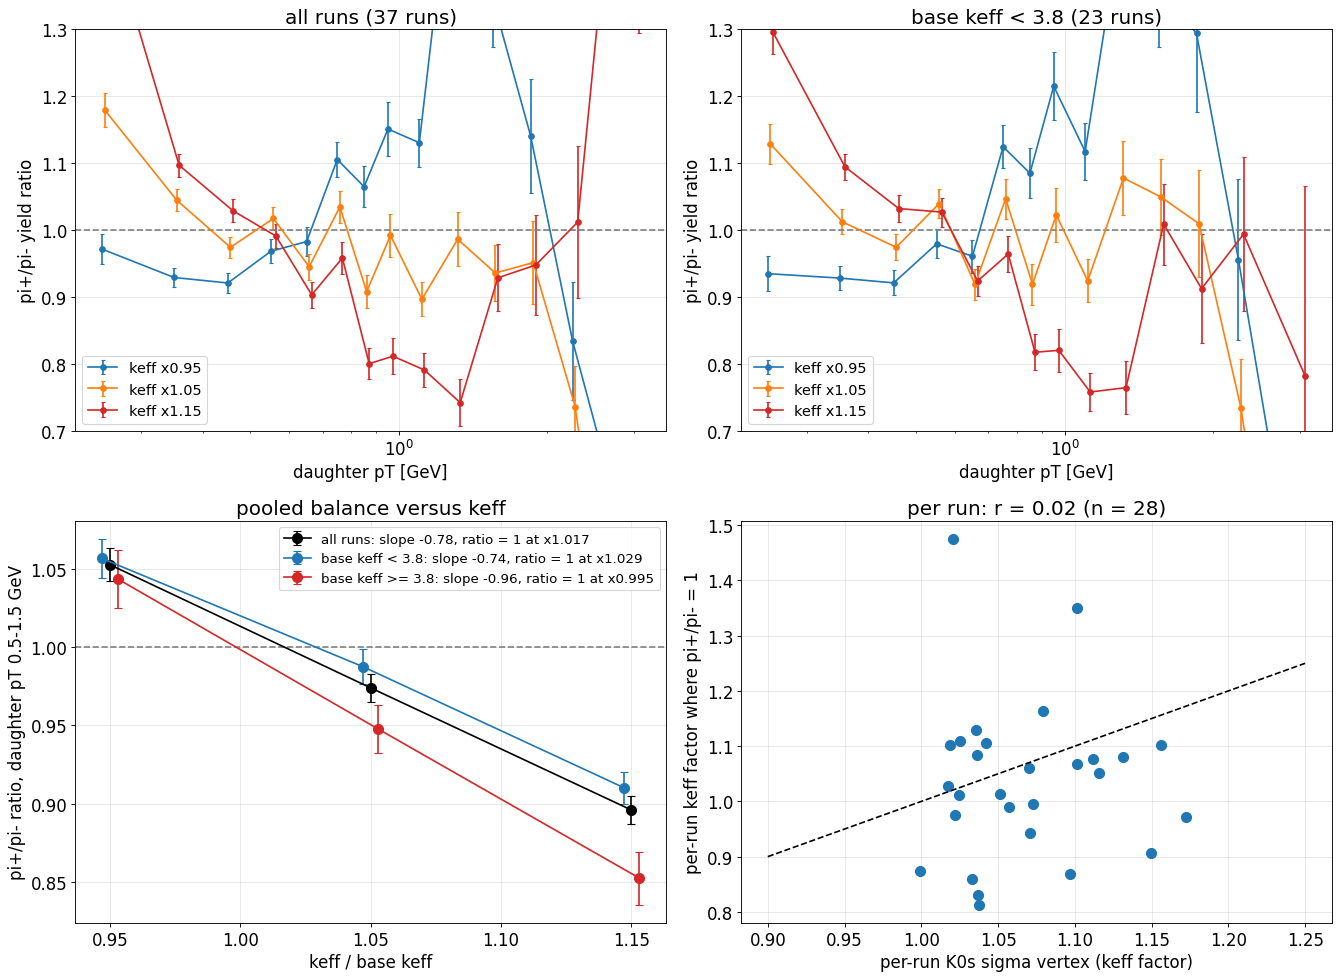

per-run slope of the ratio per unit keff factor: median -0.75 (IQR -1.11 .. -0.50); zero crossing: median x1.054 (IQR 0.975 .. 1.102)


In [ ]:
BAL = np.load(KS2/'kscan_balance.npz'); cnt, ptbb, fb, rb = BAL['cnt'], BAL['ptb'], BAL['fac'], BAL['runs']; kbb = .5*(BAL['baseS'] + BAL['baseN']); ptc = .5*(ptbb[1:] + ptbb[:-1])
Pp = cnt[:, :, 0, :] - .4*cnt[:, :, 2, :]; Nn = cnt[:, :, 1, :] - .4*cnt[:, :, 3, :]; lo15 = (ptbb[:-1] >= .5 - 1e-9) & (ptbb[1:] <= 1.5 + 1e-9)
def ratio(sel, cols=slice(None)):
    p = Pp[sel][:, :, cols].sum(0); n = Nn[sel][:, :, cols].sum(0); r = p/n; return r, r*np.sqrt(1/np.clip(p, 1, None) + 1/np.clip(n, 1, None))
fig, ax = plt.subplots(2, 2, figsize=(17, 12.5)); colr = ('C0', 'C1', 'C3'); allr = np.ones(len(rb), bool)
for a, (sel, nm) in zip(ax.flat[:2], ((allr, 'all runs'), (kbb < 3.8, 'base keff < 3.8'))):
    r, e = ratio(sel)
    for j in range(3): a.errorbar(ptc*(1 + .012*j), r[j], e[j], fmt='o-', ms=5, capsize=2, color=colr[j], label='keff x%.2f' % fb[j])
    a.axhline(1, color='gray', ls='--'); a.set_xscale('log'); a.set_ylim(.7, 1.3); a.set_xlabel('daughter pT [GeV]'); a.set_ylabel('pi+/pi- yield ratio'); a.set_title('%s (%d runs)' % (nm, sel.sum())); a.legend(fontsize=13)
a = ax[1, 0]
for sel, nm, c_, off in ((allr, 'all runs', 'k', 0), (kbb < 3.8, 'base keff < 3.8', 'C0', -.003), (kbb >= 3.8, 'base keff >= 3.8', 'C3', .003)):
    r, e = ratio(sel, lo15); r, e = r.sum(1) if False else r, e; rr = np.array([Pp[sel][:, j][:, lo15].sum()/Nn[sel][:, j][:, lo15].sum() for j in range(3)]); ee = rr*np.sqrt([1/Pp[sel][:, j][:, lo15].sum() + 1/Nn[sel][:, j][:, lo15].sum() for j in range(3)])
    s_, b_ = np.polyfit(fb, rr, 1, w=1/ee); a.errorbar(fb + off, rr, ee, fmt='o-', ms=9, capsize=4, color=c_, label='%s: slope %.2f, ratio = 1 at x%.3f' % (nm, s_, (1 - b_)/s_))
a.axhline(1, color='gray', ls='--'); a.set_xlabel('keff / base keff'); a.set_ylabel('pi+/pi- ratio, daughter pT 0.5-1.5 GeV'); a.legend(fontsize=12); a.set_title('pooled balance versus keff')
rows = []
SG = OO.set_index('run')
for i, r in enumerate(rb):
    p = Pp[i][:, lo15].sum(1); n = Nn[i][:, lo15].sum(1)
    if (p <= 20).any() or (n <= 20).any(): continue
    R_ = p/n; e_ = R_*np.sqrt(1/p + 1/n); s_, b_ = np.polyfit(fb, R_, 1, w=1/e_); fs = np.nan
    if r in SG.index:
        q = np.polyfit(f3, SG.loc[r, ['sig_lo_A', 'sig_lo_B', 'sig_lo_C']].values.astype(float), 2); fs = -q[1]/(2*q[0]) if q[0] > 0 else np.nan
    rows.append((r, kbb[i], s_, (1 - b_)/s_, fs))
BR = pd.DataFrame(rows, columns=['run', 'kb', 'slope', 'f_bal', 'f_sigma'])
a = ax[1, 1]; ok = BR.f_sigma.between(.85, 1.3) & BR.f_bal.between(.5, 1.6); a.plot(BR.f_sigma[ok], BR.f_bal[ok], 'o', ms=9); a.plot([.9, 1.25], [.9, 1.25], 'k--')
a.set_xlabel('per-run K0s sigma vertex (keff factor)'); a.set_ylabel('per-run keff factor where pi+/pi- = 1'); a.set_title('per run: r = %.2f (n = %d)' % (np.corrcoef(BR.f_sigma[ok], BR.f_bal[ok])[0, 1], ok.sum()))
fig.tight_layout(); plt.show()
print('per-run slope of the ratio per unit keff factor: median %.2f (IQR %.2f .. %.2f); zero crossing: median x%.3f (IQR %.3f .. %.3f)' % (BR.slope.median(), *BR.slope.quantile([.25, .75]), BR.f_bal.median(), *BR.f_bal.quantile([.25, .75])))

## What to take from the O+O balance scan (K0s-daughter proxy)

* The pi+/pi- ratio falls steadily with keff: pooled, daughter pT 0.5-1.5 GeV, about **-7.5 % in ratio per +10 % keff** (ratio 1.053 / 0.974 / 0.896 at x0.95 / x1.05 / x1.15). A charge-balance observable therefore has a clear lever arm on keff.
* The pooled ratio crosses 1 at about x1.02, close to the K0s width optimum (about x1.05); runs with base keff >= 3.8 cross lower (about x0.99), those below 3.8 higher (about x1.03).
* **Per run it does not yet predict the width optimum**: the per-run crossing and the per-run sigma vertex are uncorrelated (r about 0), as both are noise dominated at this statistics, and the three low-keff runs (base keff about 0.65, weak slope) give meaningless crossings. The relation is therefore only a group-level statement for now.
* Candidate yields still differ between the three points for some runs although the segments are the same, so the shape-based quantities (width, ratio) are used and not yields.
* This is the K0s-daughter version only. The track-level N+/N- and rDCA of real O+O data are needed to establish a formula for 'observable -> best keff'.

# Real re-reco scans: K0s width and yield versus keff, with errors

Real re-reconstruction at four keff points (×0.95, ×1.05, ×1.15, ×1.25 of the CDB keff; 3 points for some pp runs), same segments and same events at every point. pp: 24 runs, O+O: 67 runs.

**Errors.**
* **Statistical:** bootstrap over segments. The same resample is used at all four points, so the correlation between points (same events) is kept. The optimum `f_opt` is the vertex of a parabola through σ(f); its statistical error is the spread of the bootstrap vertices.
* **Systematic:** 18 variants of the width fit (bin 0.5 / 1 / 2 MeV × fit half-range 35 / 45 / 60 MeV × linear / quadratic background). The spread on σ is 0.5–1 MeV, larger than the statistical error, but it is almost the same shift at all four points, so it moves `f_opt` by only 0.003–0.04 (right-hand plot of the run figure).
* Yield: K0s candidates after cuts (sailor cut, |m−m_K0s|<60 MeV, pT 0.5–3 GeV), per segment, cut to the events common to all points.

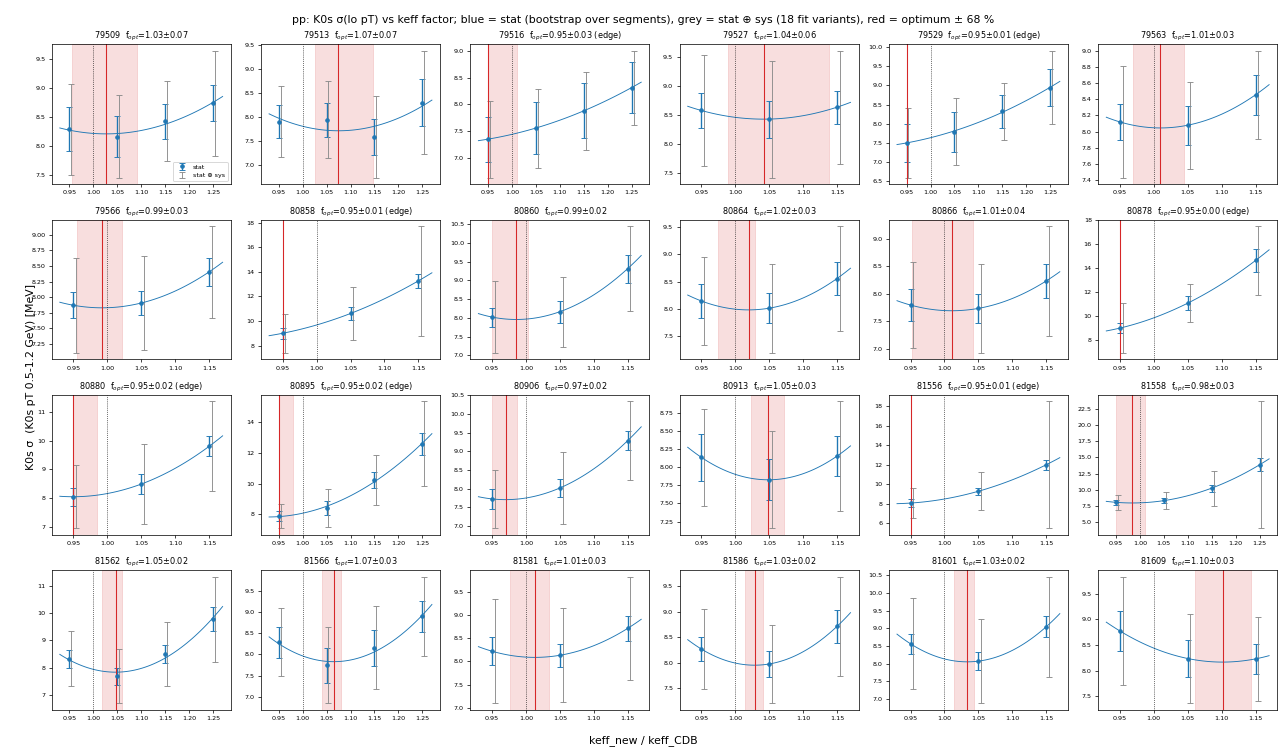

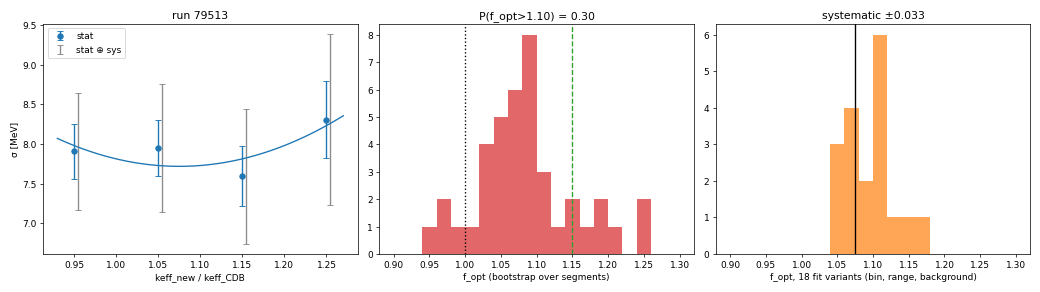

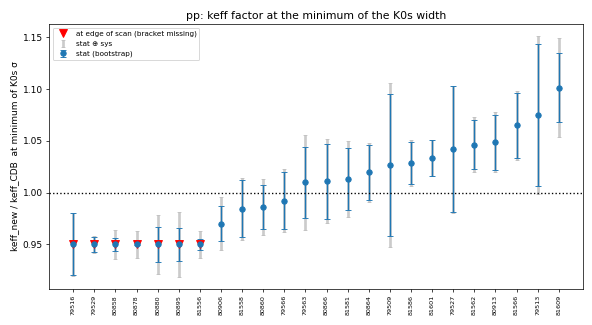

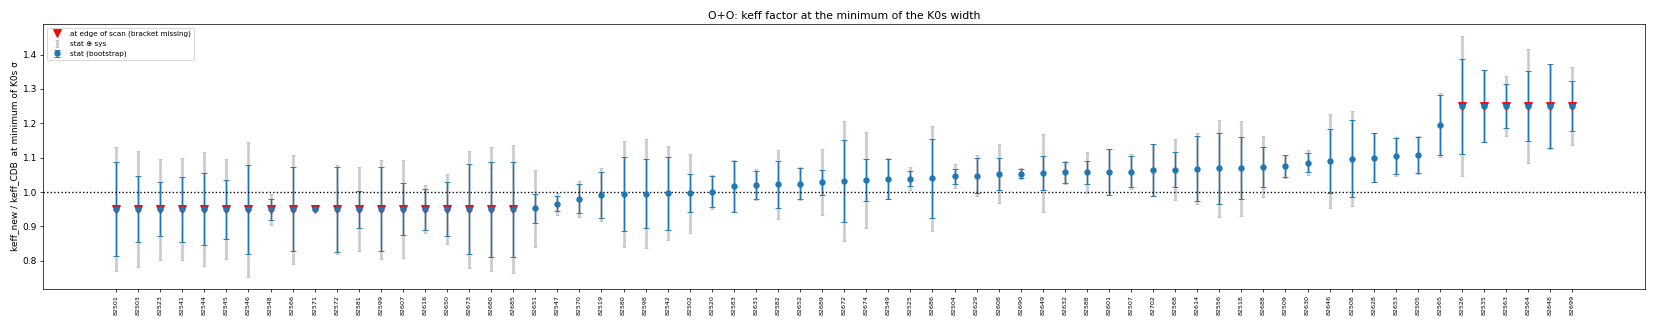

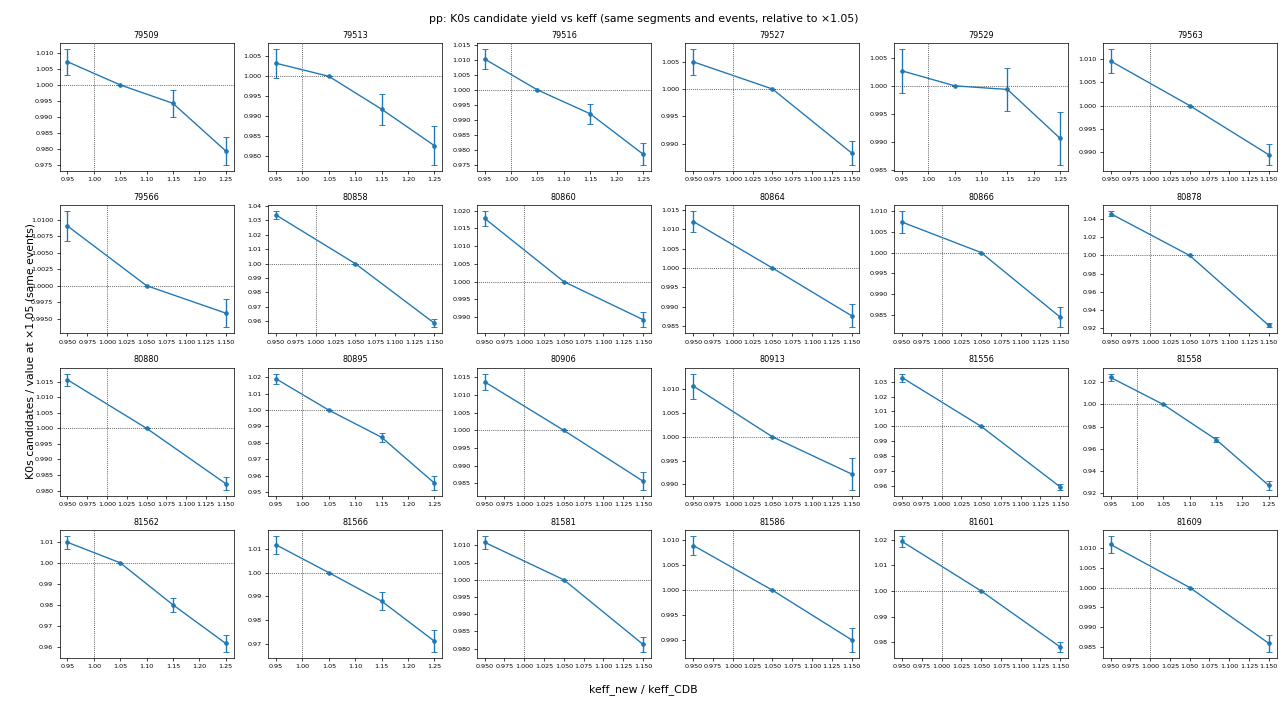

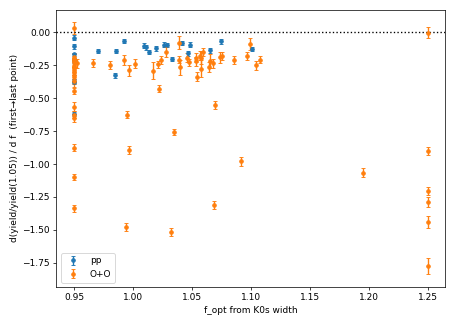

pp : f_opt median 1.010, range 0.95-1.10, at the 0.95 edge: 7 of 24 runs
O+O: f_opt median 1.032, 10-90 % 0.95-1.14, at an edge: 25 of 67 runs
79513: f_opt = 1.075 ± 0.069 (stat) ± 0.033 (sys), P(f_opt > 1.10) = 0.30


In [ ]:
# K0s width and yield versus keff with statistical and systematic errors (real re-reco scans, pp 24 runs, O+O 67 runs)
import sys; sys.path.insert(0, str(T/'ml/newgain/v0keffscan')); import kscan5_plot as K
pp, oo = K.load('pp'), K.load('oo'); ypp, yoo = K.loady('pp'), K.loady('oo')
K.fig_curves(pp, ncol=6, title='pp: K0s σ(lo pT) vs keff factor; blue = stat (bootstrap over segments), grey = stat ⊕ sys (18 fit variants), red = optimum ± 68 %'); plt.show()
K.fig_run([o for o in pp if o['run'] == 79513][0]); plt.show()
K.fig_opt(pp, 'pp: keff factor at the minimum of the K0s width'); plt.show()
K.fig_opt(oo, 'O+O: keff factor at the minimum of the K0s width'); plt.show()
K.fig_yield(ypp, title='pp: K0s candidate yield vs keff (same segments and events, relative to ×1.05)'); plt.show()
K.fig_yield_slope(ypp, yoo, pp, oo); plt.show()
v = np.array([o['vopt'] for o in pp]); print('pp : f_opt median %.3f, range %.2f-%.2f, at the 0.95 edge: %d of %d runs' % (np.median(v), v.min(), v.max(), sum(o['edge'] for o in pp), len(pp)))
v = np.array([o['vopt'] for o in oo]); print('O+O: f_opt median %.3f, 10-90 %% %.2f-%.2f, at an edge: %d of %d runs' % (np.median(v), *np.percentile(v, [10, 90]), sum(o['edge'] for o in oo), len(oo)))
o = [o for o in pp if o['run'] == 79513][0]; print('79513: f_opt = %.3f ± %.3f (stat) ± %.3f (sys), P(f_opt > 1.10) = %.2f' % (o['vopt'], o['vopt_stat'], o['vopt_sys'], o['frac_gt110']))

## What to take from this

* **79513.** `f_opt` = 1.075 ± 0.069 (stat) ± 0.033 (sys); 30 % of the bootstrap samples have `f_opt` > 1.10. The grid minimum at ×1.15 comes from σ(1.15) lying 0.3 MeV below σ(1.05), which is about the size of the statistical error of one point (0.35 MeV). So it is not significant, and the data are compatible with 1.0; the minimum is poorly determined, not at 1.15.
* **pp overall.** `f_opt` stays between 0.95 and 1.10; no pp run needs a factor above 1.1. In 7 of 24 runs the minimum is at the 0.95 edge (high GEM-current runs 80858, 80878, 80880, 80895, 81556, and 79516, 79529): their optimum is ≤ 0.95 and is not bracketed. Scan ×0.90 and ×0.85 for those.
* **O+O.** median `f_opt` 1.03; statistical error per run about 0.07, so the per-run values are noisy. 25 of 67 runs sit at an edge of the scan (19 at 0.95, 6 at 1.25).
* **Yield.** The K0s yield falls with keff in 23 of 24 pp runs and 65 of 67 O+O runs, with an error of only 0.2–0.5 %; it is far more precise than σ, but it has no maximum inside 0.95–1.25. It does not locate an optimum in this range, and its slope is steepest for the high-keff runs (80878: −8 % between ×1.05 and ×1.15). Whether it peaks at lower keff needs the ×0.85/0.90 points. The fitted peak area at low pT is noisy (±5 %).

## K0s significance and correlations with the observables

Significance Z = S/√(S+B) with S, B the Gaussian and background integrals in a ±2σ window around the fitted peak (same segments and events at every keff point; paired bootstrap over segments for the errors). The maximum of Z is a second K0s optimum, next to the minimum of σ. Below: how the real K0s optima (not the proxy) relate to the rDCA zero crossing and to the observables of the CDB reco.

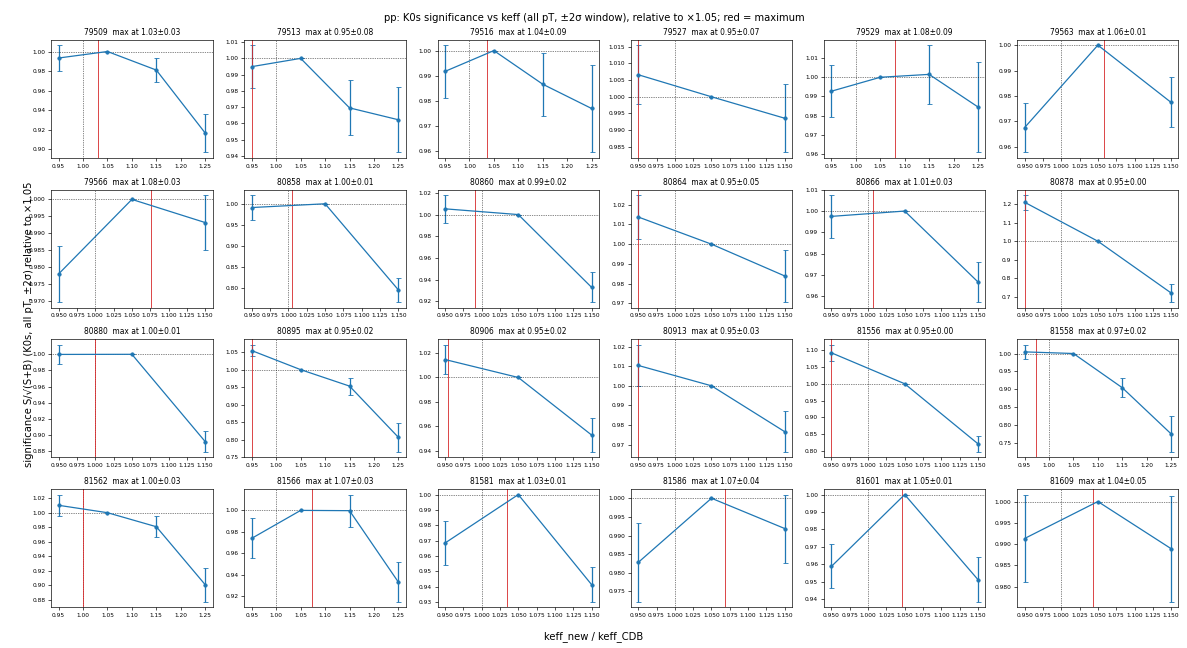

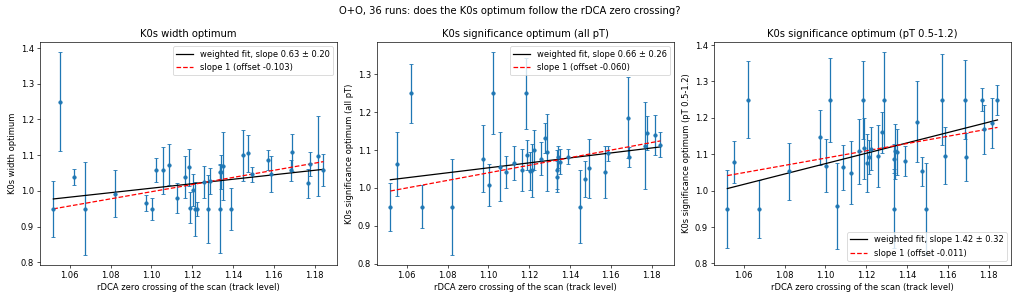

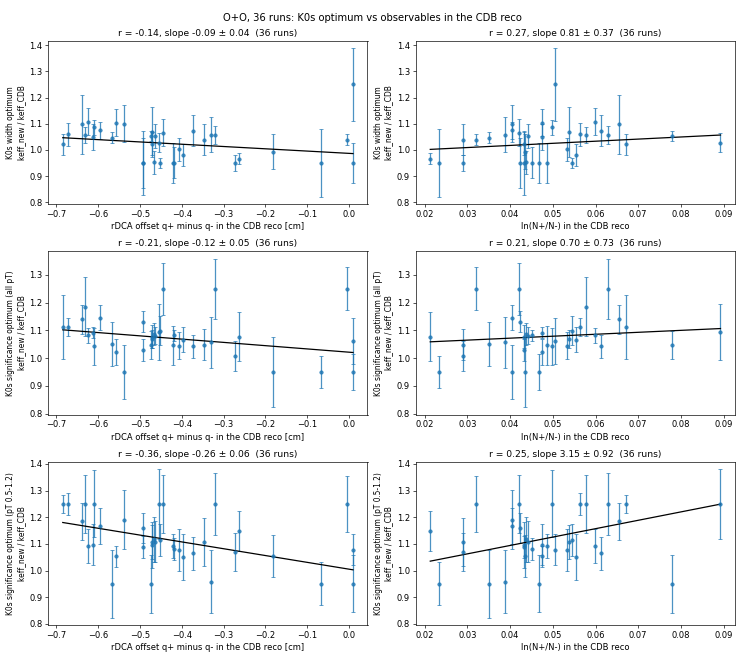

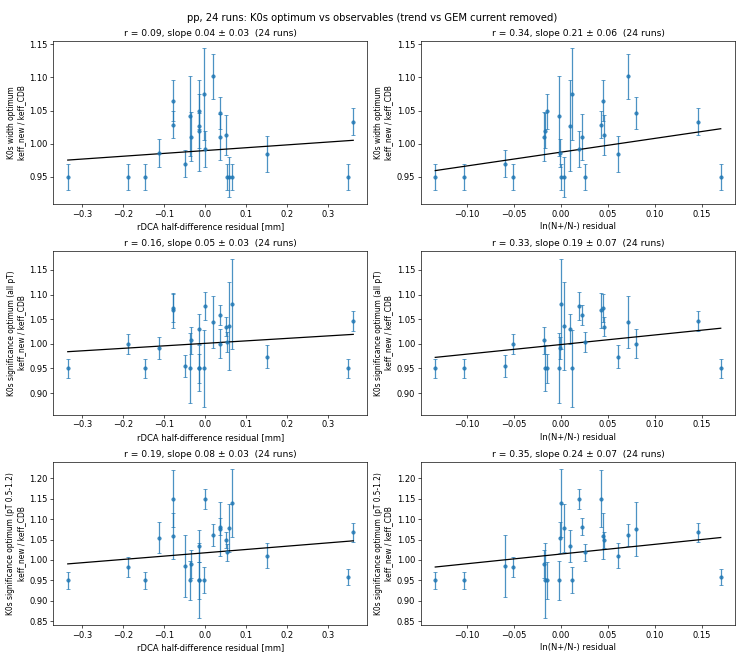

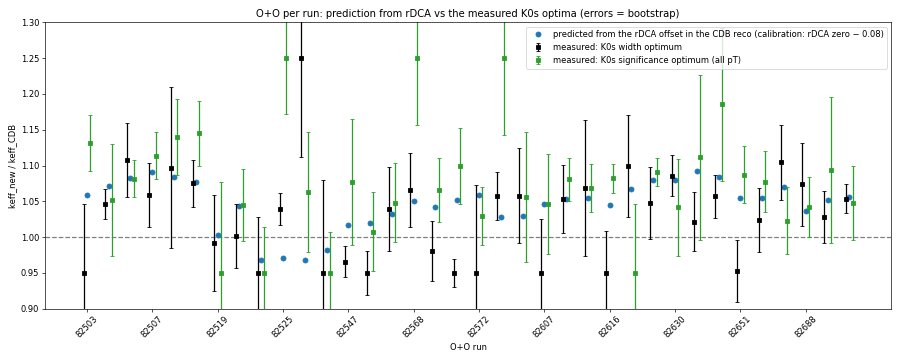

In [ ]:
# K0s significance versus keff, and correlation of the real K0s optima with the rDCA / charge-balance observables
import sys, pickle; sys.path.insert(0, str(T/'ml/newgain/v0keffscan')); import kscan5_corr as KC
G, Ro = KC.feats(); zpp = pickle.load(open(T/'ml/newgain/v0keffscan/signif_pp.pkl', 'rb'))
KC.fig_zcurves(zpp, title='pp: K0s significance vs keff (all pT, ±2σ window), relative to ×1.05; red = maximum'); plt.show()
KC.fig_f0test(Ro); plt.show()
KC.fig_corr('oo', Ro, ('odd0_cdb', 'lnr_cdb'), ('rDCA offset q+ minus q- in the CDB reco [cm]', 'ln(N+/N-) in the CDB reco'), 'O+O, 36 runs: K0s optimum vs observables in the CDB reco'); plt.show()
KC.fig_corr('pp', G, ('rd_rI', 'lnr_rI'), ('rDCA half-difference residual [mm]', 'ln(N+/N-) residual'), 'pp, 24 runs: K0s optimum vs observables (trend vs GEM current removed)'); plt.show()
KC.fig_perrun(Ro); plt.show()

## What to take from this

* **The proxy is confirmed on average, with a caveat on slope.** Over 36 O+O runs the K0s width optimum lies 0.095 below the rDCA zero crossing (the assumed −0.08 holds). The significance optimum lies 0.05 below (all pT) and 0.01 below (pT 0.5-1.2). The slope of the K0s optimum against the rDCA zero is 0.63 ± 0.20 (width), 0.66 ± 0.26 (significance, all pT) and 1.42 ± 0.32 (significance, low pT); 1 is expected if the rDCA zero predicts the K0s optimum run by run. So the run-to-run trend is there, but poorly measured.
* **Correlation coefficients are low (|r| 0.1–0.4), because the per-run K0s optimum has a statistical error of 0.05–0.08 while the predicted values spread by only ±0.03.** Use the slope and its error, not r, to judge the relation; per-run optima cannot be tested at better than that.
* **pp (24 runs).** The K0s optimum correlates weakly with ln(N+/N−) (r 0.33–0.35) and barely with the rDCA half-difference (r 0.1–0.2). The strong correlations of the 8-run calibration were against the rDCA-zero keff of the real re-reco, not against K0s optima.
* **Significance has an interior maximum** for most pp runs (e.g. 79563 at 1.06 ± 0.01, 81601 at 1.05 ± 0.01), median 1.00 for pp and 1.05 for O+O; it is the only figure of merit here that peaks, since the K0s yield alone falls with keff. The runs at the edge are the same high-keff ones as for the width.

# Backup: K0s mass peaks, all runs

Six pT bins per run; four configurations: no map, same MLP map with CDB keff (benchmark), with N+/N- tuned keff, with rDCA tuned keff.

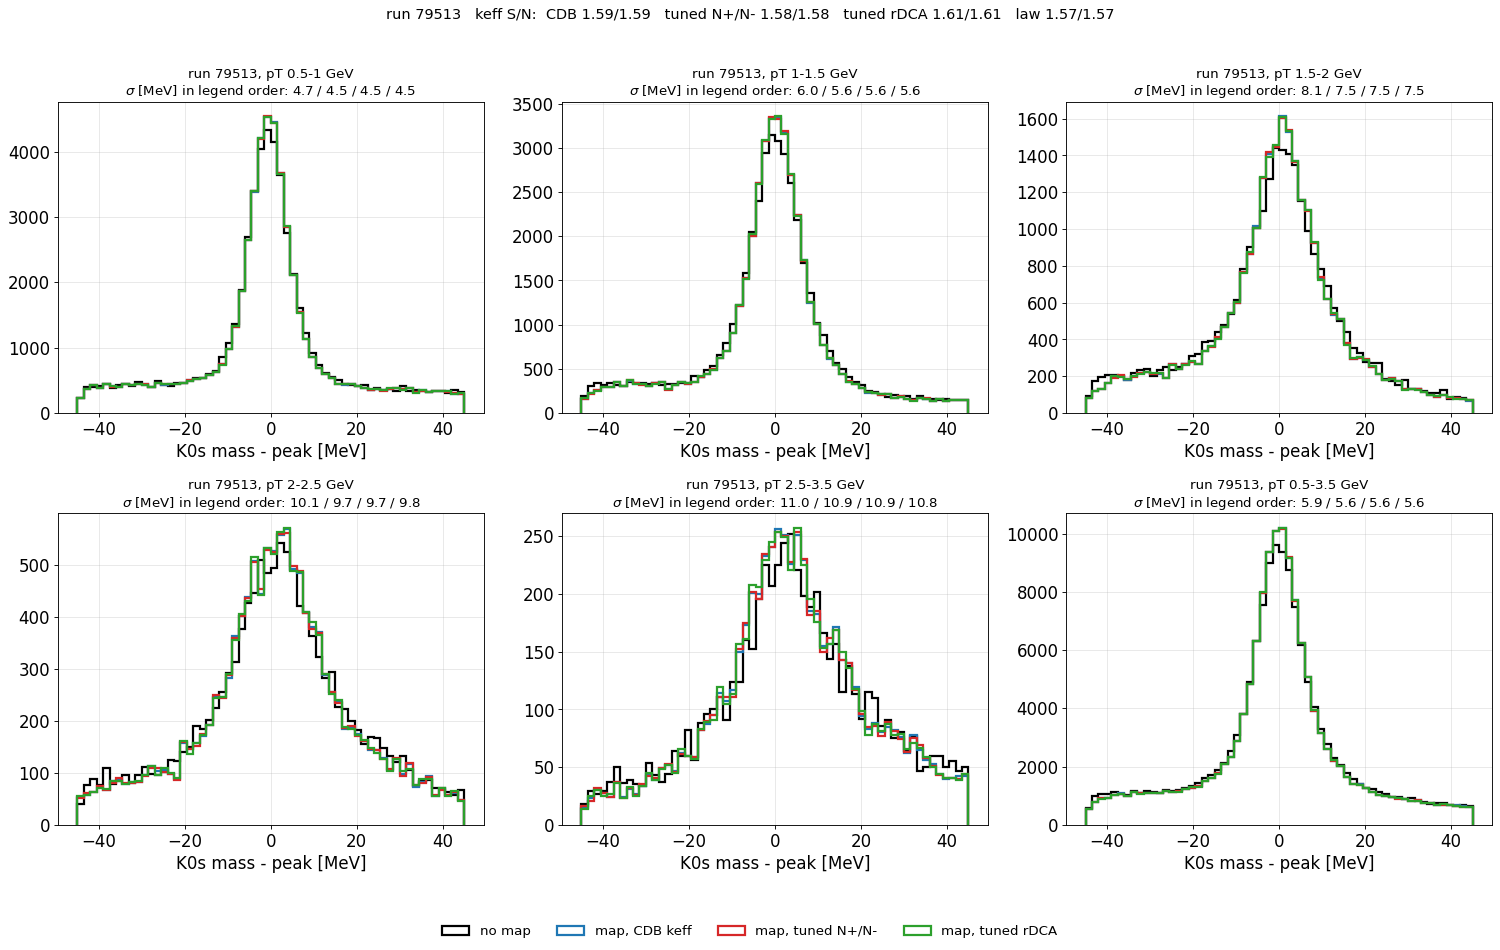

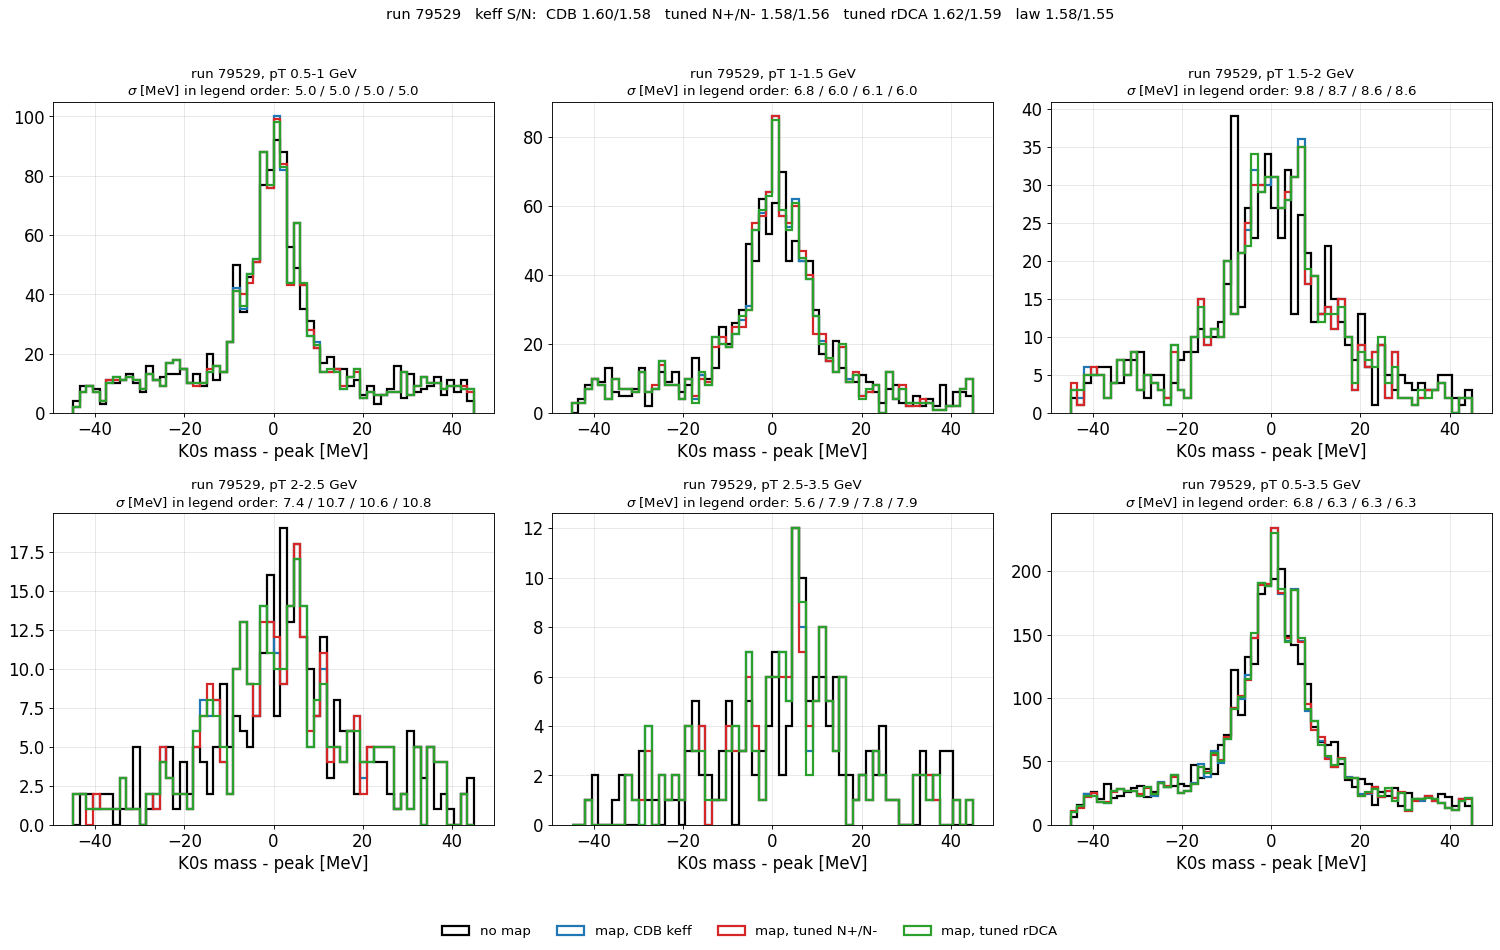

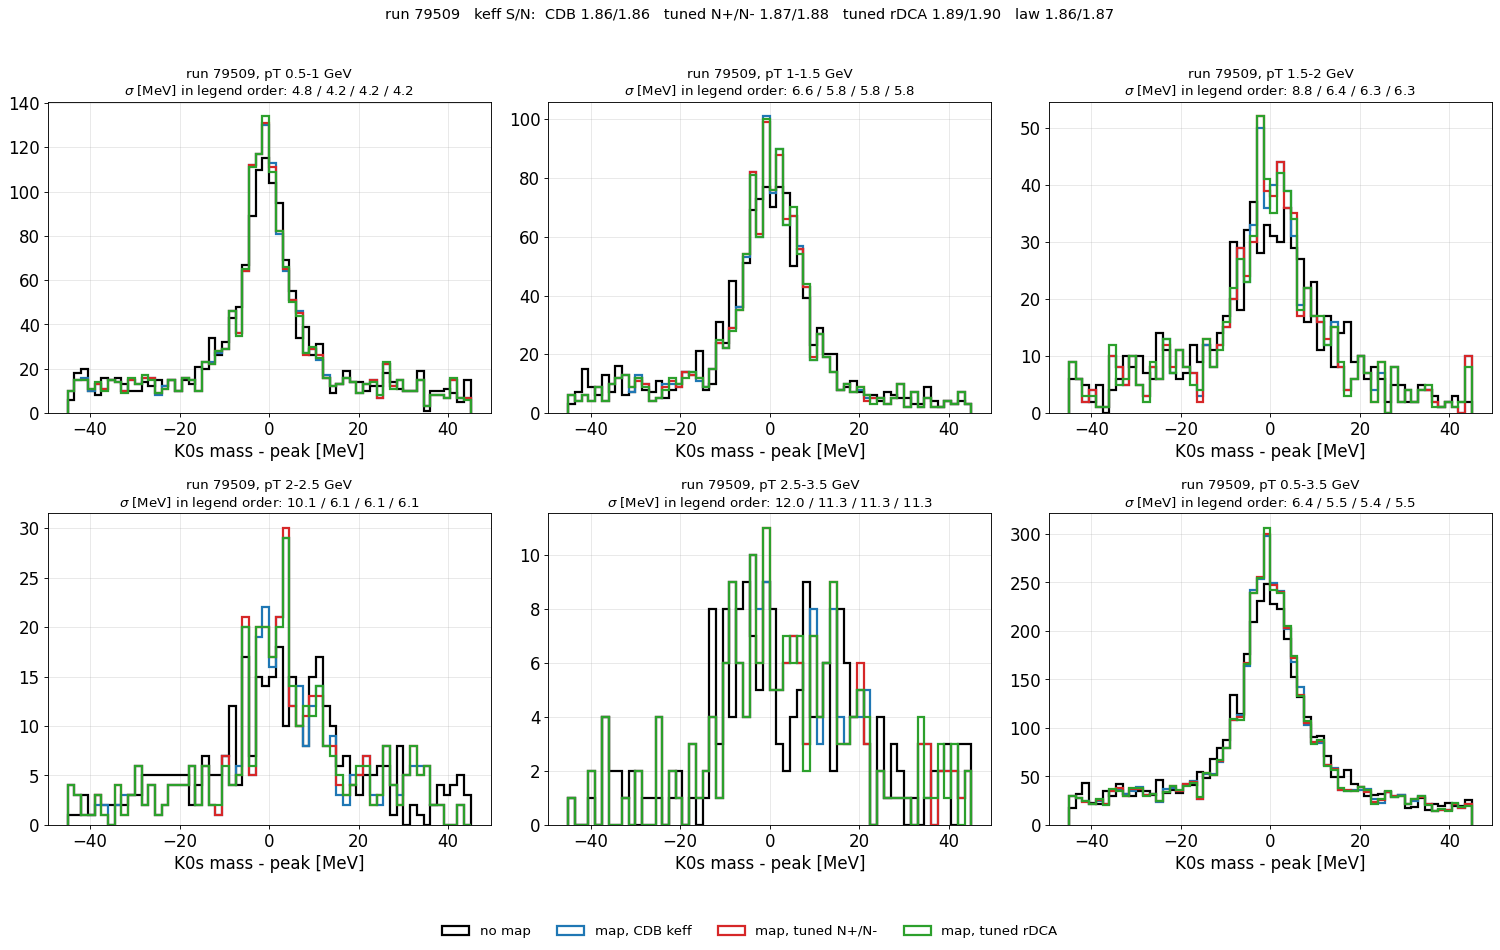

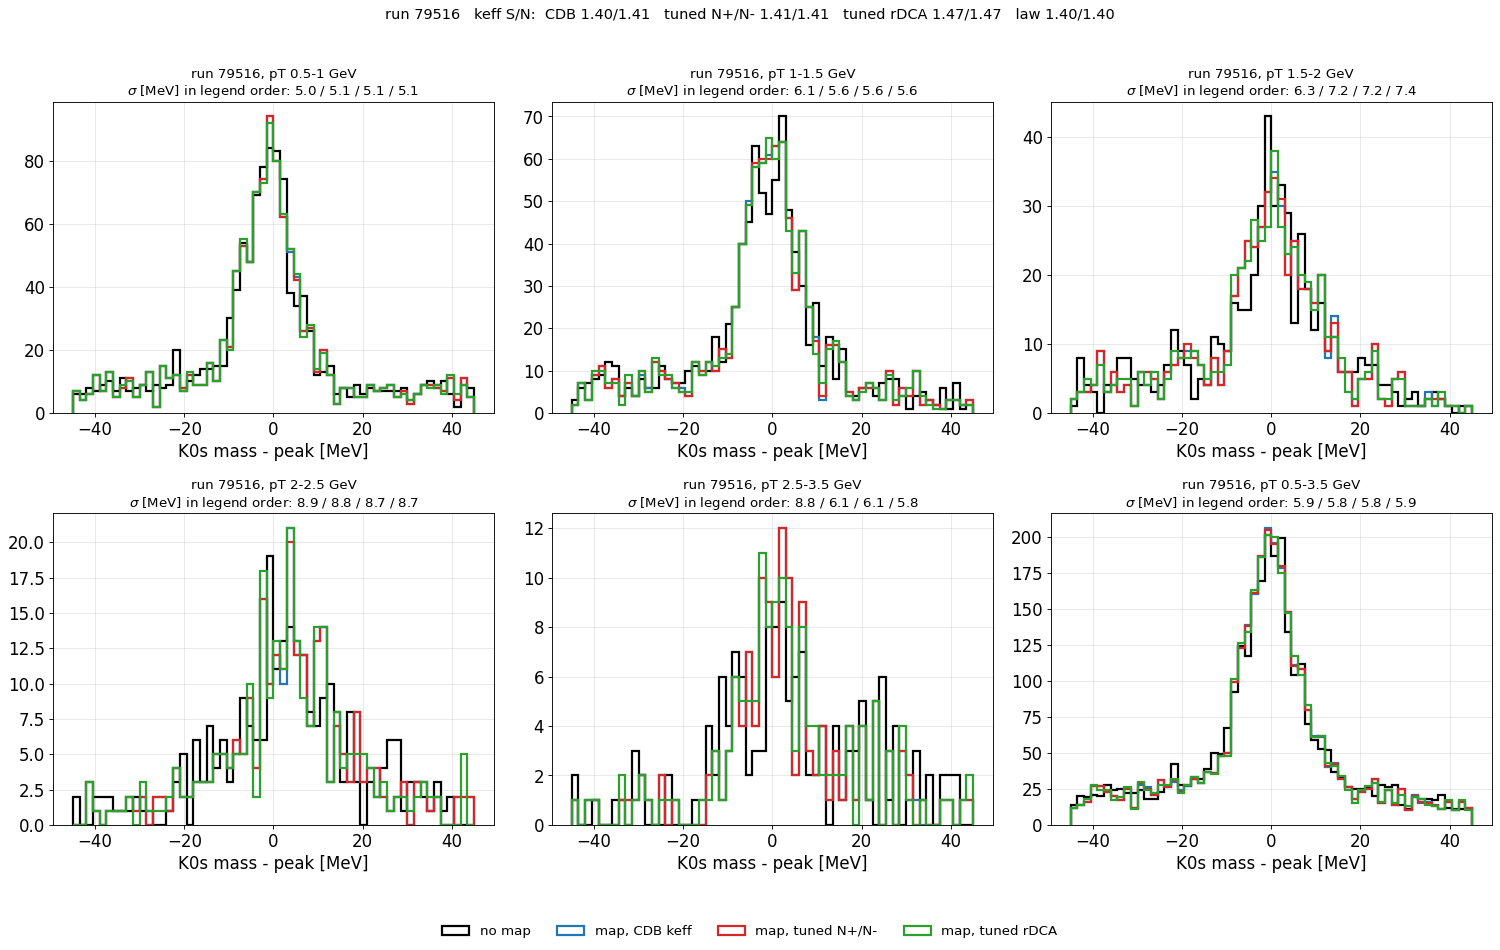

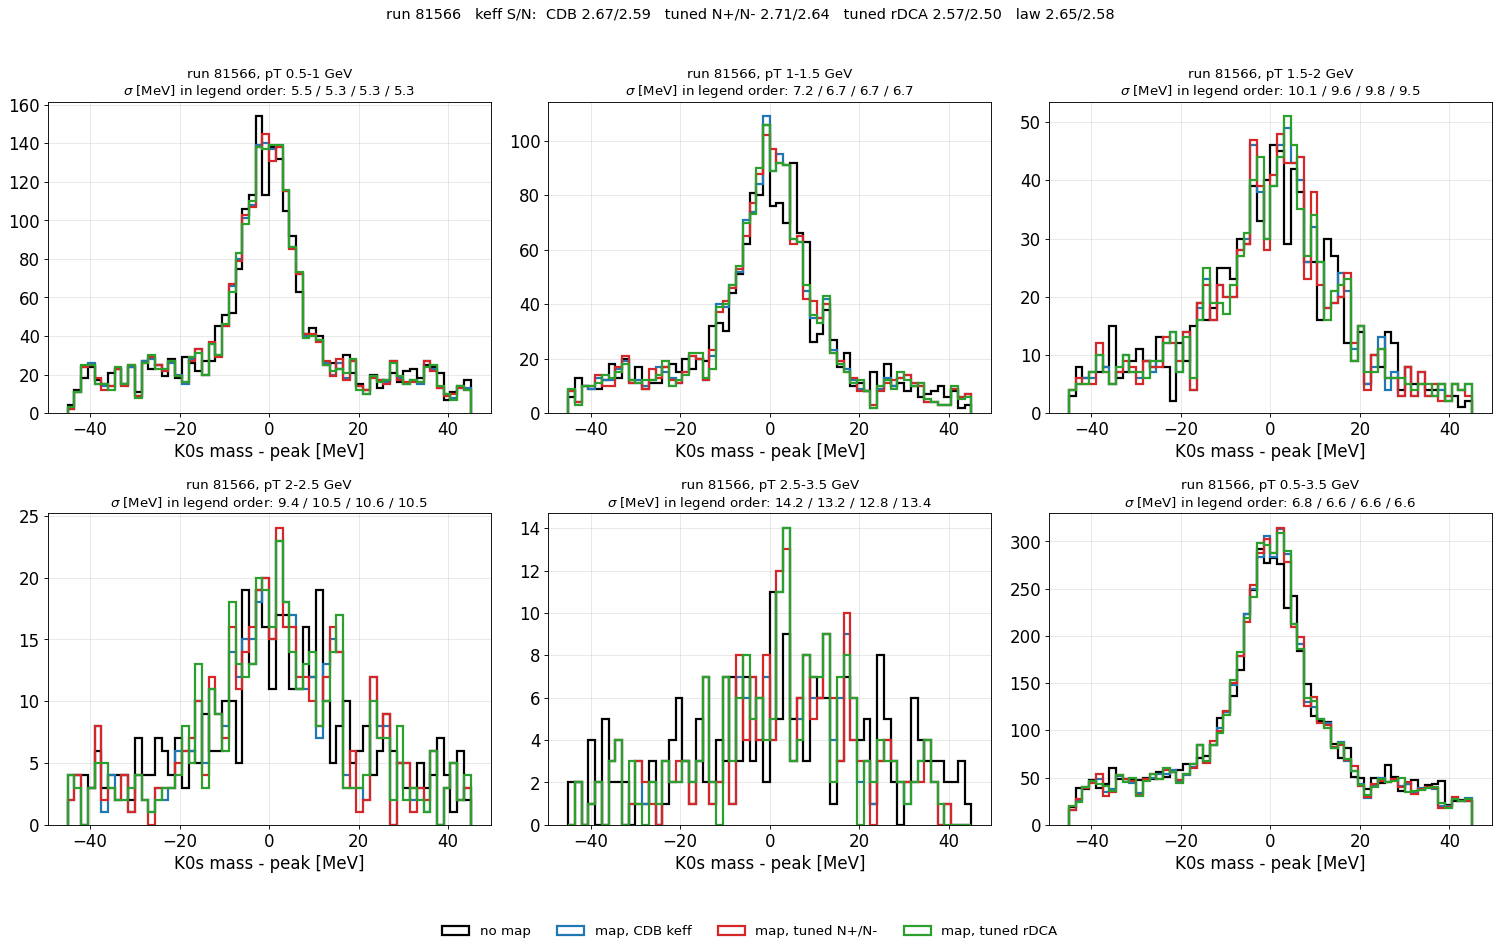

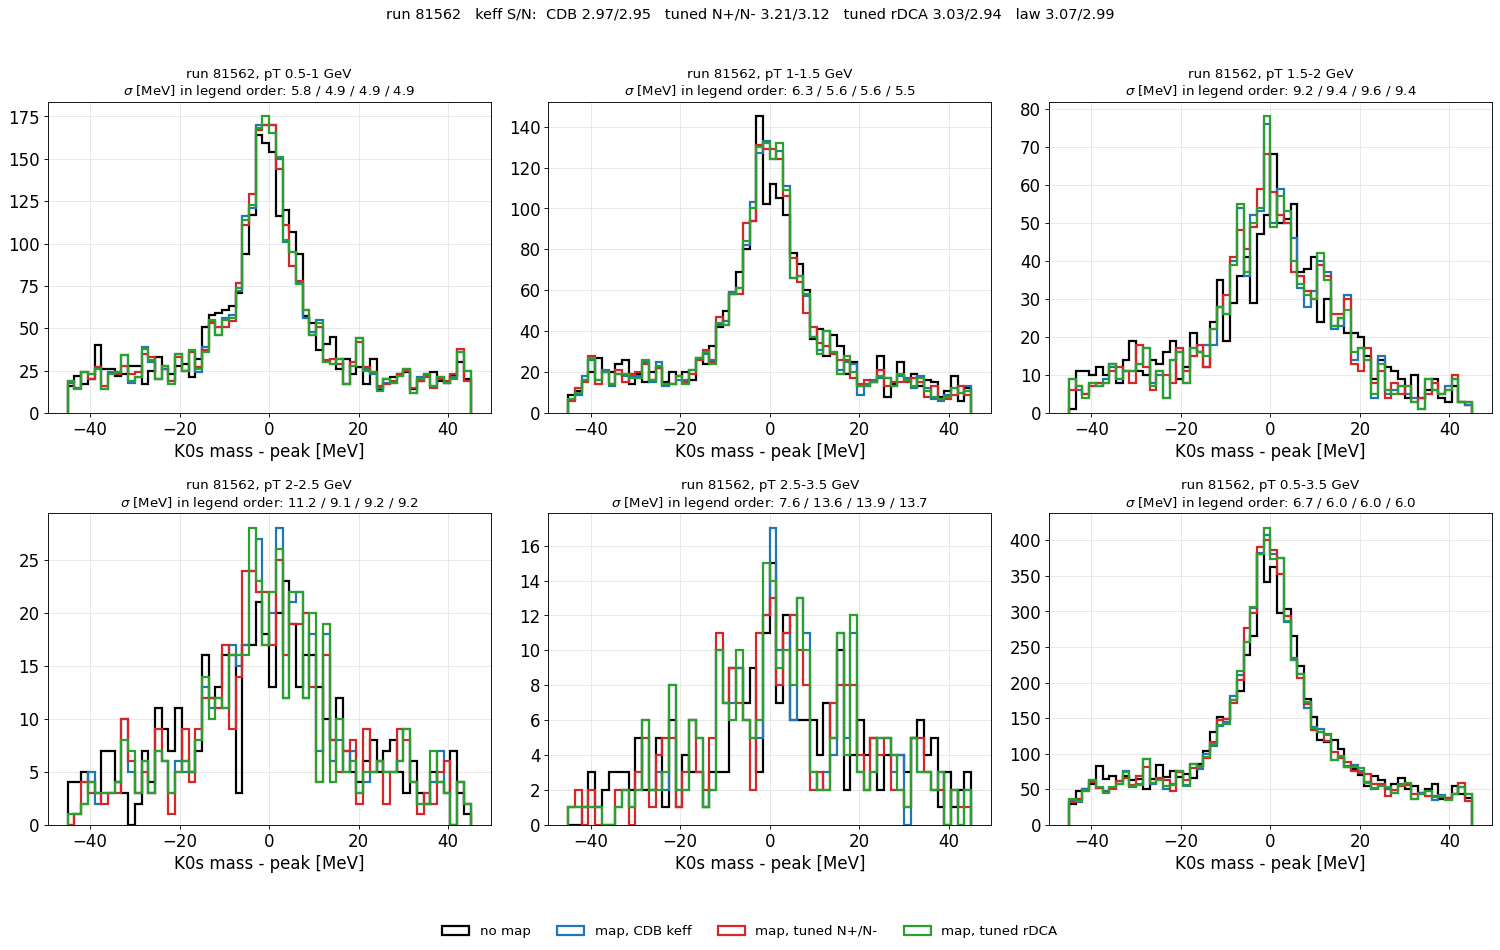

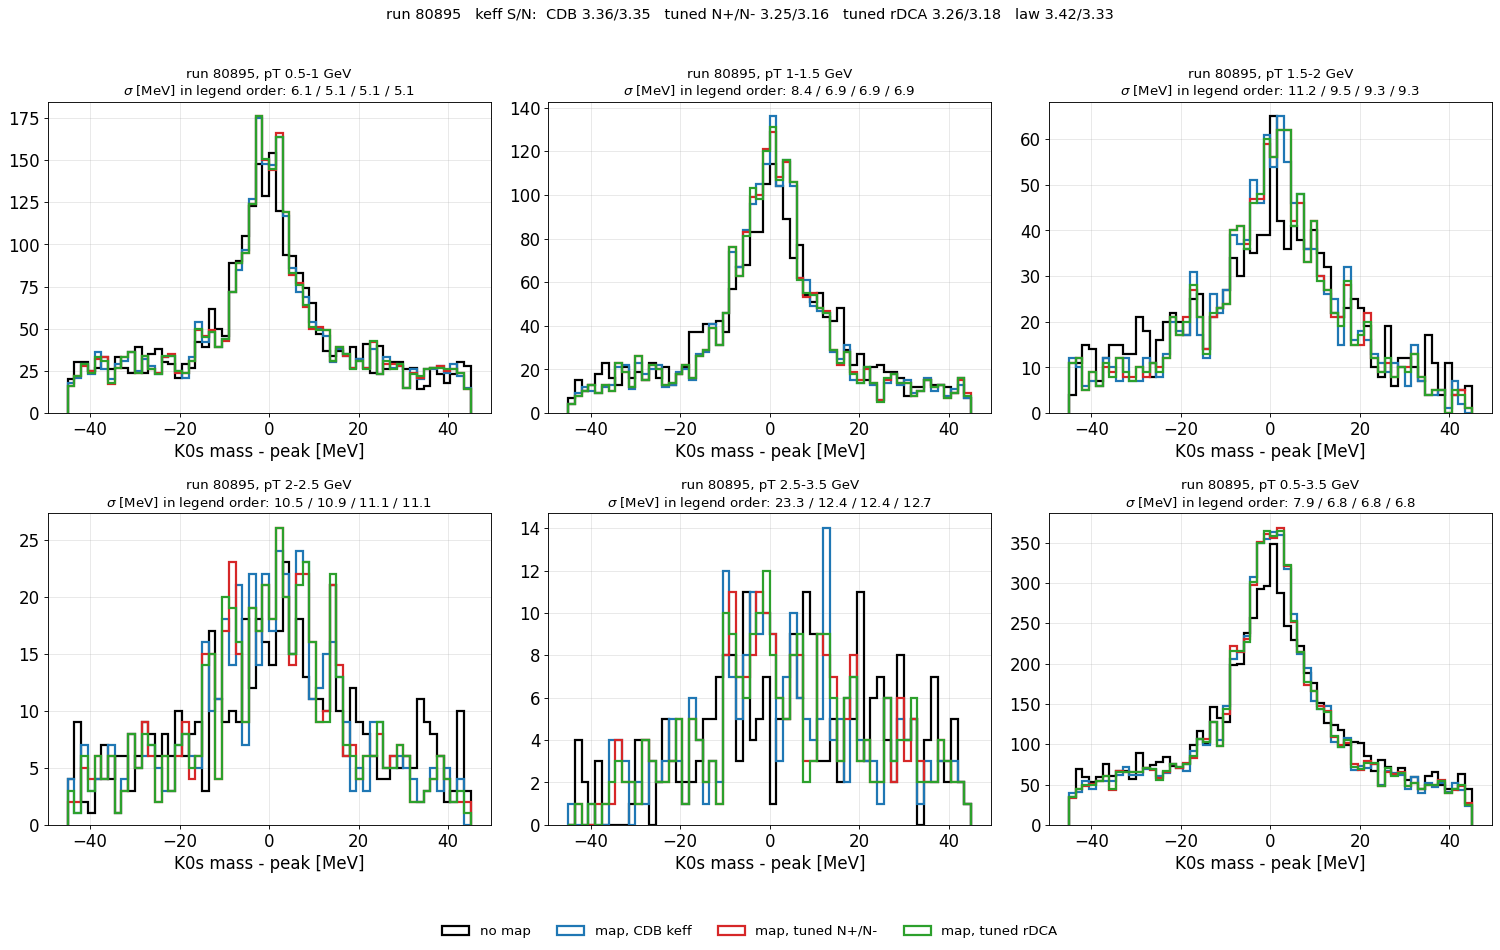

In [10]:
for r in RUNS_K:
    if r != '81558': peaks(r)

# Backup: pi+/pi- yield ratio of the K0s daughters, all other runs

Inside and outside the mass window, signal minus sideband, and the change caused by the map / keff; all five configurations.

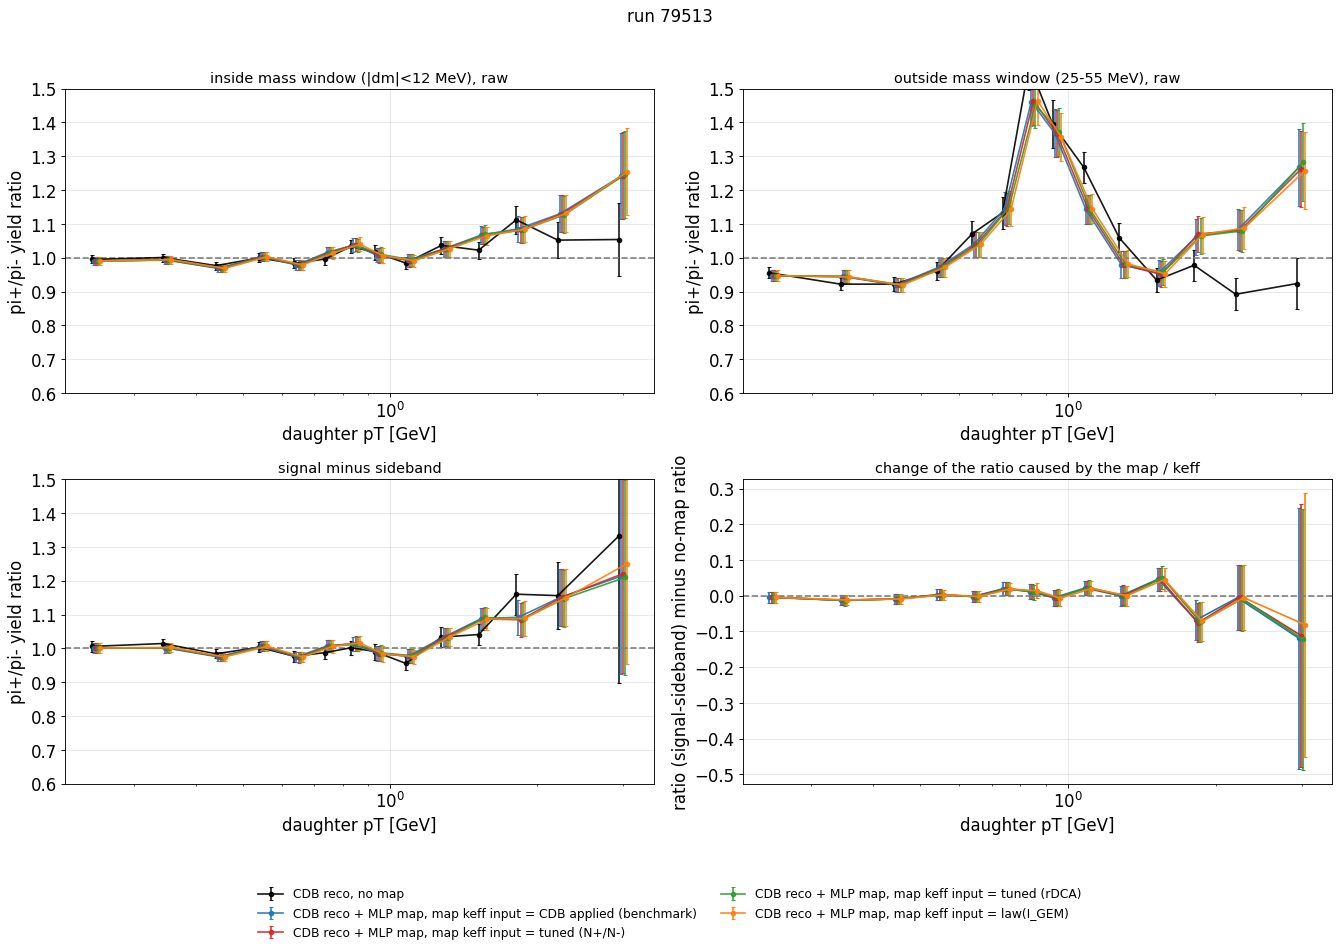

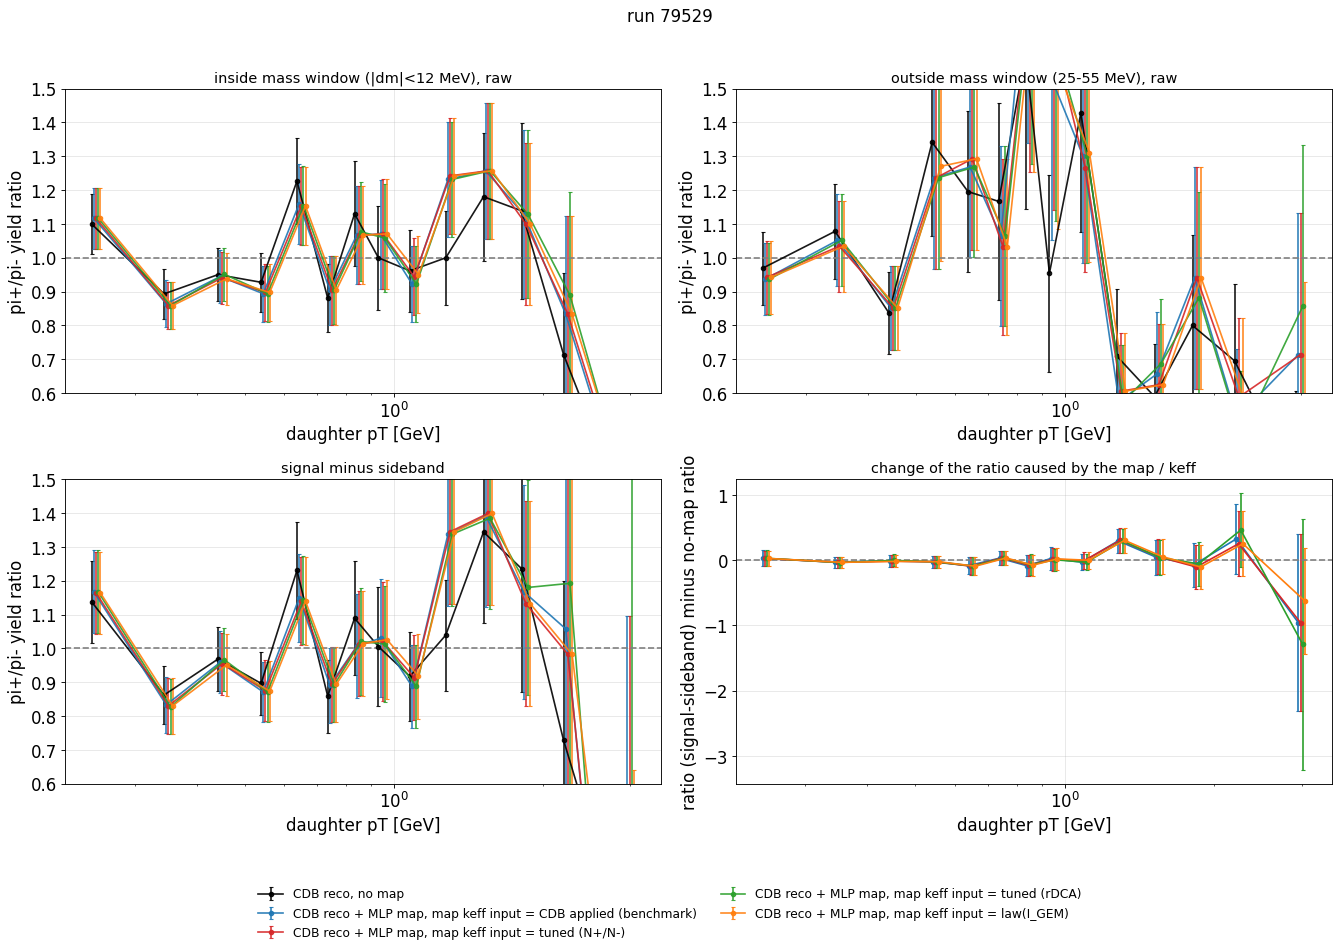

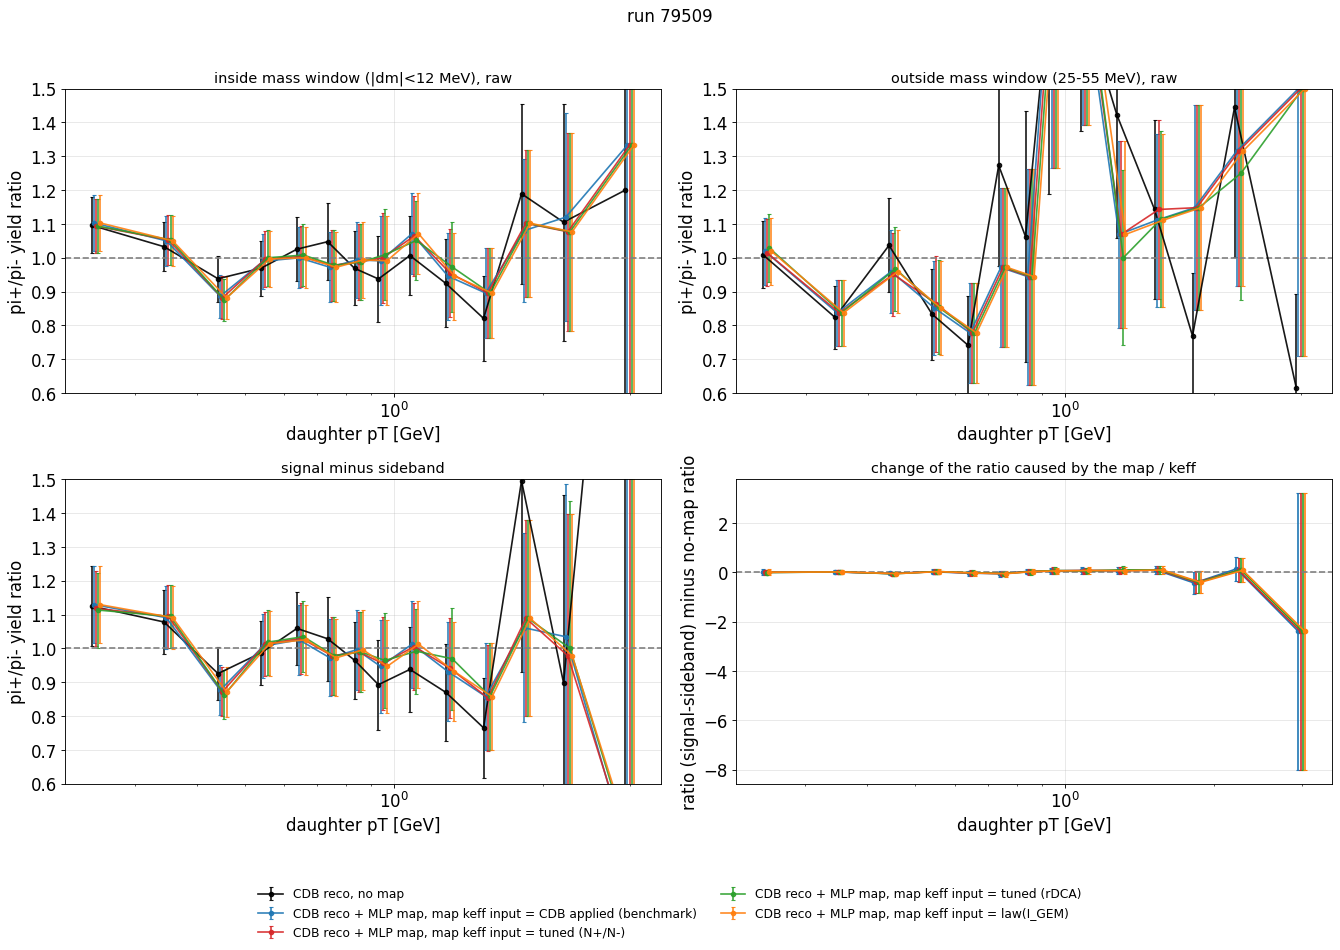

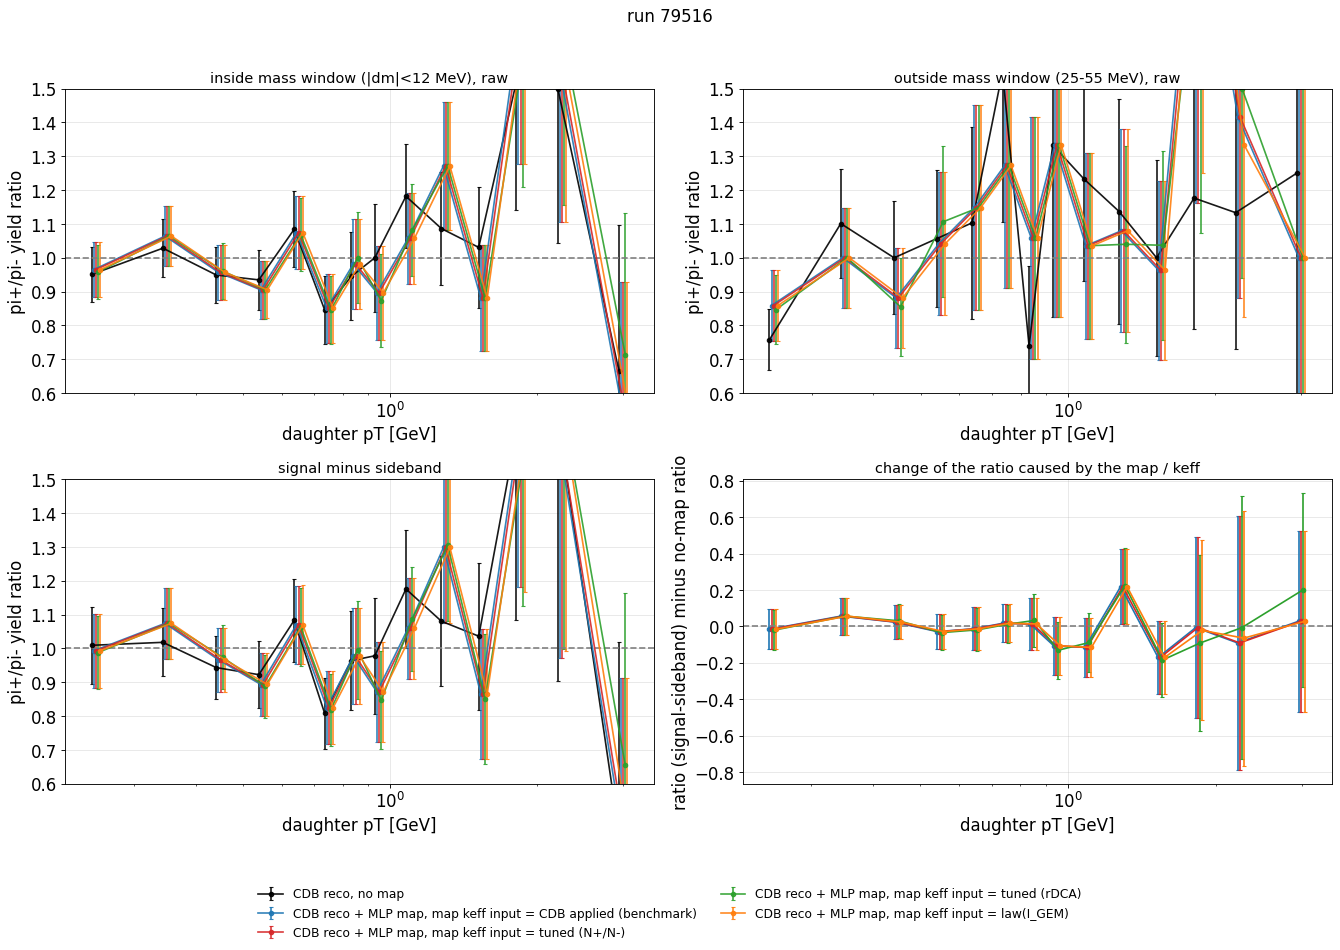

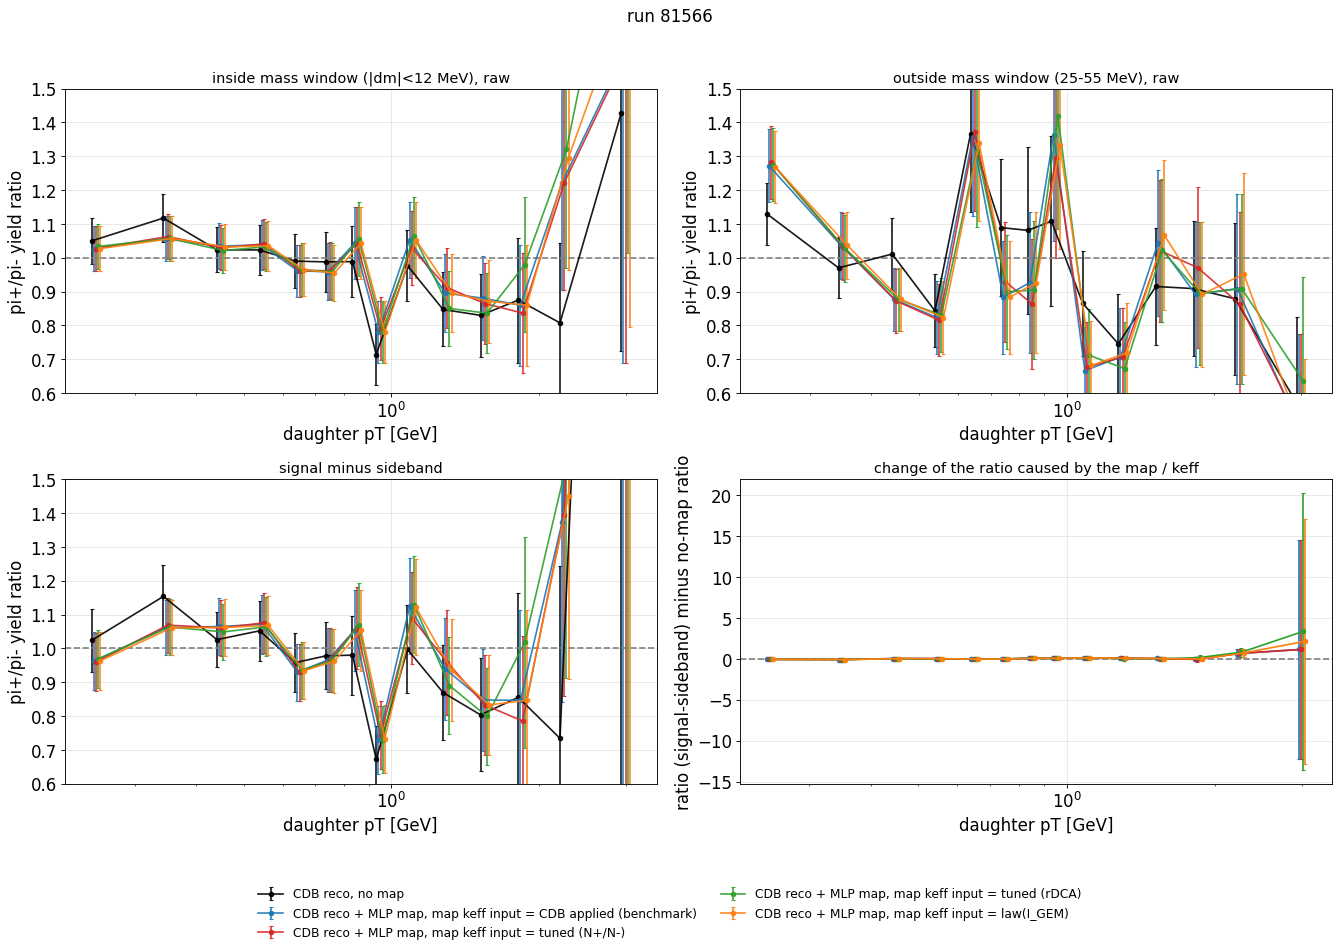

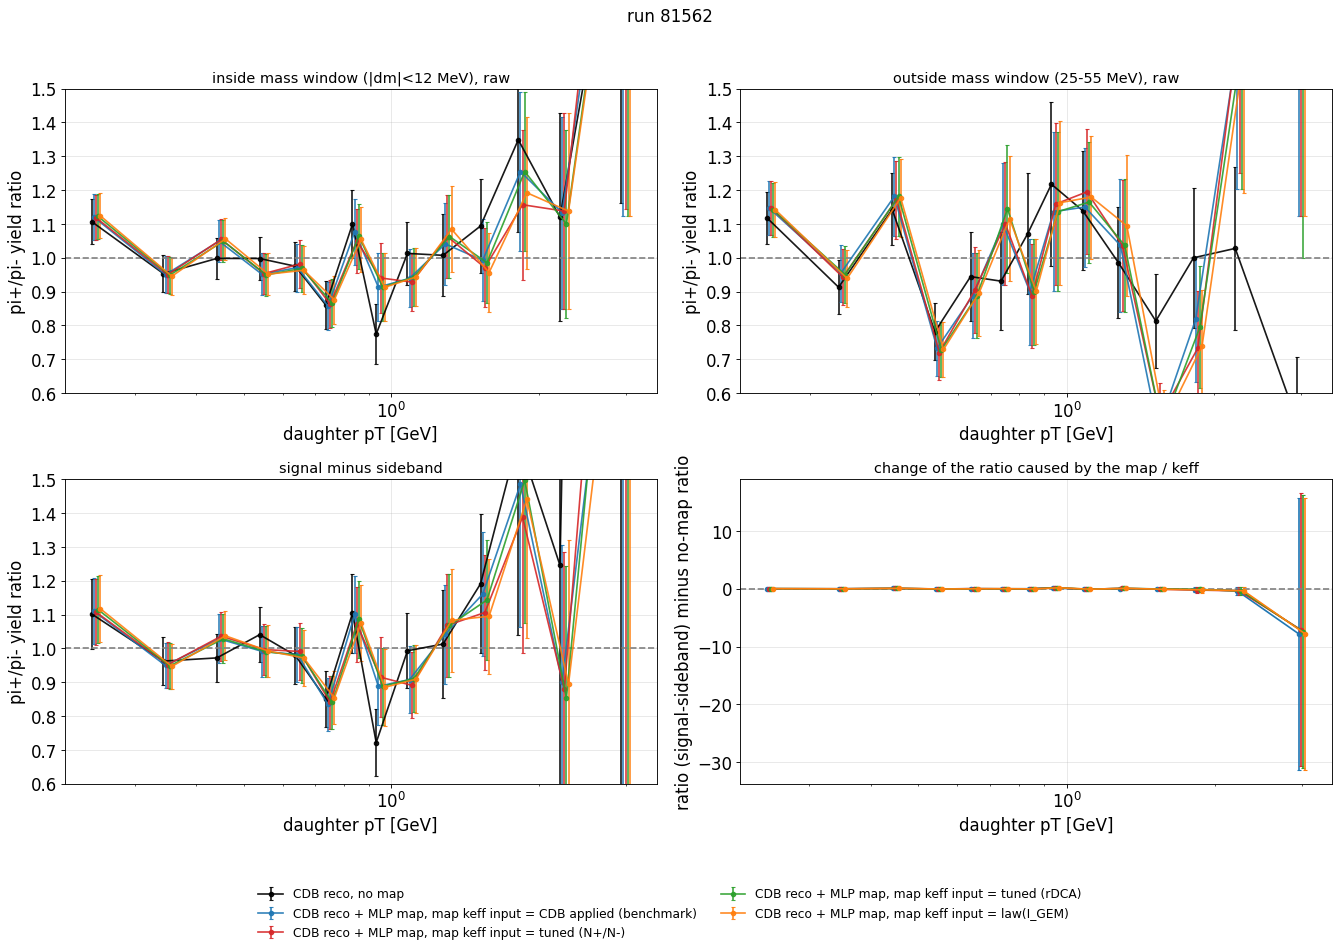

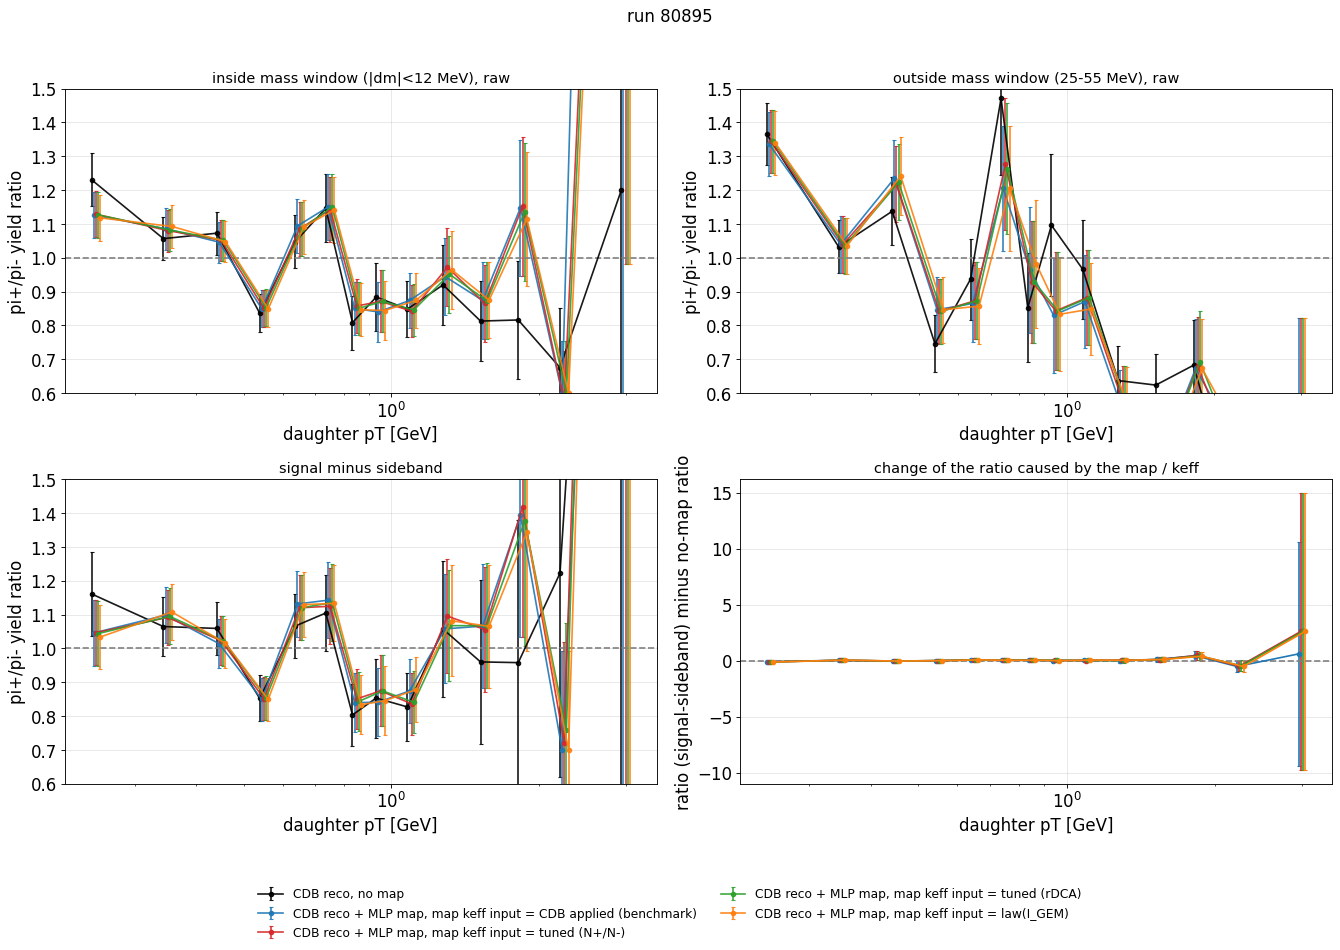

In [11]:
for r in RUNS_K:
    if r != '81558': pi_fig(r)

# Backup: O+O K0s mass peaks per run and keff point

Mass minus fitted peak position, three keff factors (x0.95 / x1.05 / x1.15 of the base keff), same segments for the three points; left pT 0.5-1.2 GeV, right 1.2-3.0 GeV. sigma in the legends from a Gaussian + linear background fit. Also saved as PNG in Talks/Others/pics/261112/kscan_peaks/.

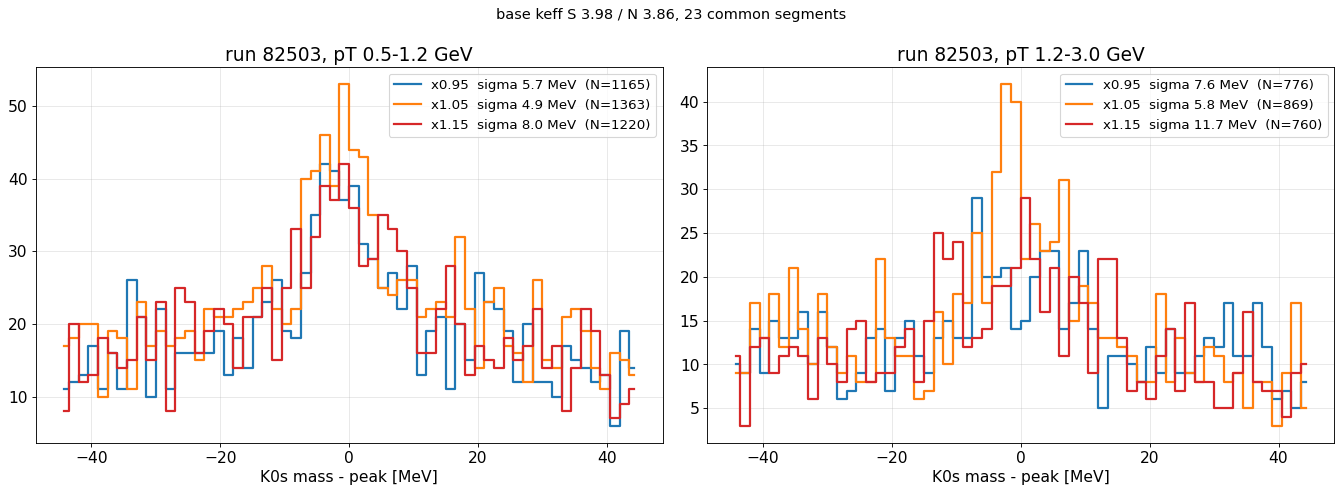

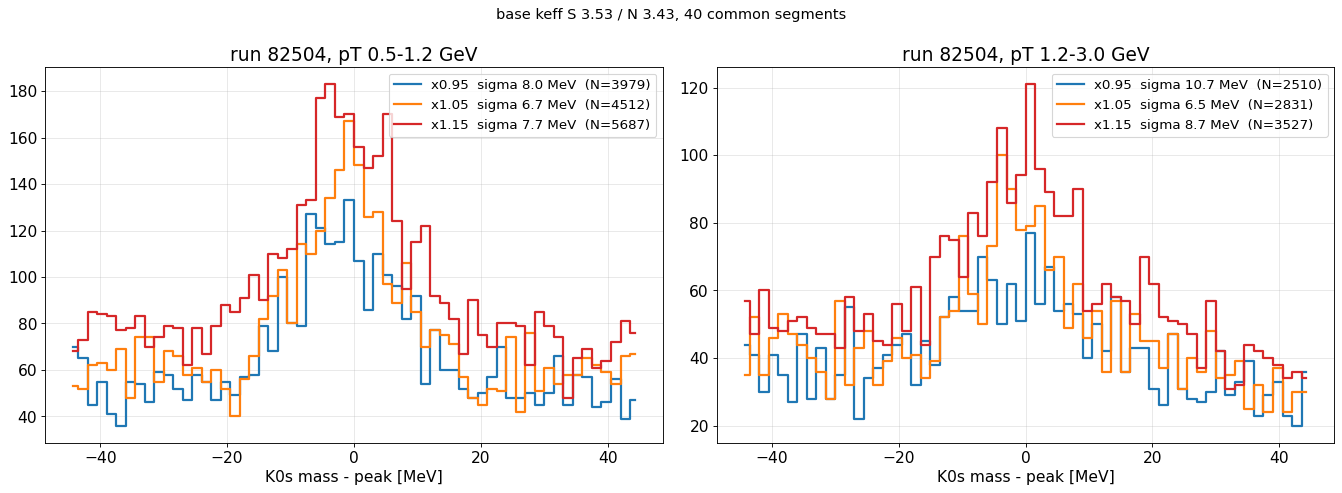

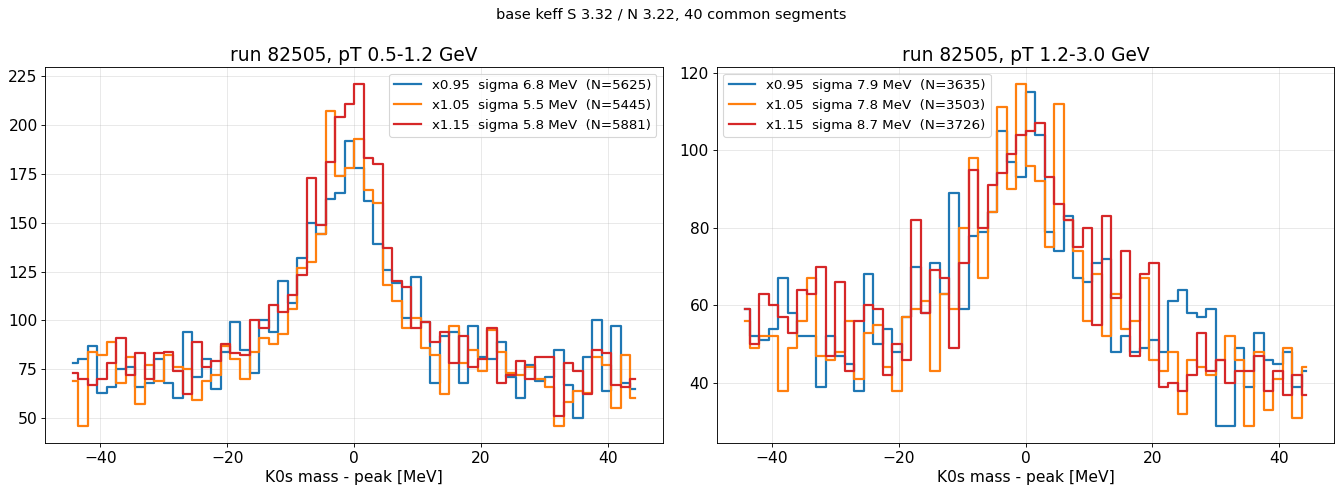

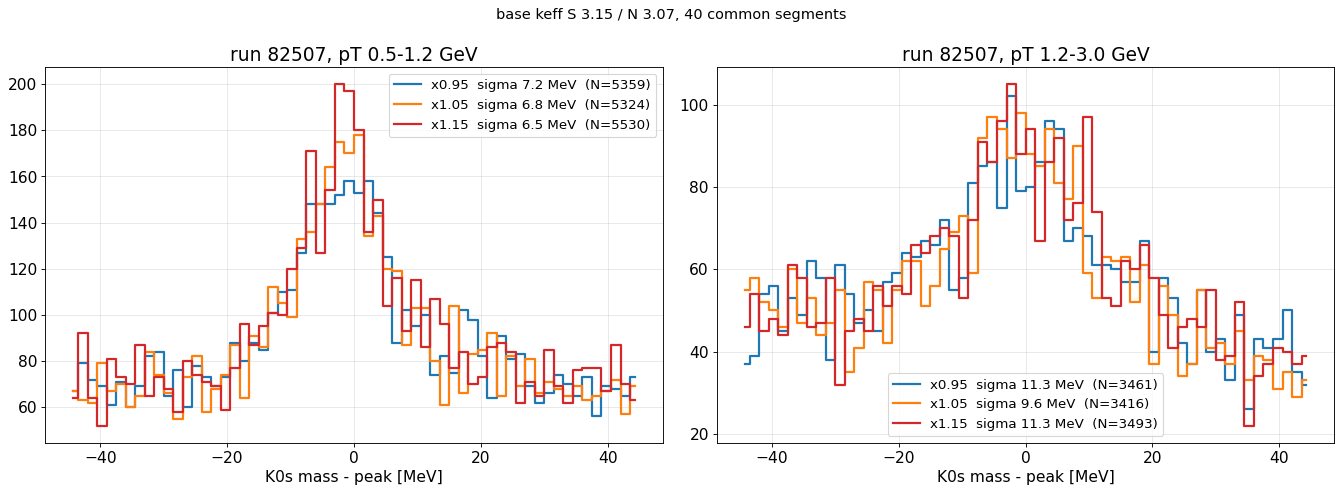

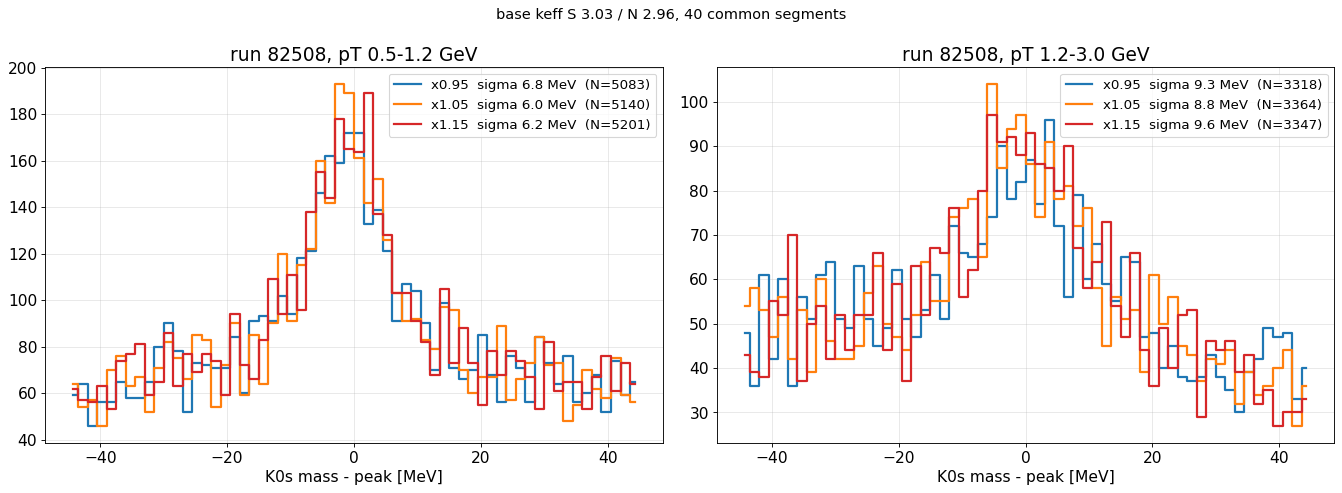

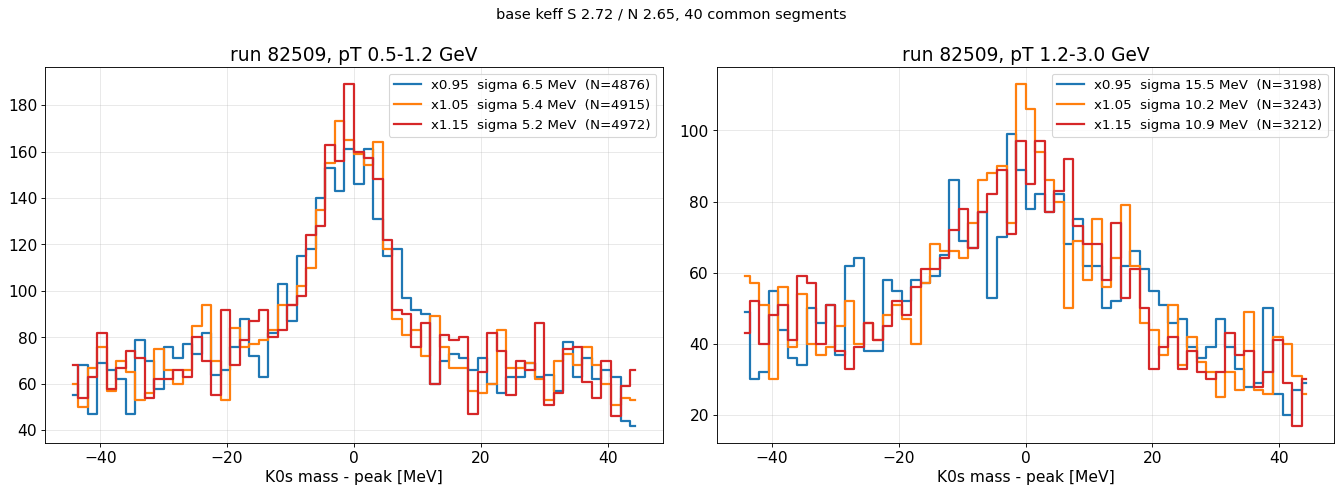

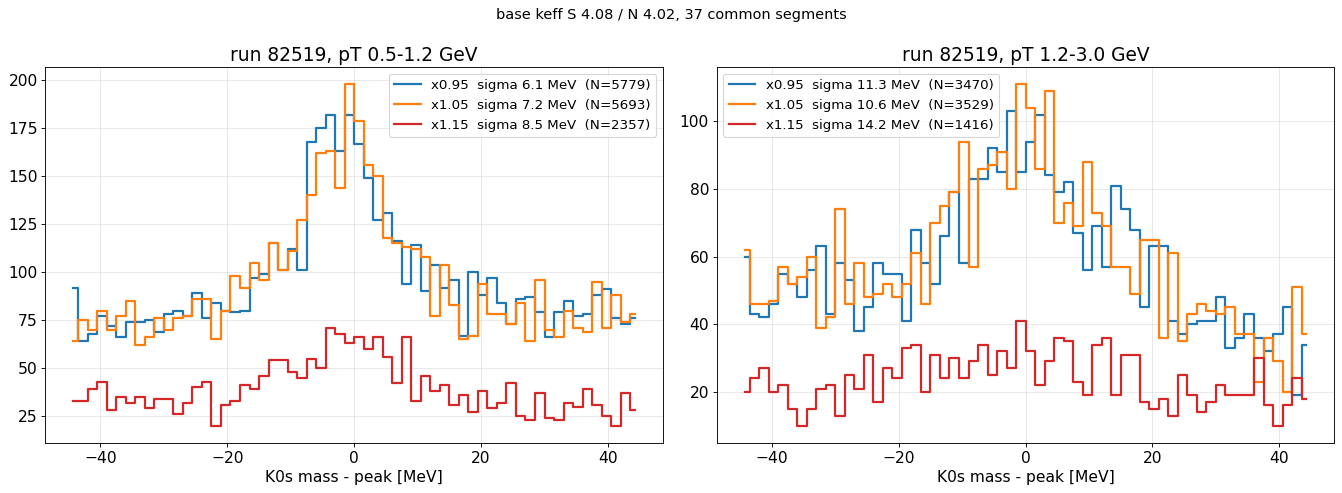

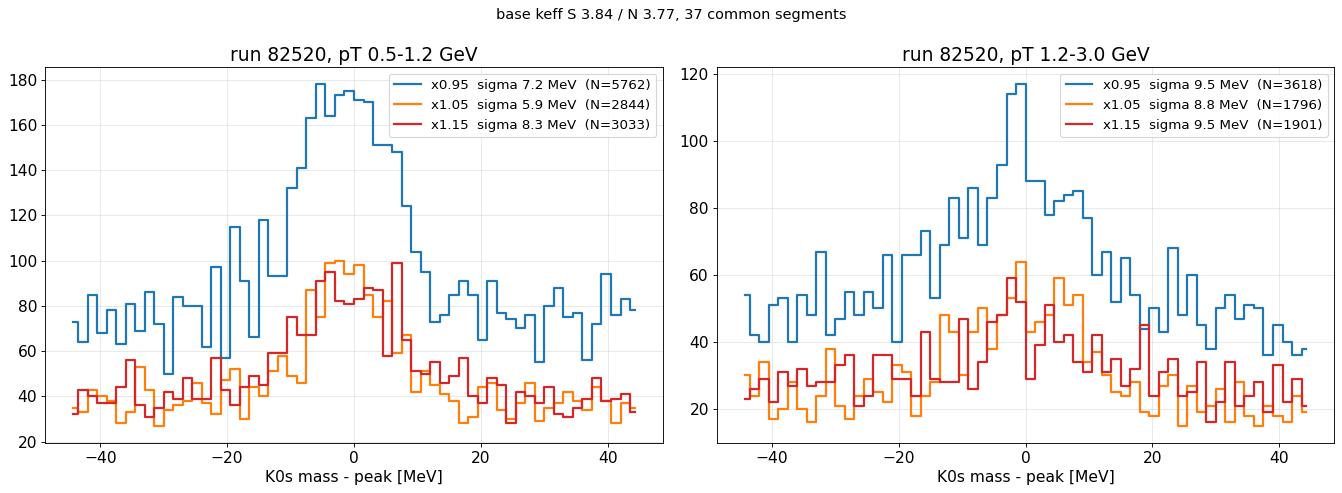

/tmp/ipykernel_16740/1046961182.py:6: OptimizeWarning: Covariance of the parameters could not be estimated
  try: p, _ = curve_fit(fn, hc, h, p0=[h.max(), 0, 7, max(h.min(), 0), 0], maxfev=4000); return abs(p[2])


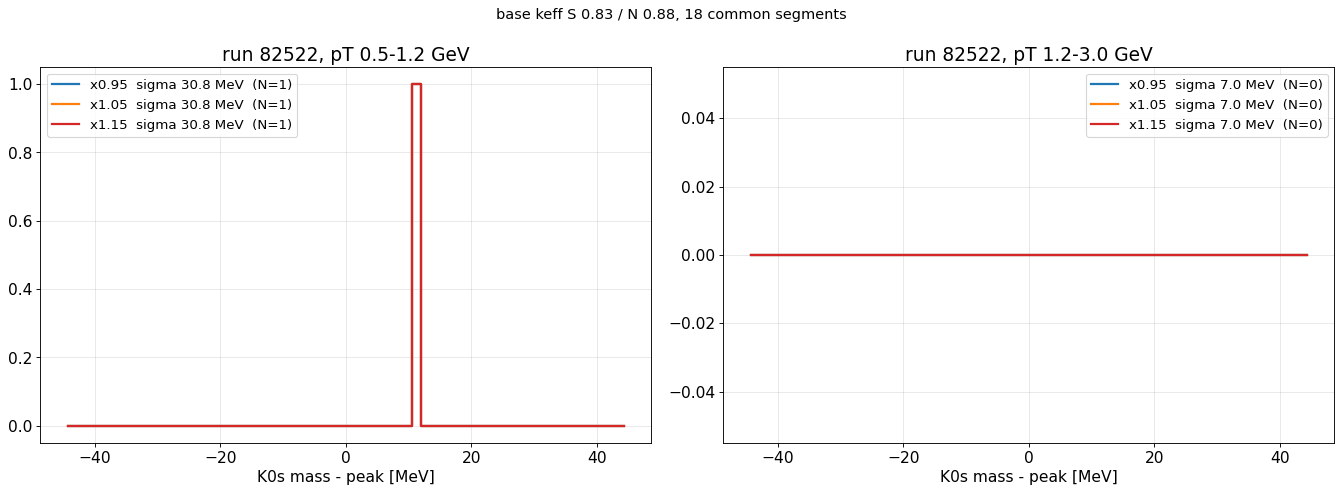

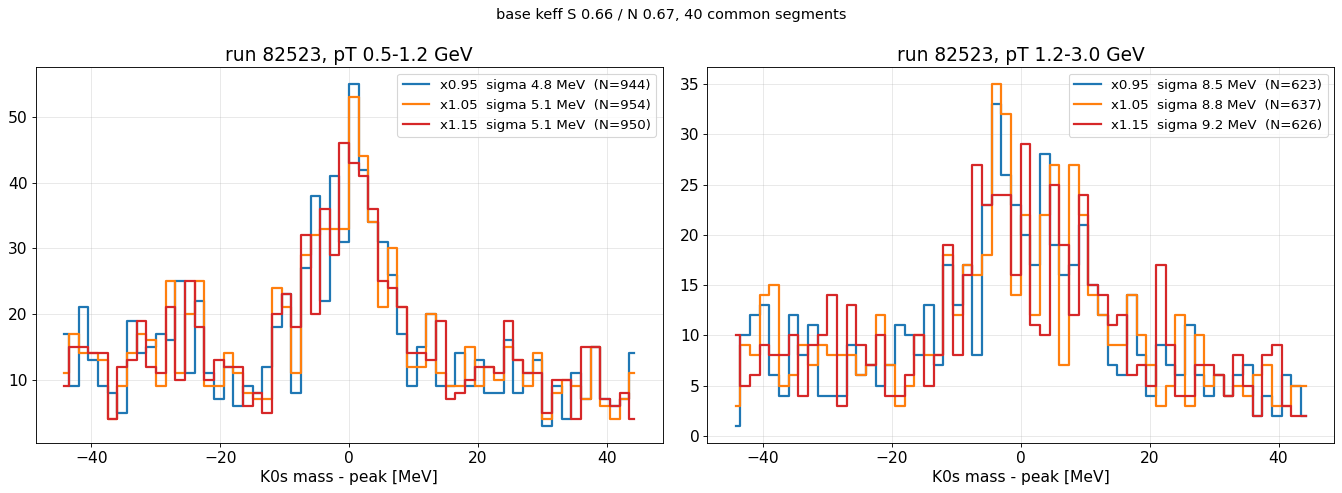

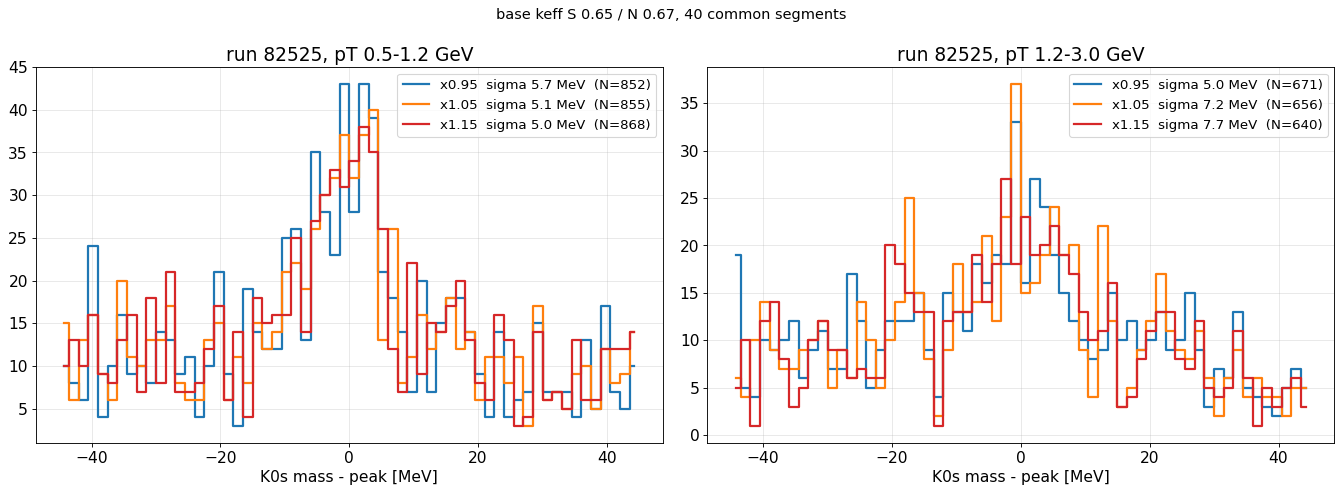

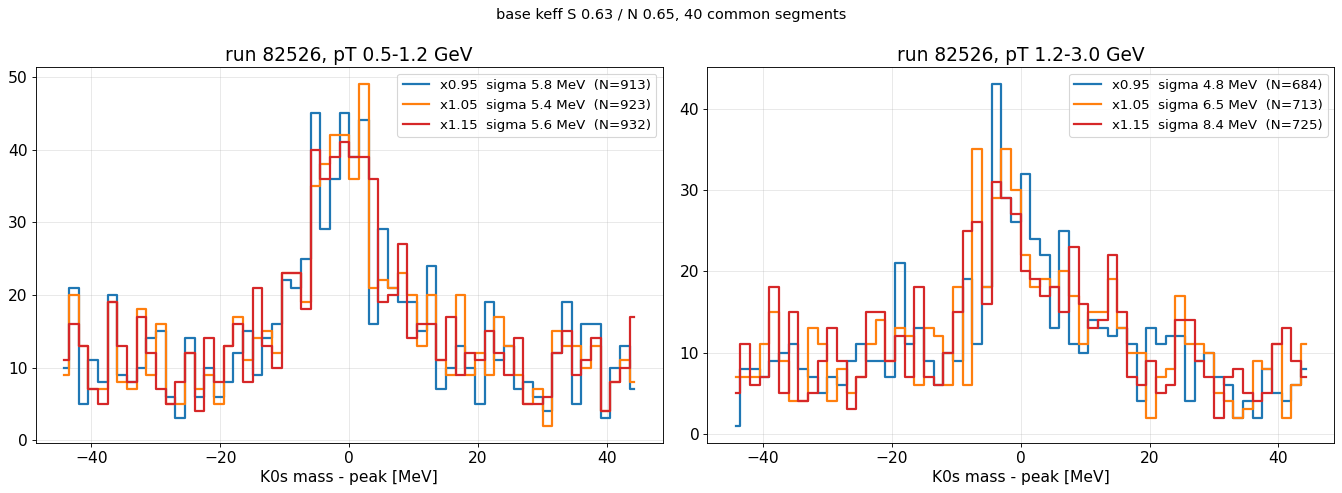

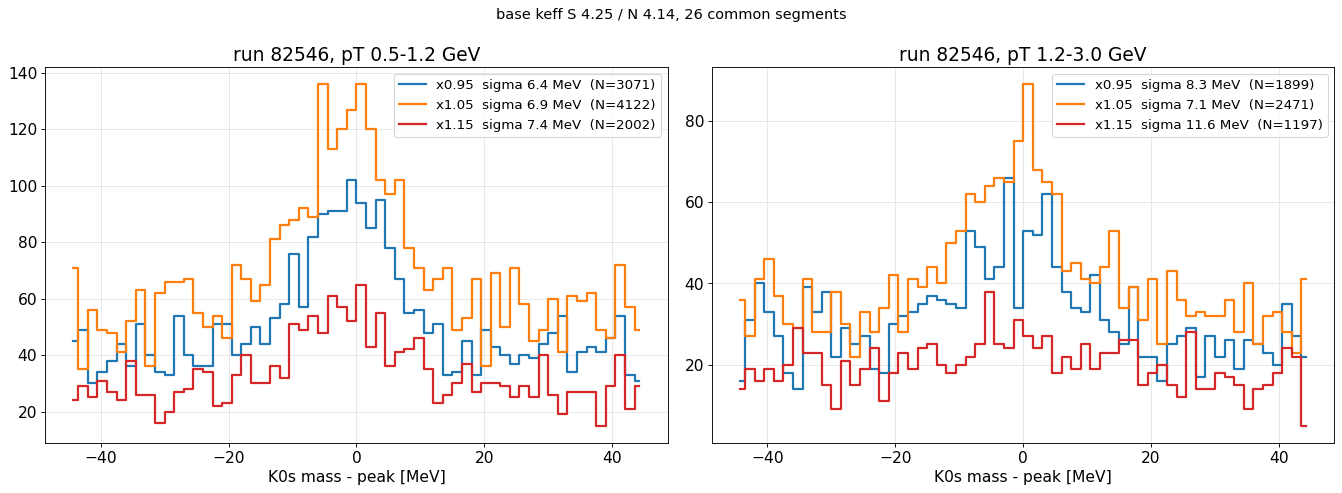

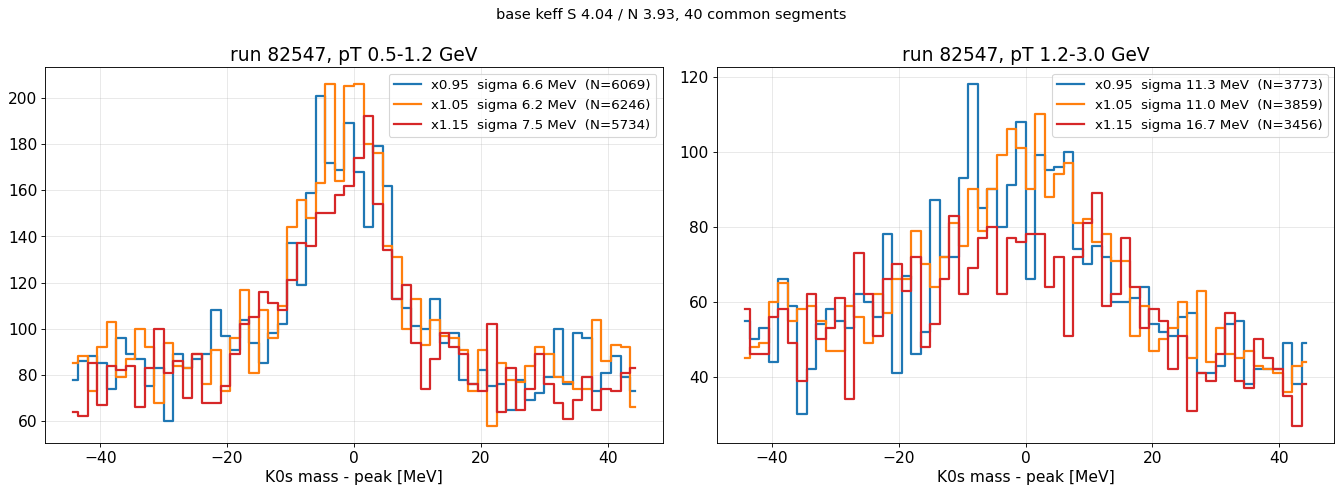

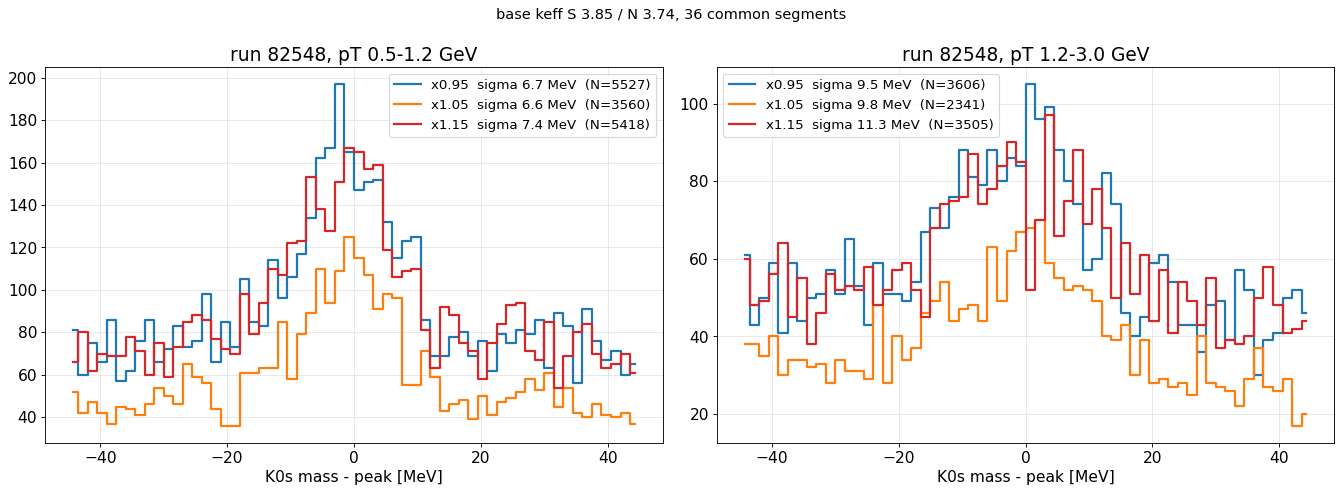

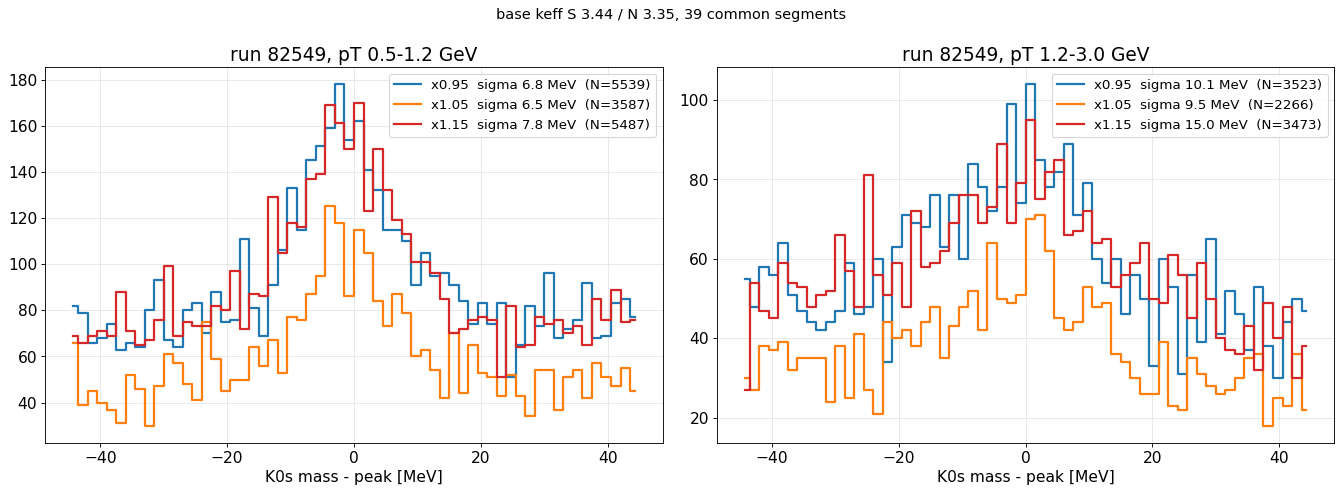

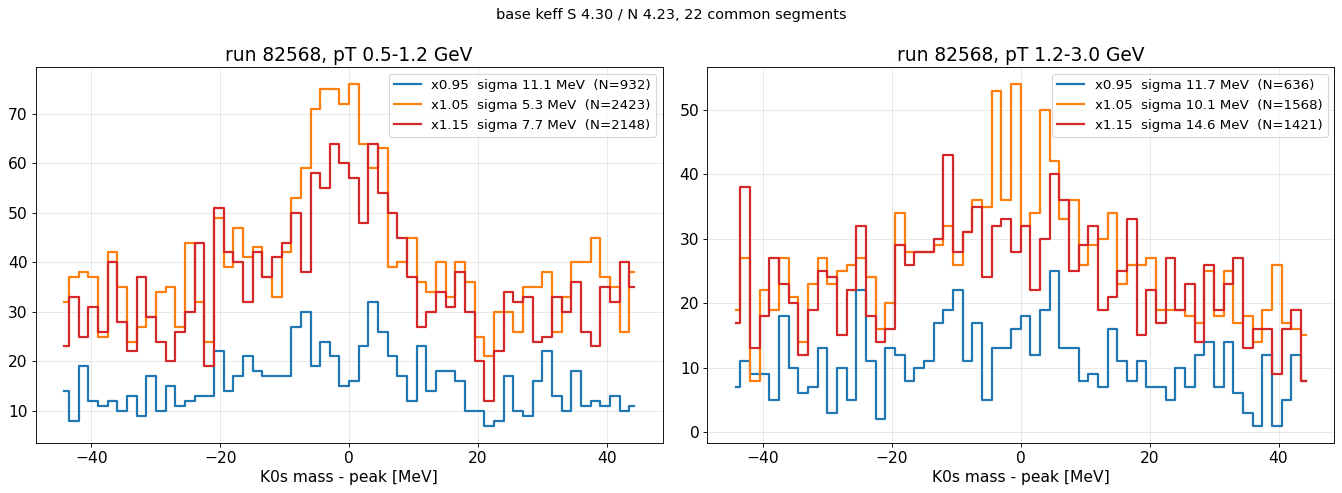

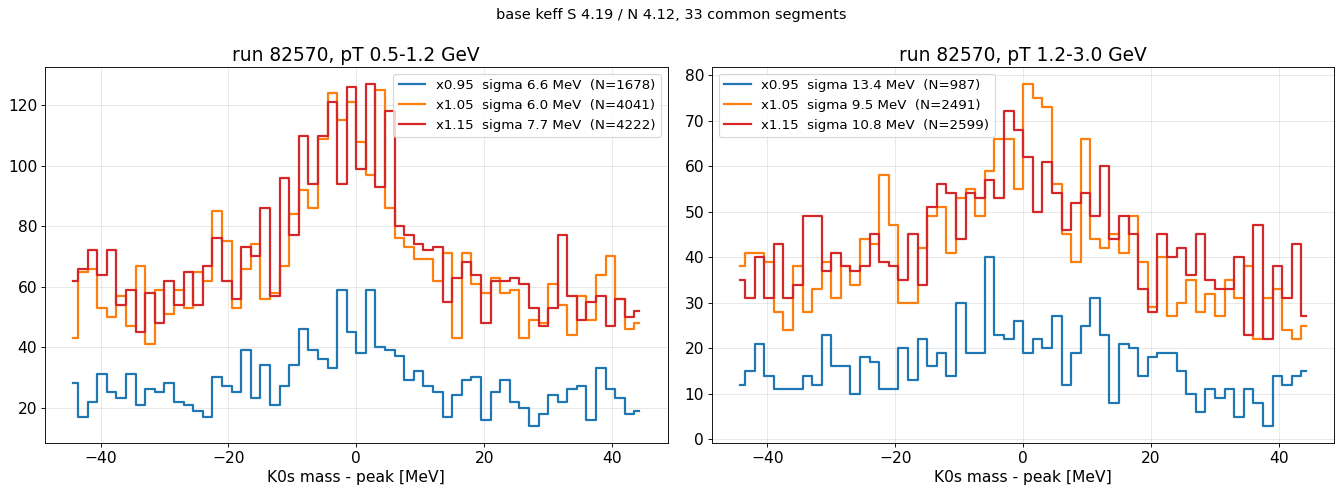

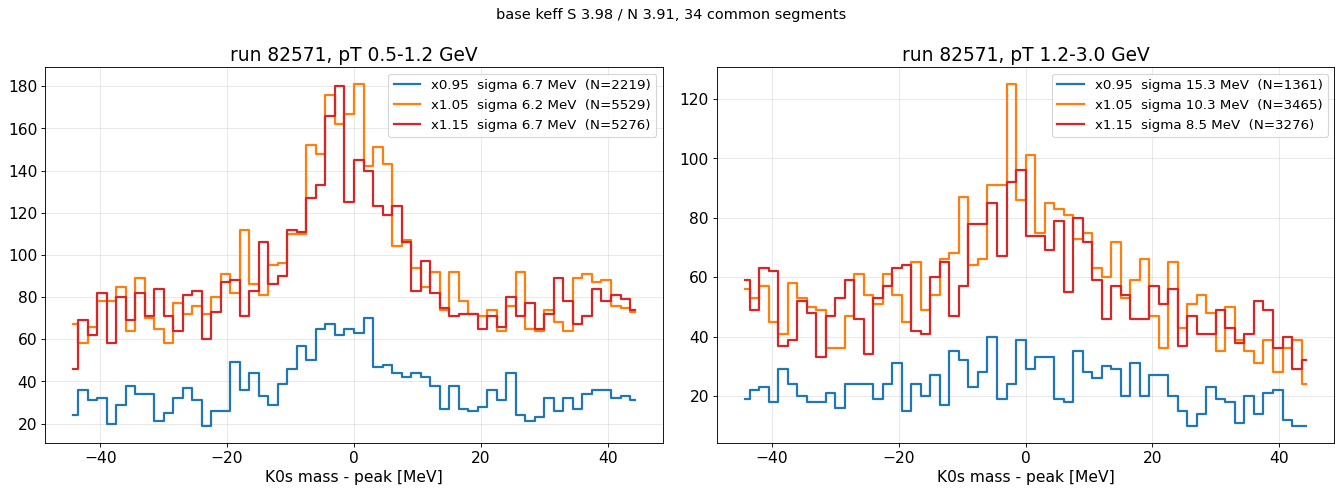

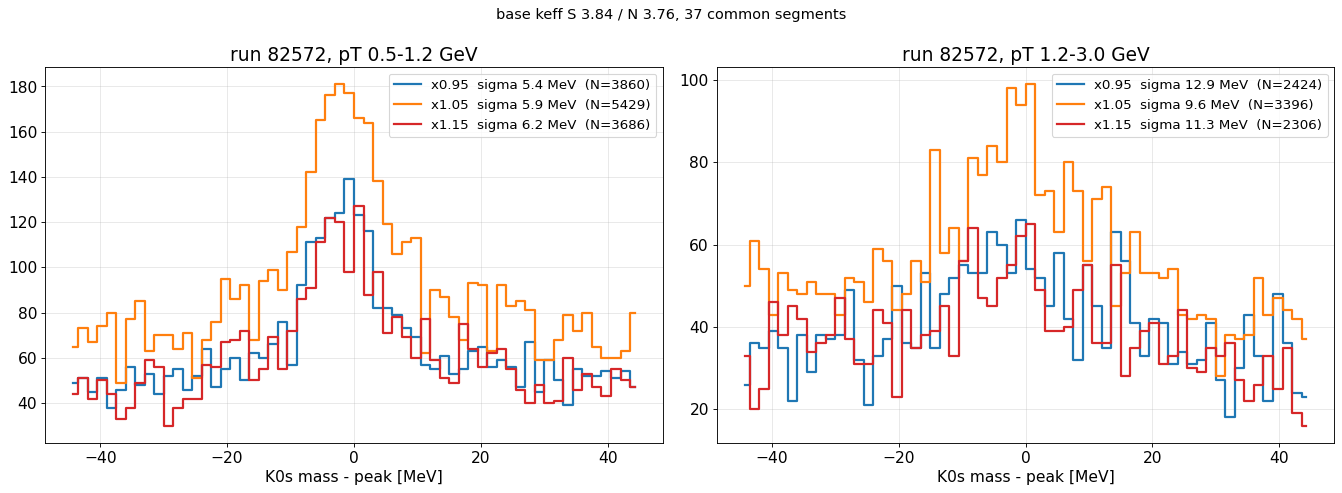

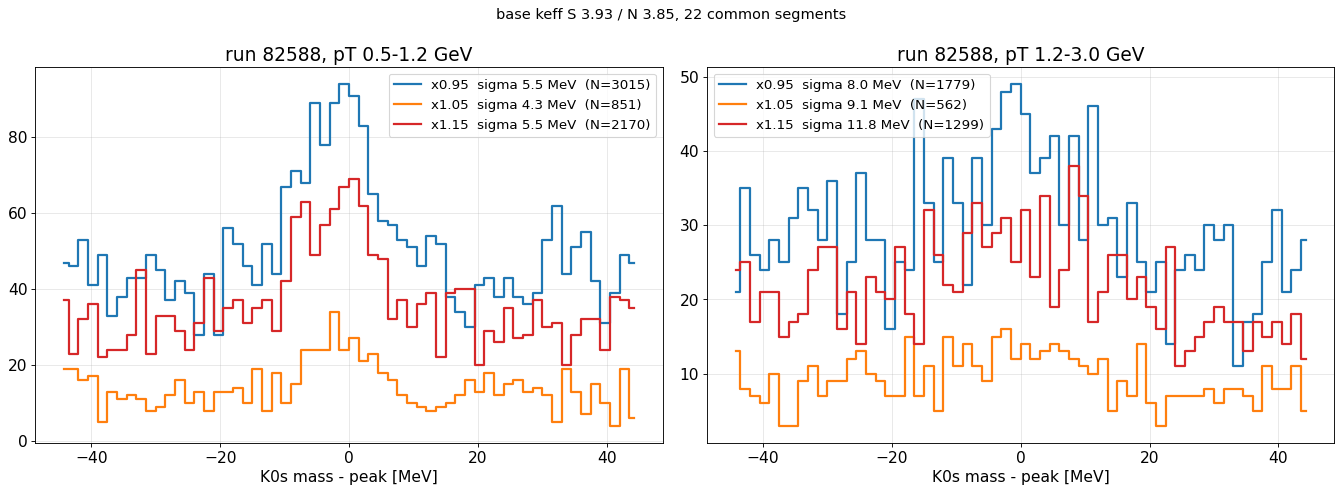

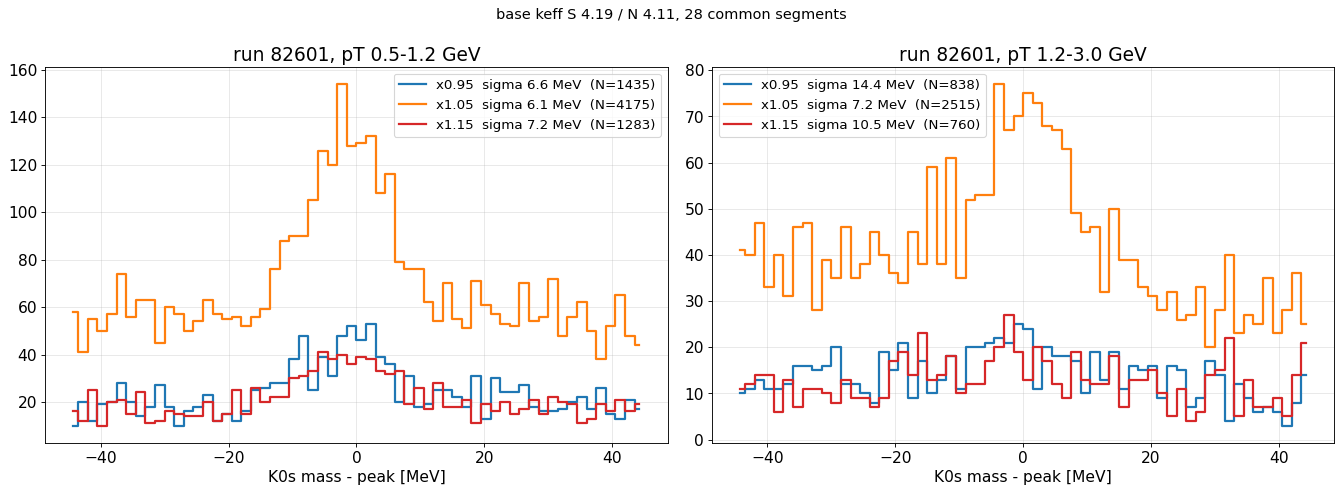

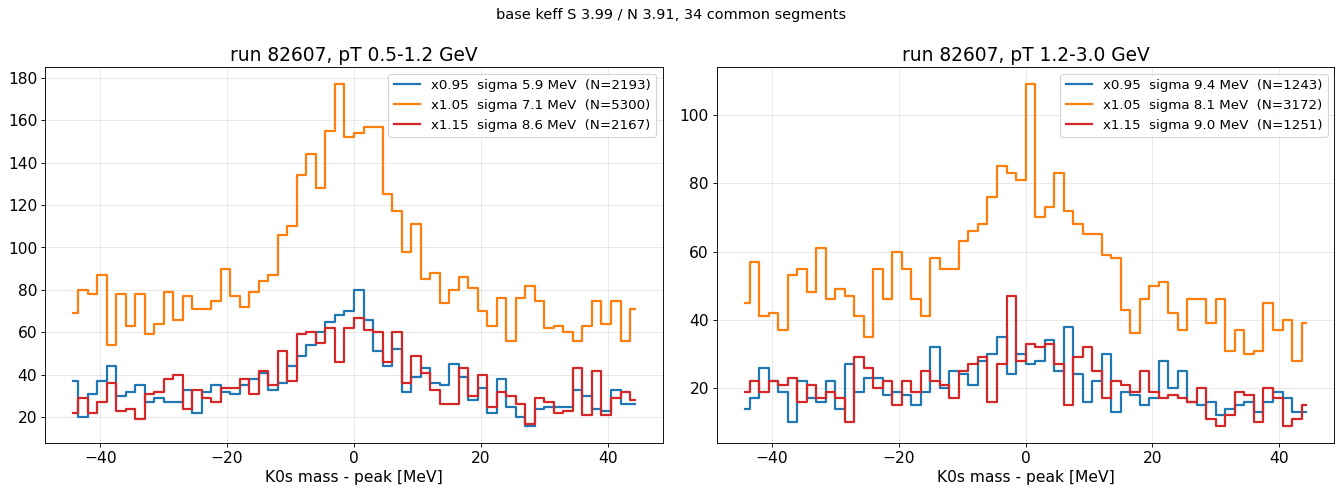

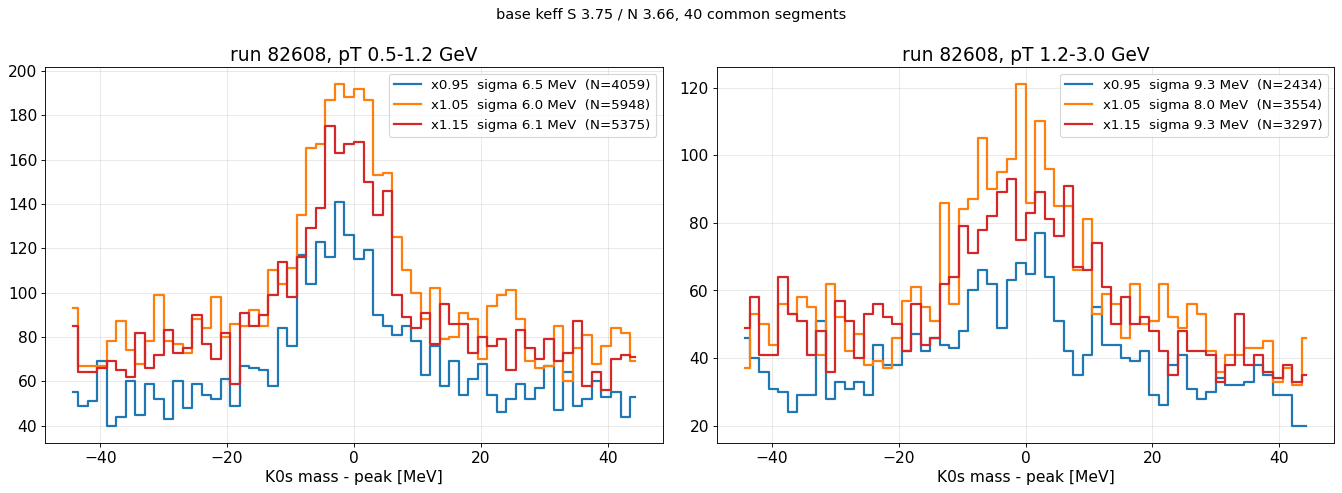

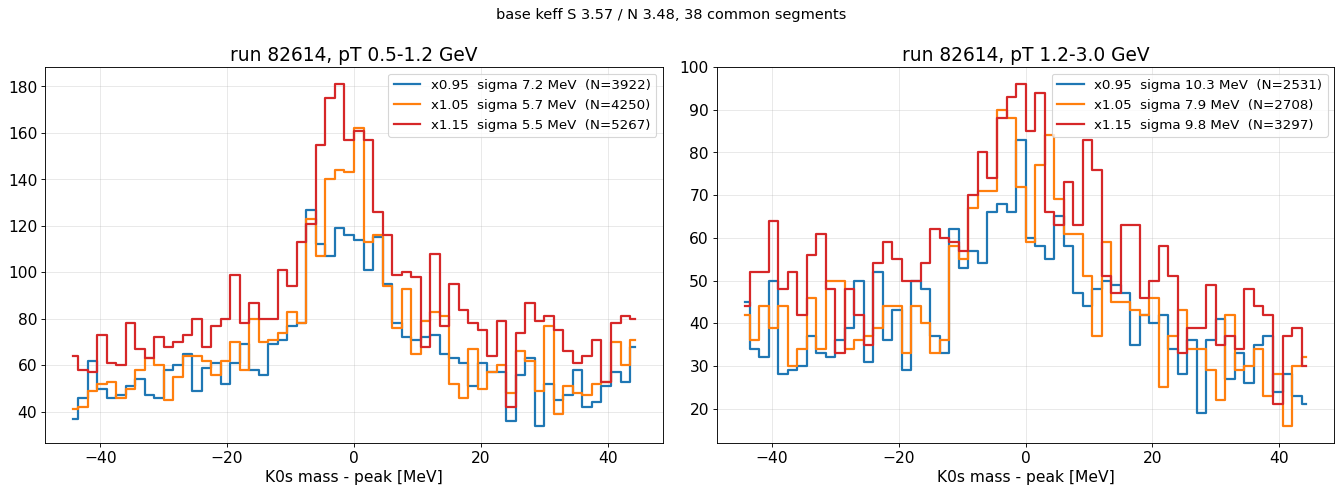

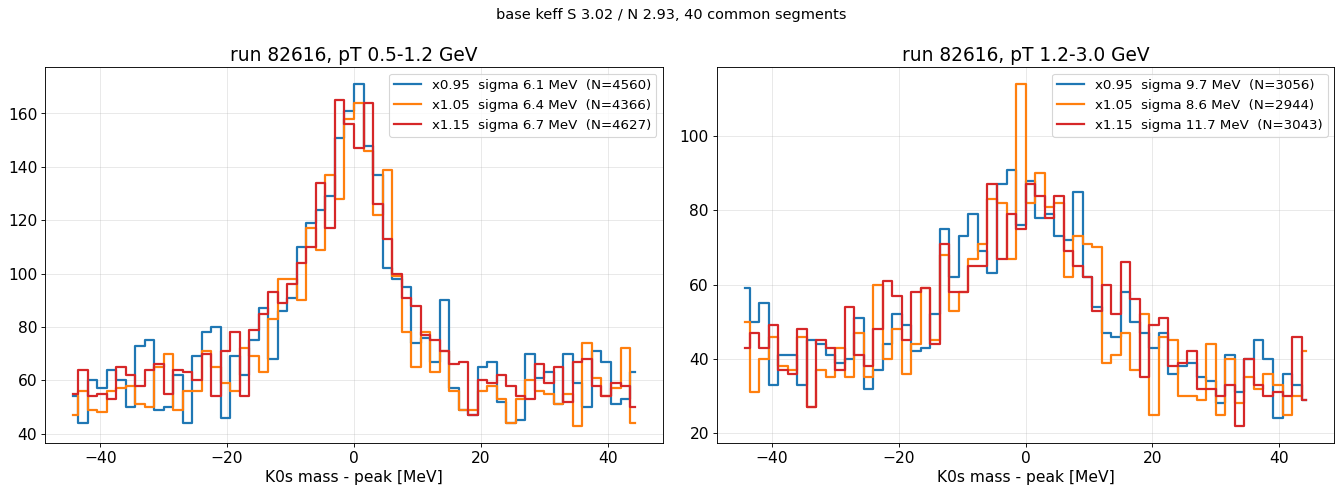

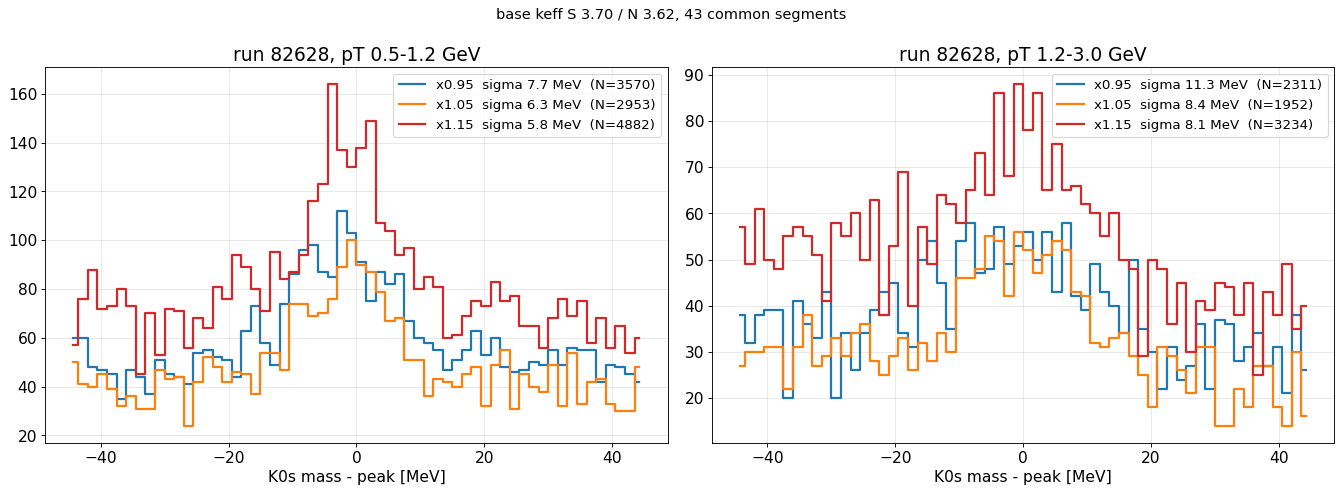

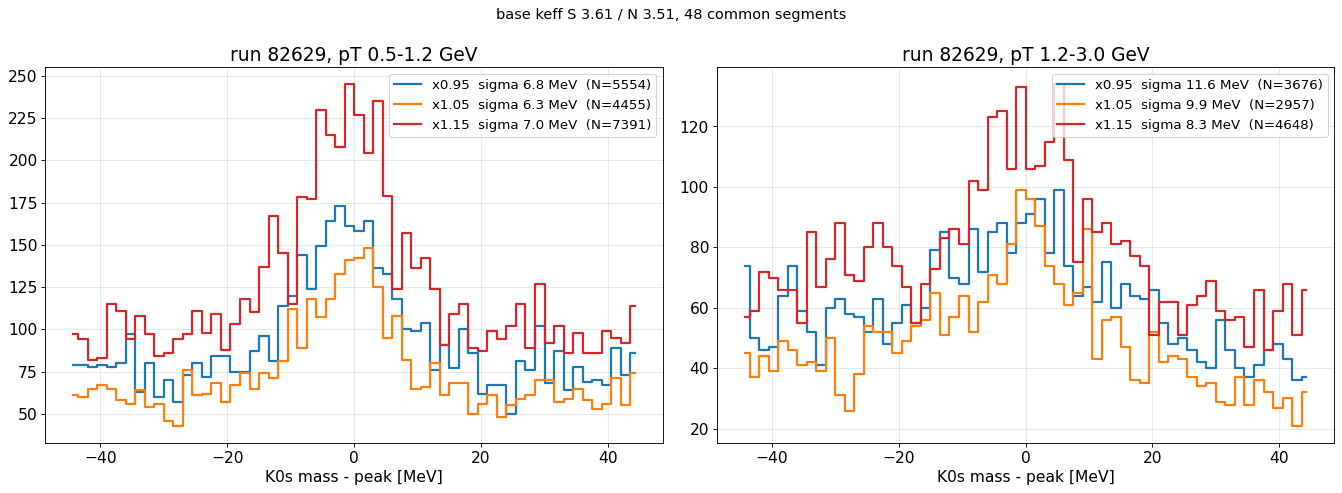

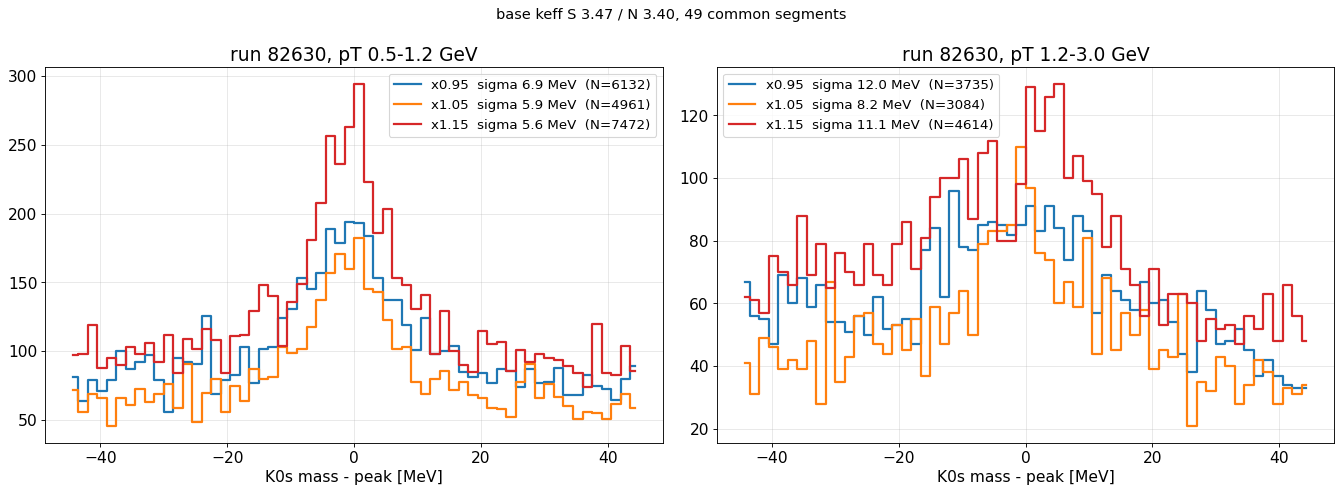

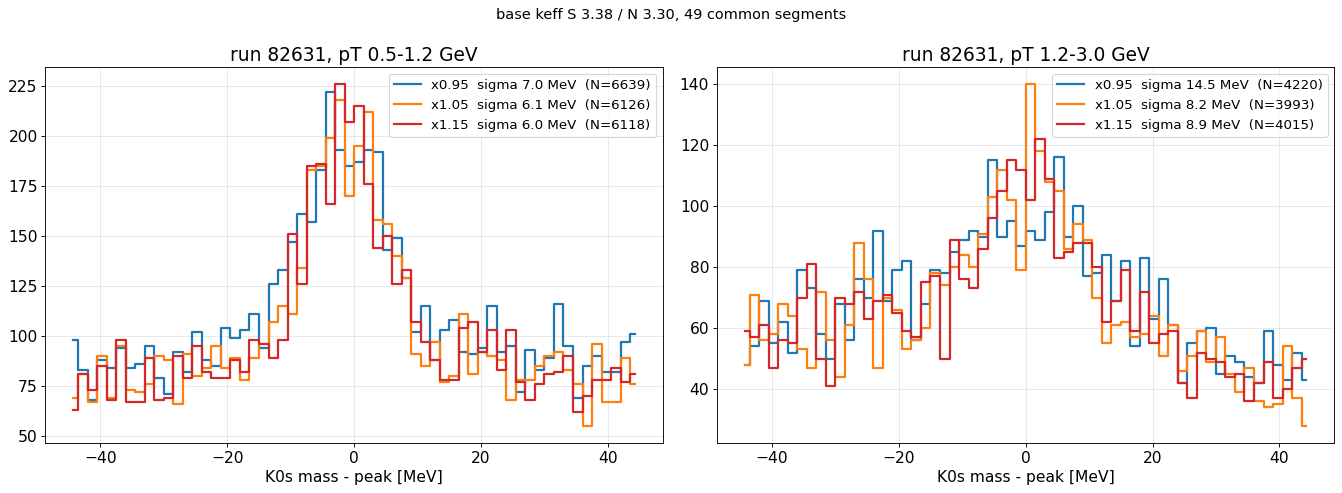

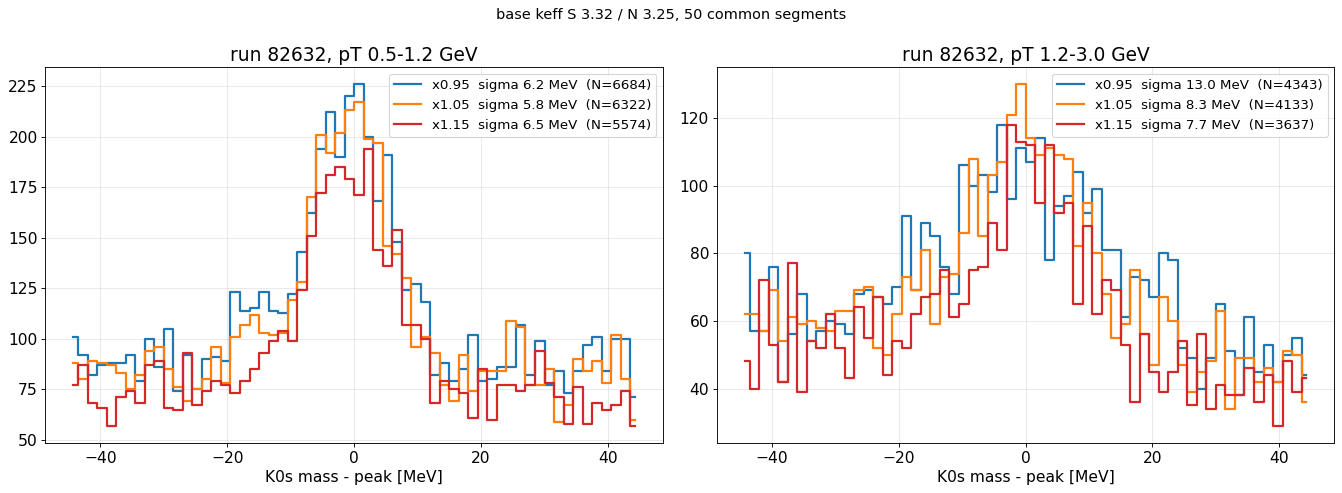

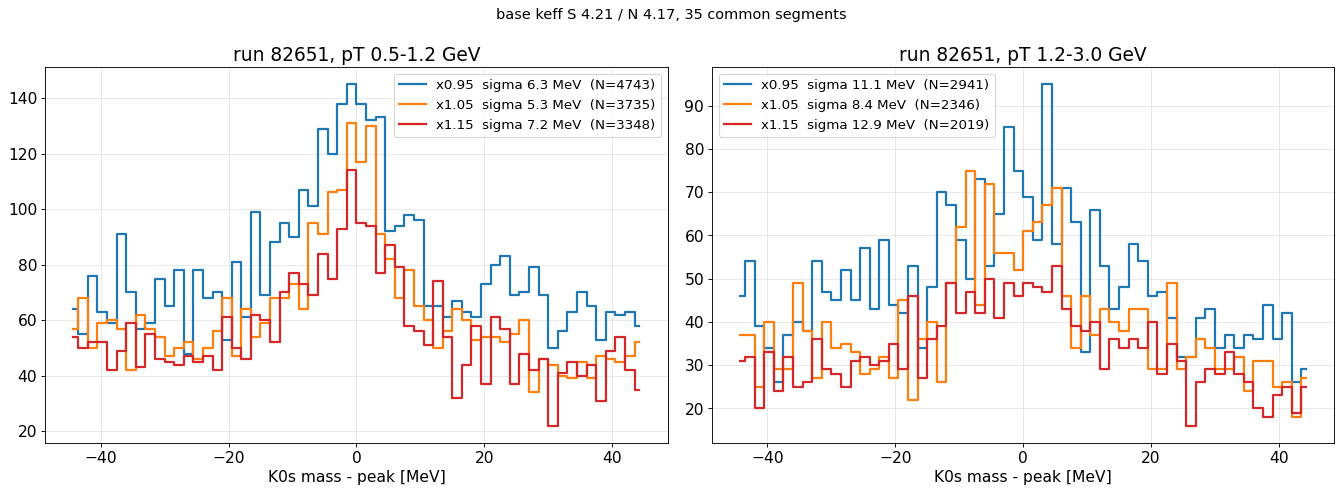

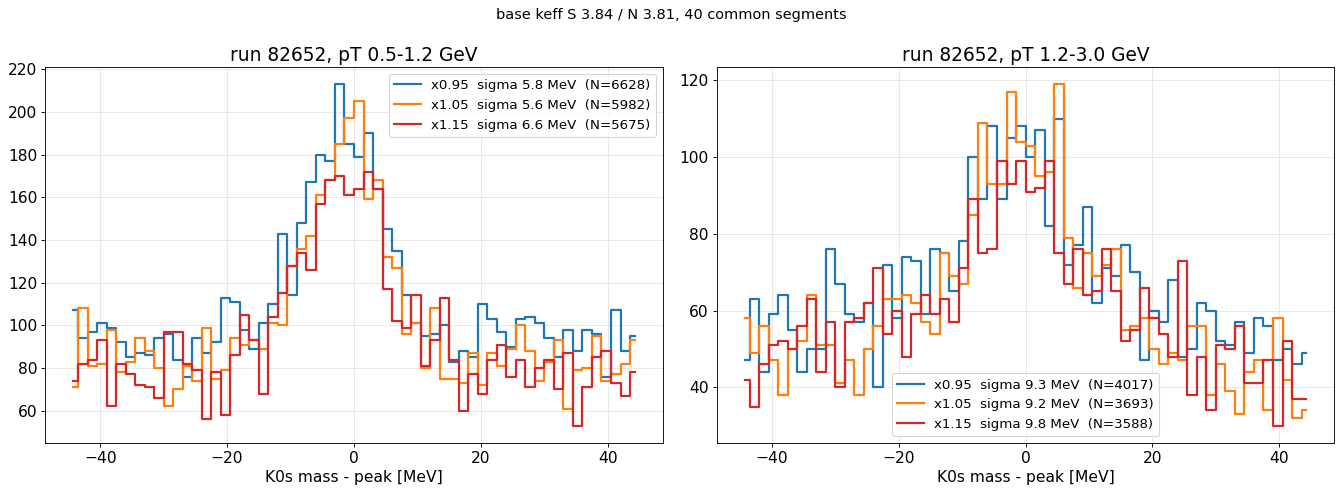

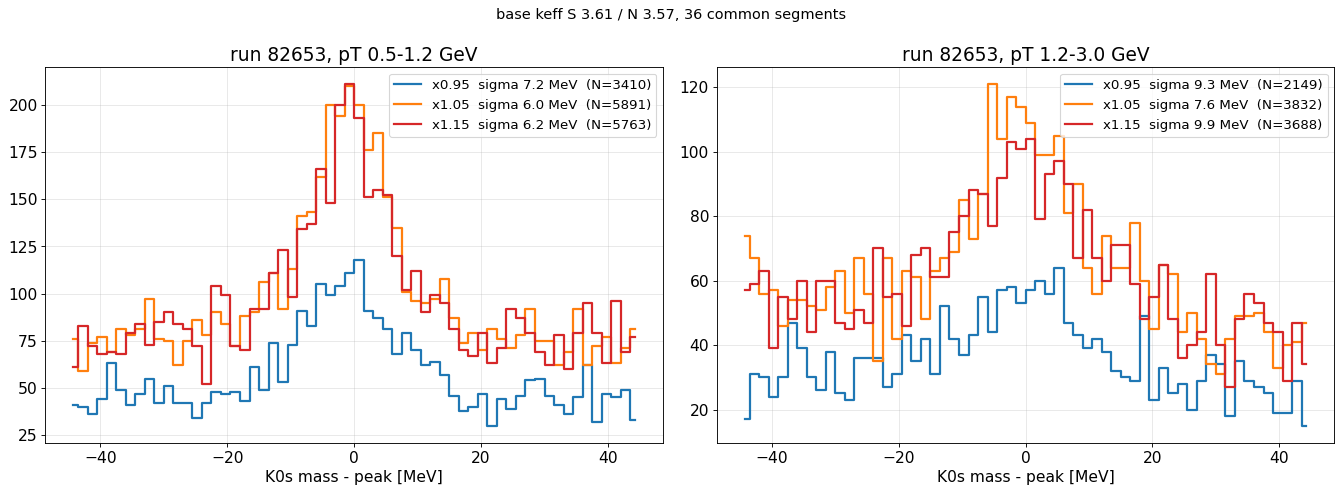

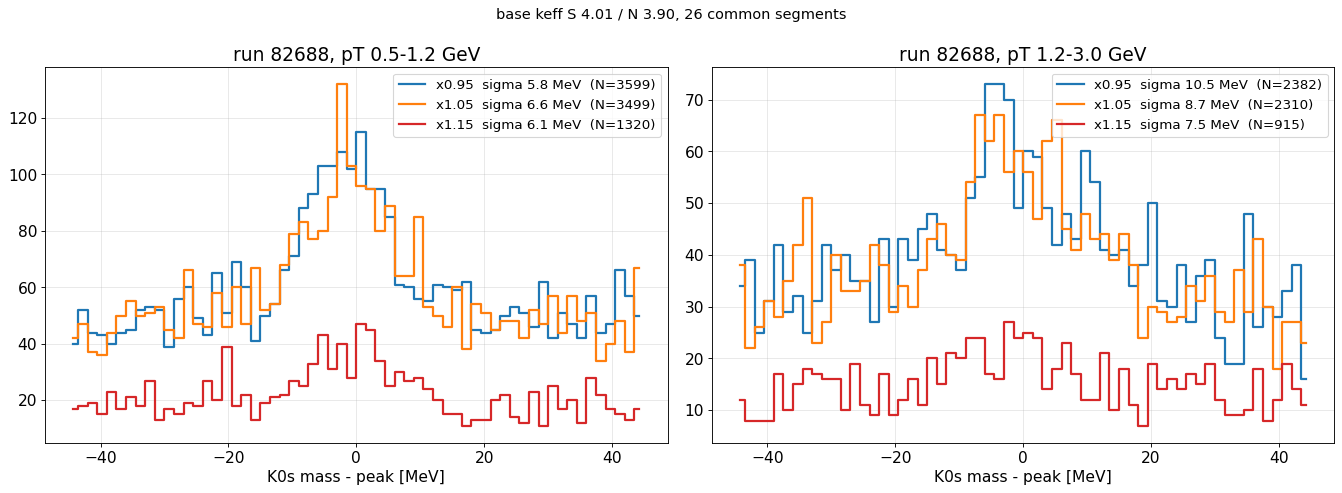

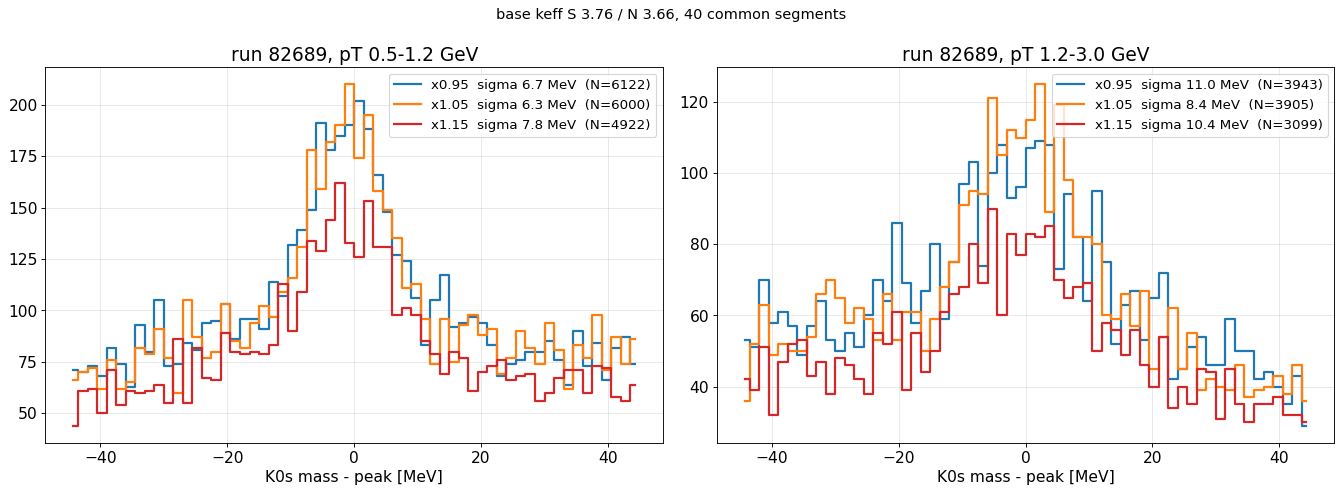

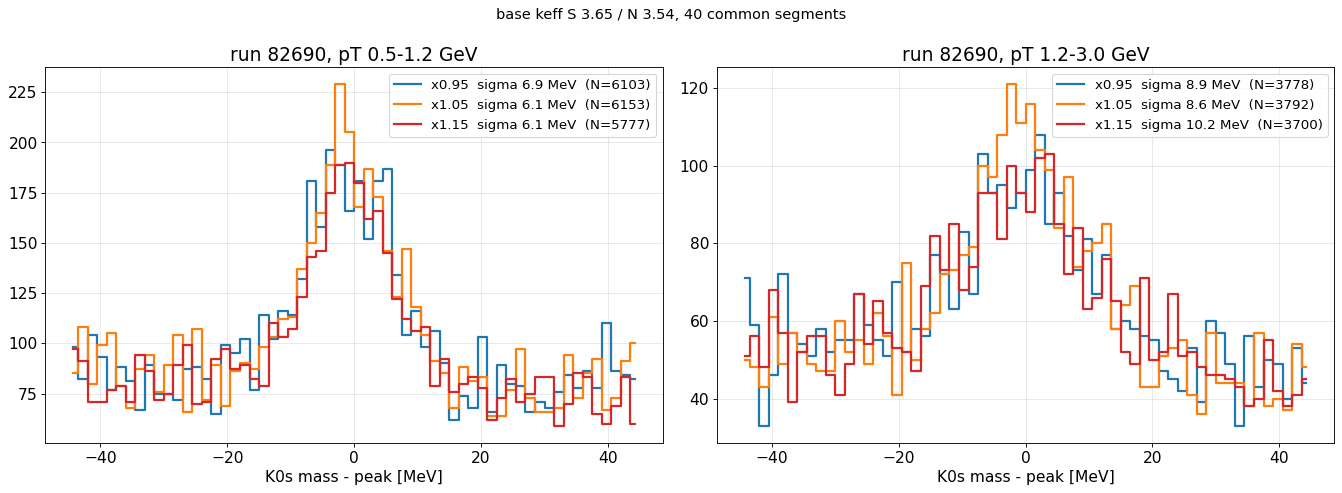

In [ ]:
from scipy.optimize import curve_fit
import os; PICS = Path('/home/yoren/yumvd.Yandex.Disk/Yura/Talks/Others/pics/261112/kscan_peaks'); os.makedirs(PICS, exist_ok=True)
HB, HH, CEN, NCOM = BAL['hb'], BAL['hist'], BAL['cen'], BAL['ncom']; hc = .5*(HB[1:] + HB[:-1])
def hsig(h):
    fn = lambda t, a, m, s, b0, b1: a*np.exp(-.5*((t - m)/s)**2) + b0 + b1*t
    try: p, _ = curve_fit(fn, hc, h, p0=[h.max(), 0, 7, max(h.min(), 0), 0], maxfev=4000); return abs(p[2])
    except Exception: return np.nan
plt.rcParams.update({'font.size': 14})
for i, r in enumerate(rb):
    fig, ax = plt.subplots(1, 2, figsize=(17, 6.3))
    for jj, (a, ttl) in enumerate(zip(ax, ('pT 0.5-1.2 GeV', 'pT 1.2-3.0 GeV'))):
        for j in range(3): a.step(hc, HH[i, j, jj], where='mid', lw=2, color=colr[j], label='x%.2f  sigma %.1f MeV  (N=%d)' % (fb[j], hsig(HH[i, j, jj]), HH[i, j, jj].sum()))
        a.set_xlabel('K0s mass - peak [MeV]'); a.set_title('run %d, %s' % (r, ttl)); a.legend(fontsize=12)
    fig.suptitle('base keff S %.2f / N %.2f, %d common segments' % (BAL['baseS'][i], BAL['baseN'][i], NCOM[i]), fontsize=13); fig.tight_layout(); fig.savefig(PICS/('peaks_%d.png' % r), dpi=60); plt.show()